In [70]:
print("hello world!")

hello world!


In [71]:

# ============================================================
# FORESIGHT — NOTEBOOK 07
# STEP 1: DATA PREPARATION AND VALIDATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# ------------------------------------------------------------
# 1. FIND PROJECT ROOT
# ------------------------------------------------------------

current_path = Path.cwd().resolve()

PROJECT_ROOT = None

for folder in [current_path, *current_path.parents]:

    if (
        (folder / "data").exists()
        and (folder / "models").exists()
        and (folder / "notebooks").exists()
    ):
        PROJECT_ROOT = folder
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the ForeSight project root."
    )

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "cleaned_household_transactions.csv"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Processed dataset not found: {DATA_PATH}"
    )

# ------------------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------------------

df = pd.read_csv(DATA_PATH)

df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
)

df["Amount"] = pd.to_numeric(
    df["Amount"],
    errors="coerce"
)

print("PROJECT ROOT:", PROJECT_ROOT)
print("ORIGINAL DATASET SHAPE:", df.shape)

# ------------------------------------------------------------
# 3. APPLY THE SAME HOUSEHOLD CONSUMPTION FILTER
# ------------------------------------------------------------

expense_df = df[
    df["Income/Expense"] == "Expense"
].copy()

financial_categories_strict = [
    "Money transfer",
    "Investment",
    "Public Provident Fund",
    "Recurring Deposit"
]

excluded_notes = [
    "Public Provident Fund",
    "Permanent Residence money transfer"
]

household_df = expense_df[
    (~expense_df["Category"].isin(
        financial_categories_strict
    ))
    &
    (~expense_df["Note"].isin(
        excluded_notes
    ))
].copy()

# Remove records without essential anomaly-analysis fields
household_df = household_df.dropna(
    subset=["Date", "Amount", "Category"]
).copy()

# ------------------------------------------------------------
# 4. VALIDATE DATA QUALITY
# ------------------------------------------------------------

if household_df.empty:
    raise ValueError(
        "No household consumption transactions found."
    )

if not np.isfinite(
    household_df["Amount"].to_numpy(dtype=float)
).all():
    raise ValueError(
        "Amount contains infinite or invalid values."
    )

if (household_df["Amount"] < 0).any():
    raise ValueError(
        "Negative expenses detected. Investigate before proceeding."
    )

# ------------------------------------------------------------
# 5. VERIFY RECONCILIATION WITH PREVIOUS NOTEBOOKS
# ------------------------------------------------------------

EXPECTED_TRANSACTIONS = 1996
EXPECTED_TOTAL = 936993.63

actual_transactions = len(household_df)
actual_total = household_df["Amount"].sum()

print("\nDATA RECONCILIATION")
print("-" * 45)

print("Expected transactions:", EXPECTED_TRANSACTIONS)
print("Actual transactions:", actual_transactions)

print("Expected total:", round(EXPECTED_TOTAL, 2))
print("Actual total:", round(actual_total, 2))

if actual_transactions != EXPECTED_TRANSACTIONS:
    raise ValueError(
        "Transaction count mismatch. Investigate filtering."
    )

if not np.isclose(
    actual_total,
    EXPECTED_TOTAL,
    atol=0.01
):
    raise ValueError(
        "Total expenditure mismatch. Investigate filtering."
    )

print("\nDATA RECONCILIATION PASSED")

# ------------------------------------------------------------
# 6. CREATE TRANSACTION-LEVEL DATASET
# ------------------------------------------------------------

transaction_df = household_df[
    [
        "Date",
        "Category",
        "Subcategory",
        "Note",
        "Amount"
    ]
].copy()

transaction_df = transaction_df.sort_values(
    "Date"
).reset_index(drop=True)

# ------------------------------------------------------------
# 7. CREATE WEEKLY SPENDING DATASET
# MONDAY TO SUNDAY
# ------------------------------------------------------------

household_df["Week"] = (
    household_df["Date"].dt.to_period("W-SUN")
)

weekly_spending = (
    household_df.groupby("Week")["Amount"]
    .sum()
)

all_weeks = pd.period_range(
    start=household_df["Week"].min(),
    end=household_df["Week"].max(),
    freq="W-SUN"
)

weekly_spending = weekly_spending.reindex(
    all_weeks,
    fill_value=0
)

weekly_df = weekly_spending.to_frame(
    name="Total_Spending"
)

weekly_df["Transaction_Count"] = (
    household_df.groupby("Week")
    .size()
    .reindex(all_weeks, fill_value=0)
)

# ------------------------------------------------------------
# 8. PRINT FINAL DATASET SUMMARY
# ------------------------------------------------------------

print("\nTRANSACTION DATASET")
print("-" * 45)

print("Transactions:", len(transaction_df))
print("Categories:", transaction_df["Category"].nunique())

print(
    "Date range:",
    transaction_df["Date"].min().date(),
    "to",
    transaction_df["Date"].max().date()
)

print(
    "Total spending: ₹",
    round(transaction_df["Amount"].sum(), 2)
)

print("\nWEEKLY DATASET")
print("-" * 45)

print("Total calendar weeks:", len(weekly_df))
print(
    "Active weeks:",
    int((weekly_df["Total_Spending"] > 0).sum())
)
print(
    "Zero-spending weeks:",
    int((weekly_df["Total_Spending"] == 0).sum())
)

print(
    "Highest weekly spending: ₹",
    round(weekly_df["Total_Spending"].max(), 2)
)

print("\nSTEP 1 COMPLETED")


PROJECT ROOT: C:\Users\singh\Desktop\foresight
ORIGINAL DATASET SHAPE: (2452, 9)

DATA RECONCILIATION
---------------------------------------------
Expected transactions: 1996
Actual transactions: 1996
Expected total: 936993.63
Actual total: 936993.63

DATA RECONCILIATION PASSED

TRANSACTION DATASET
---------------------------------------------
Transactions: 1996
Categories: 23
Date range: 2015-01-01 to 2018-12-09
Total spending: ₹ 936993.63

WEEKLY DATASET
---------------------------------------------
Total calendar weeks: 206
Active weeks: 193
Zero-spending weeks: 13
Highest weekly spending: ₹ 55597.0

STEP 1 COMPLETED


TRANSACTION SPENDING STATISTICS
Mean: ₹469.44
Median: ₹70.00
Standard Deviation: ₹2,240.27
Minimum: ₹2.00
Maximum: ₹50,000.00
Skewness: 15.139
Kurtosis: 275.768

PERCENTILE ANALYSIS
25th percentile: ₹30.00
50th percentile: ₹70.00
75th percentile: ₹251.00
90th percentile: ₹902.50
95th percentile: ₹2,000.00
99th percentile: ₹5,000.00


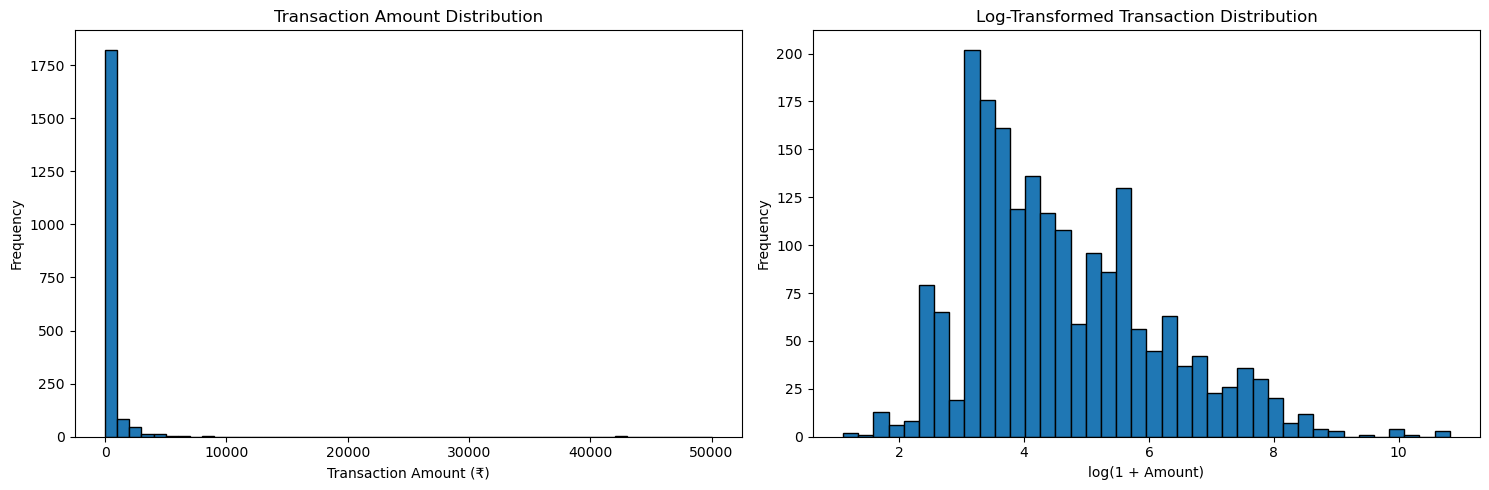

In [72]:

# ============================================================
# STEP 2: TRANSACTION SPENDING DISTRIBUTION
# ============================================================

amounts = transaction_df["Amount"]

print("TRANSACTION SPENDING STATISTICS")
print("=" * 55)

print(f"Mean: ₹{amounts.mean():,.2f}")
print(f"Median: ₹{amounts.median():,.2f}")
print(f"Standard Deviation: ₹{amounts.std():,.2f}")
print(f"Minimum: ₹{amounts.min():,.2f}")
print(f"Maximum: ₹{amounts.max():,.2f}")
print(f"Skewness: {amounts.skew():.3f}")
print(f"Kurtosis: {amounts.kurtosis():.3f}")

print("\nPERCENTILE ANALYSIS")
print("=" * 55)

percentiles = amounts.quantile(
    [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

for percentile, value in percentiles.items():
    print(f"{percentile * 100:.0f}th percentile: ₹{value:,.2f}")

# Visualize transaction distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(
    amounts,
    bins=50,
    edgecolor="black"
)
axes[0].set_title("Transaction Amount Distribution")
axes[0].set_xlabel("Transaction Amount (₹)")
axes[0].set_ylabel("Frequency")

axes[1].hist(
    np.log1p(amounts),
    bins=40,
    edgecolor="black"
)
axes[1].set_title("Log-Transformed Transaction Distribution")
axes[1].set_xlabel("log(1 + Amount)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


CATEGORY-WISE SPENDING SUMMARY


,Transaction_Count,Total_Spending,Mean,Median,Std,Maximum
Category,,,,,,
Transportation,307,169053.78,550.66,40.00,3798.17,50000.0
Household,176,161645.58,918.44,200.00,2623.75,21500.0
subscription,143,114587.91,801.31,251.00,2506.89,28400.0
Food,906,96393.10,106.39,45.00,194.46,2421.0
Family,71,78582.20,1106.79,500.00,1387.17,5000.0
Health,94,66252.75,704.82,150.50,2485.42,22700.0
Tourism,5,63608.85,12721.77,308.85,18973.19,43000.0
Other,111,57025.28,513.74,199.00,901.10,4720.0
Gift,30,40168.00,1338.93,574.50,1896.92,8029.0



CATEGORY DISTRIBUTION


,Count,Median,Q75,Q90,Q95,Maximum
Category,,,,,,
Cook,4,3333.50,5000.00,5000.0,5000.00,5000.0
Rent,4,2688.00,2833.00,2833.0,2833.00,2833.0
Self-development,2,1178.50,1292.75,1361.3,1384.15,1407.0
maid,17,1020.00,2000.00,2000.0,2000.00,2000.0
Gift,30,574.50,1309.25,3355.5,5735.00,8029.0
Family,71,500.00,1687.00,3000.0,5000.00,5000.0
Culture,11,436.00,471.18,560.0,660.00,760.0
Tourism,5,308.85,20000.00,33800.0,38400.00,43000.0
Festivals,16,306.00,500.00,900.0,1249.75,1999.0


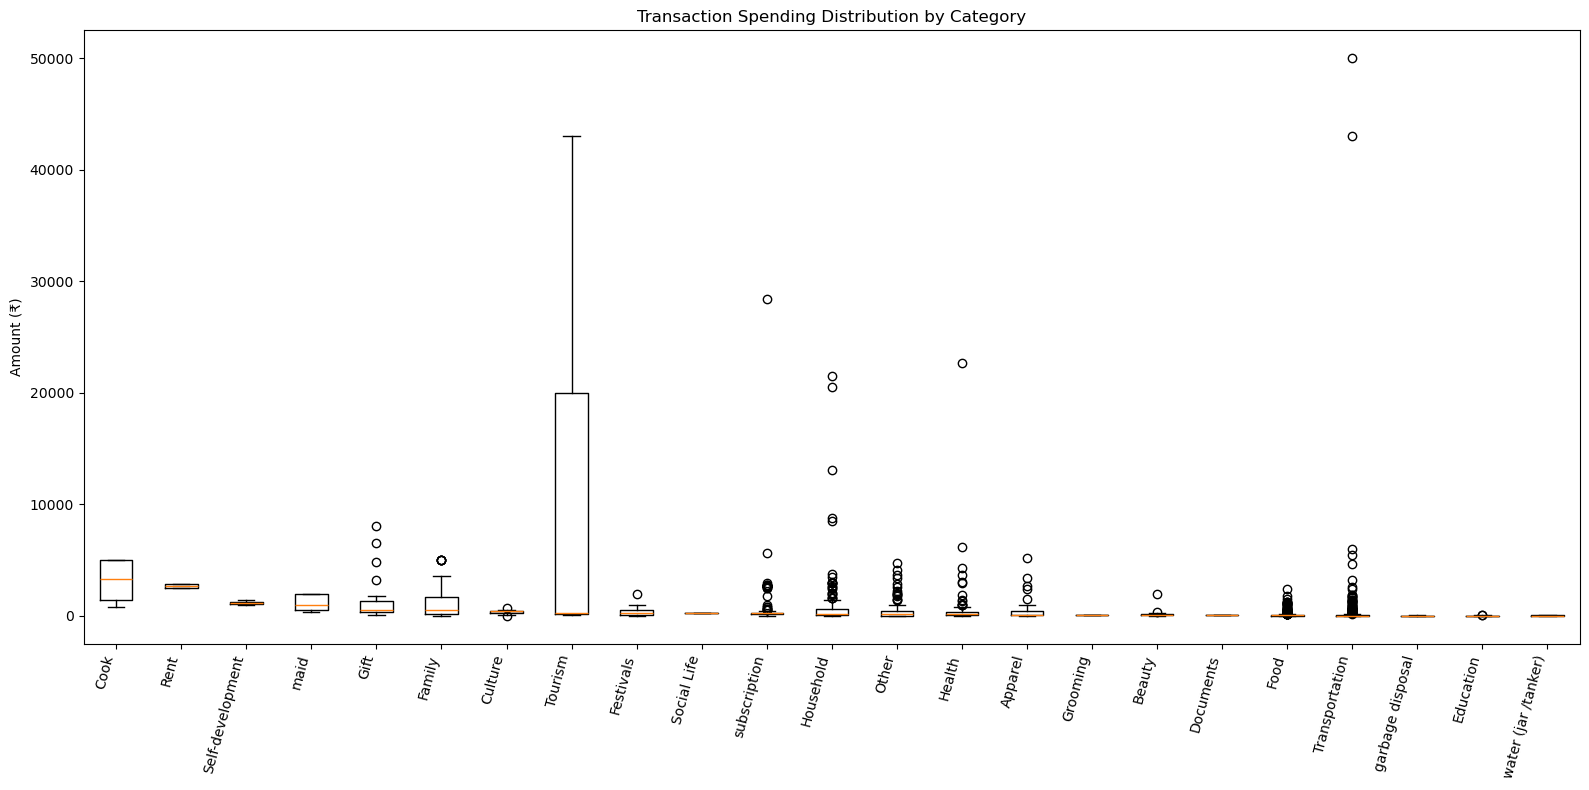

In [73]:

# ============================================================
# STEP 3: CATEGORY-WISE SPENDING ANALYSIS
# ============================================================

category_stats = (
    transaction_df.groupby("Category")["Amount"]
    .agg(
        Transaction_Count="count",
        Total_Spending="sum",
        Mean="mean",
        Median="median",
        Std="std",
        Maximum="max"
    )
    .sort_values("Total_Spending", ascending=False)
)

print("CATEGORY-WISE SPENDING SUMMARY")
display(
    category_stats.round(2)
)

# Category median and upper percentile
category_distribution = (
    transaction_df.groupby("Category")["Amount"]
    .agg(
        Count="count",
        Median="median",
        Q75=lambda x: x.quantile(0.75),
        Q90=lambda x: x.quantile(0.90),
        Q95=lambda x: x.quantile(0.95),
        Maximum="max"
    )
    .sort_values("Median", ascending=False)
)

print("\nCATEGORY DISTRIBUTION")
display(category_distribution.round(2))

# Boxplot by category
plt.figure(figsize=(16, 8))

category_order = (
    transaction_df.groupby("Category")["Amount"]
    .median()
    .sort_values(ascending=False)
    .index
)

plot_data = [
    transaction_df.loc[
        transaction_df["Category"] == category,
        "Amount"
    ].values
    for category in category_order
]

plt.boxplot(
    plot_data,
    tick_labels=category_order,
    showfliers=True
)

plt.xticks(rotation=75, ha="right")
plt.title("Transaction Spending Distribution by Category")
plt.ylabel("Amount (₹)")
plt.tight_layout()
plt.show()


TOP 25 HIGHEST-VALUE TRANSACTIONS


,Date,Category,Subcategory,Note,Amount
0,2018-01-18,Transportation,Bike,Two Wheeler Bikedelux second installment,50000.0
1,2018-01-27,Transportation,Bike,Two Wheeler Bikedelux third installment,43000.0
2,2017-08-08,Tourism,Trip,Tours and Travel,43000.0
3,2017-12-20,subscription,Edtech Course,Renewal,28400.0
4,2017-11-30,Health,Health,Family's Glasses,22700.0
5,2018-05-15,Household,Appliances,LG Washing Machine,21500.0
6,2016-11-28,Household,Appliances,Metz 32 inch TV,20500.0
7,2017-07-25,Tourism,Trip,Tours and Travel,20000.0
8,2018-06-26,Household,Appliances,Aqugurad water purifier,13050.0
9,2017-03-05,Household,Kitchen,Gas stove elica 3 burner,8825.0



HIGH-VALUE TRANSACTIONS BY CATEGORY


,Count,Total,Maximum
Category,,,
Transportation,4,104500.0,50000.0
Household,5,72375.0,21500.0
Tourism,2,63000.0,43000.0
subscription,2,34040.0,28400.0
Health,2,28890.0,22700.0
Family,5,25000.0,5000.0
Gift,2,14529.0,8029.0
Cook,2,10000.0,5000.0
Apparel,1,5200.0,5200.0


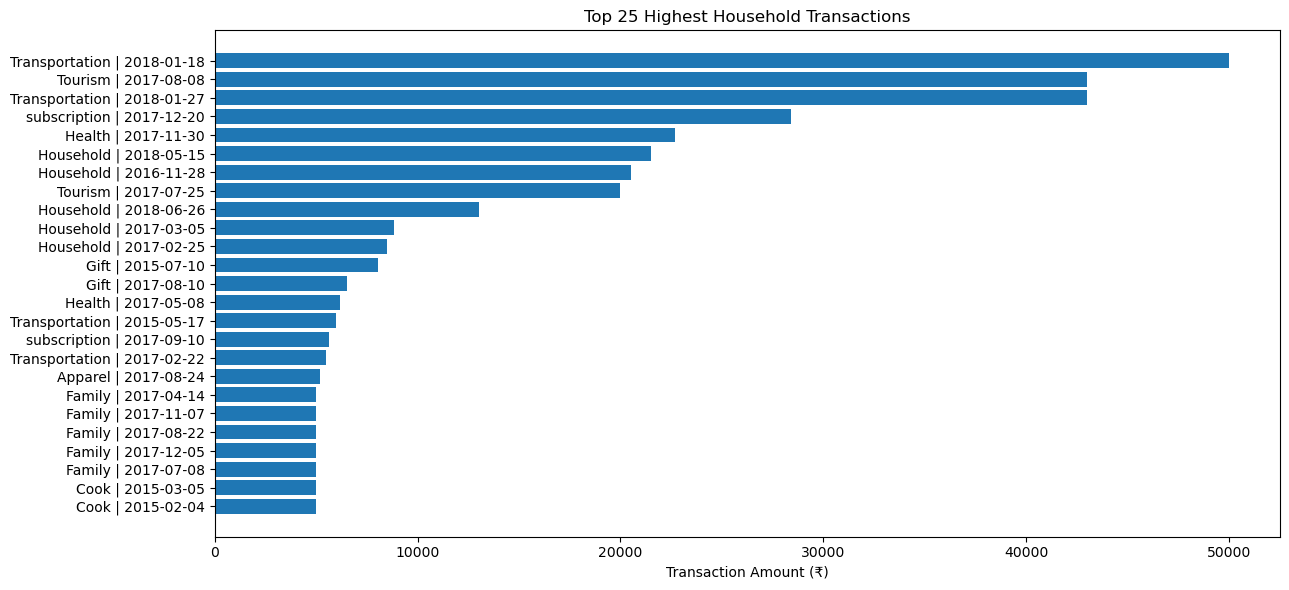

In [74]:

# ============================================================
# STEP 4: HIGH-VALUE TRANSACTION INVESTIGATION
# ============================================================

top_transactions = (
    transaction_df.sort_values(
        "Amount",
        ascending=False
    )
    .head(25)
    .copy()
)

print("TOP 25 HIGHEST-VALUE TRANSACTIONS")
display(
    top_transactions[
        ["Date", "Category", "Subcategory", "Note", "Amount"]
    ].reset_index(drop=True)
)

# Examine high transactions by category
high_transaction_summary = (
    top_transactions.groupby("Category")
    .agg(
        Count=("Amount", "count"),
        Total=("Amount", "sum"),
        Maximum=("Amount", "max")
    )
    .sort_values("Total", ascending=False)
)

print("\nHIGH-VALUE TRANSACTIONS BY CATEGORY")
display(high_transaction_summary.round(2))

# Show the top transactions visually
plt.figure(figsize=(13, 6))

top_plot = top_transactions.sort_values("Amount")

plt.barh(
    top_plot["Category"] + " | " +
    top_plot["Date"].dt.strftime("%Y-%m-%d"),
    top_plot["Amount"]
)

plt.xlabel("Transaction Amount (₹)")
plt.title("Top 25 Highest Household Transactions")
plt.tight_layout()
plt.show()


WEEKLY SPENDING STATISTICS
count      206.00
mean      4548.51
std       7986.50
min          0.00
25%        569.62
50%       2223.50
75%       4870.00
max      55597.00
Name: Total_Spending, dtype: float64

HIGHEST SPENDING WEEKS


,Week_Start,Total_Spending,Transaction_Count,Rolling_Median_8,Rolling_Mean_8
0,2017-08-07,55597.00,12,5600.50,7851.20
1,2018-01-15,52244.00,19,8000.00,11682.34
2,2018-01-22,46613.90,18,8625.34,18026.84
3,2017-12-18,32431.00,18,6316.00,8967.39
4,2017-07-24,30001.00,21,3732.55,4494.96
5,2017-11-27,29370.00,22,3399.23,4737.01
6,2017-02-27,28453.47,48,5081.00,6459.62
7,2018-06-25,26429.67,29,3534.50,6069.42
8,2018-05-14,23914.00,15,2999.00,3657.84
9,2016-11-28,21637.00,8,798.00,2317.02


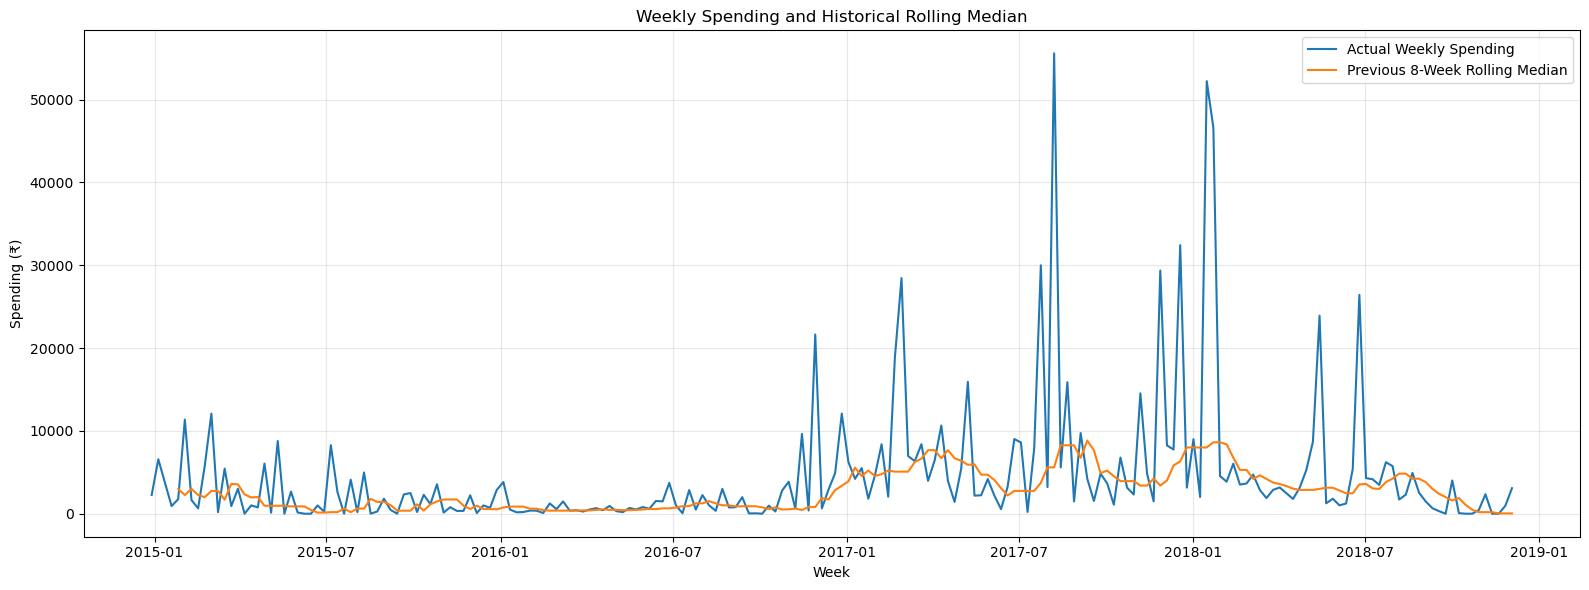

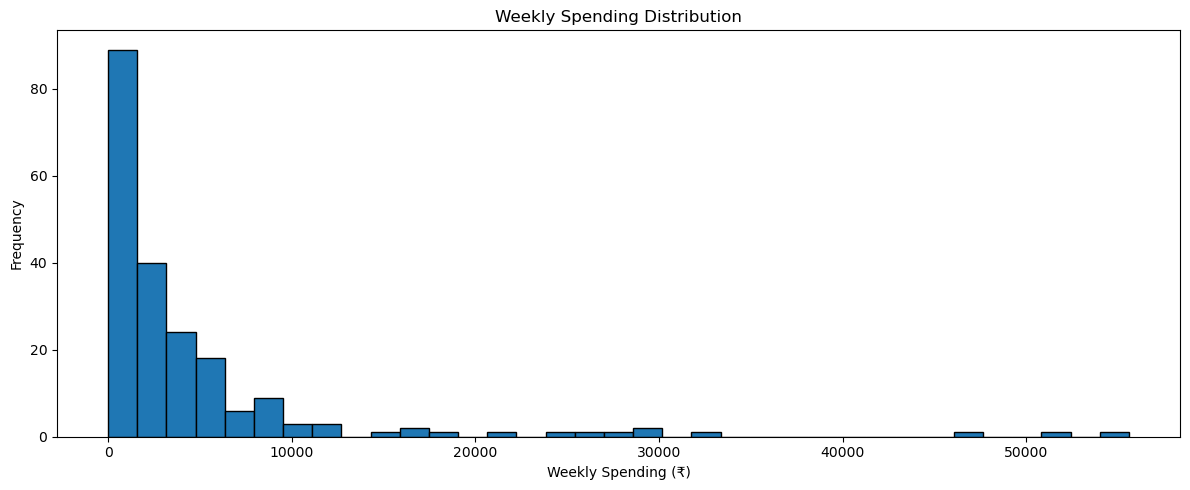

In [75]:

# ============================================================
# STEP 5: WEEKLY SPENDING BEHAVIOUR ANALYSIS
# ============================================================

weekly_analysis = weekly_df.copy()

weekly_analysis["Week_Start"] = (
    weekly_analysis.index
    .to_timestamp()
)

weekly_analysis["Rolling_Median_8"] = (
    weekly_analysis["Total_Spending"]
    .shift(1)
    .rolling(window=8, min_periods=4)
    .median()
)

weekly_analysis["Rolling_Mean_8"] = (
    weekly_analysis["Total_Spending"]
    .shift(1)
    .rolling(window=8, min_periods=4)
    .mean()
)

weekly_analysis["Rolling_Std_8"] = (
    weekly_analysis["Total_Spending"]
    .shift(1)
    .rolling(window=8, min_periods=4)
    .std()
)

print("WEEKLY SPENDING STATISTICS")
print("=" * 55)

print(
    weekly_analysis["Total_Spending"].describe().round(2)
)

print("\nHIGHEST SPENDING WEEKS")

display(
    weekly_analysis.nlargest(
        15,
        "Total_Spending"
    )[
        [
            "Week_Start",
            "Total_Spending",
            "Transaction_Count",
            "Rolling_Median_8",
            "Rolling_Mean_8"
        ]
    ].reset_index(drop=True).round(2)
)

# Weekly spending time series
plt.figure(figsize=(16, 6))

plt.plot(
    weekly_analysis["Week_Start"],
    weekly_analysis["Total_Spending"],
    label="Actual Weekly Spending"
)

plt.plot(
    weekly_analysis["Week_Start"],
    weekly_analysis["Rolling_Median_8"],
    label="Previous 8-Week Rolling Median"
)

plt.title("Weekly Spending and Historical Rolling Median")
plt.xlabel("Week")
plt.ylabel("Spending (₹)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Weekly spending distribution
plt.figure(figsize=(12, 5))

plt.hist(
    weekly_analysis["Total_Spending"],
    bins=35,
    edgecolor="black"
)

plt.title("Weekly Spending Distribution")
plt.xlabel("Weekly Spending (₹)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


In [76]:

# ============================================================
# STEP 6: TRANSACTION-LEVEL ROBUST MAD DETECTION
# ============================================================

MIN_CATEGORY_SAMPLES = 20
ROBUST_Z_THRESHOLD = 3.5

transaction_detection = transaction_df.copy()

category_results = []

for category, group in transaction_detection.groupby("Category"):

    values = group["Amount"]

    count = len(values)
    median_value = values.median()

    mad_value = np.median(
        np.abs(values - median_value)
    )

    q95_value = values.quantile(0.95)

    if count >= MIN_CATEGORY_SAMPLES and mad_value > 0:

        robust_scale = 1.4826 * mad_value

        robust_z = (
            0.6745 * (values - median_value) / mad_value
        )

        for idx, score in zip(group.index, robust_z):

            category_results.append({
                "Index": idx,
                "Category_Median": median_value,
                "Category_MAD": mad_value,
                "Category_Robust_Z": score,
                "Category_Q95": q95_value,
                "Baseline_Available": True
            })

    else:

        for idx in group.index:

            category_results.append({
                "Index": idx,
                "Category_Median": median_value,
                "Category_MAD": mad_value,
                "Category_Robust_Z": np.nan,
                "Category_Q95": q95_value,
                "Baseline_Available": False
            })

category_results_df = pd.DataFrame(category_results).set_index(
    "Index"
)

transaction_detection = transaction_detection.join(
    category_results_df
)

# Global percentile baseline
GLOBAL_P99 = transaction_detection["Amount"].quantile(0.99)

transaction_detection["Global_P99_Flag"] = (
    transaction_detection["Amount"] > GLOBAL_P99
)

# Category-specific percentile baseline
transaction_detection["Category_Q95_Flag"] = (
    transaction_detection["Baseline_Available"]
    &
    (transaction_detection["Amount"] > transaction_detection["Category_Q95"])
)

# Category-specific robust MAD detector
transaction_detection["Robust_MAD_Flag"] = (
    transaction_detection["Baseline_Available"]
    &
    (transaction_detection["Category_Robust_Z"] > ROBUST_Z_THRESHOLD)
)

print("TRANSACTION ANOMALY DETECTION SUMMARY")
print("=" * 55)

print("Global 99th percentile:", round(GLOBAL_P99, 2))

print(
    "Eligible categories:",
    transaction_detection.loc[
        transaction_detection["Baseline_Available"],
        "Category"
    ].nunique()
)

print(
    "Global P99 candidates:",
    int(transaction_detection["Global_P99_Flag"].sum())
)

print(
    "Category Q95 candidates:",
    int(transaction_detection["Category_Q95_Flag"].sum())
)

print(
    "Robust MAD candidates:",
    int(transaction_detection["Robust_MAD_Flag"].sum())
)

print("\nROBUST MAD CANDIDATES")

display(
    transaction_detection[
        transaction_detection["Robust_MAD_Flag"]
    ][
        [
            "Date",
            "Category",
            "Note",
            "Amount",
            "Category_Median",
            "Category_Robust_Z"
        ]
    ].sort_values(
        "Category_Robust_Z",
        ascending=False
    ).round(2)
)


TRANSACTION ANOMALY DETECTION SUMMARY
Global 99th percentile: 5000.0
Eligible categories: 10
Global P99 candidates: 18
Category Q95 candidates: 94
Robust MAD candidates: 311

ROBUST MAD CANDIDATES


,Date,Category,Note,Amount,Category_Median,Category_Robust_Z
1478,2018-01-18,Transportation,Two Wheeler Bikedelux second installment,50000.0,40.0,1684.90
1501,2018-01-27,Transportation,Two Wheeler Bikedelux third installment,43000.0,40.0,1448.83
1408,2017-12-20,subscription,Renewal,28400.0,251.0,271.24
196,2015-05-17,Transportation,BR to mumbai,6000.0,40.0,201.00
646,2017-02-22,Transportation,Place 2 to Place 1,5500.0,40.0,184.14
...,...,...,...,...,...,...
1060,2017-07-30,Household,Laptop repair,1000.0,200.0,3.59
920,2017-05-28,Household,No Note,996.0,200.0,3.57
796,2017-04-12,Household,Supermart,990.0,200.0,3.54
1000,2017-07-01,Food,woffel,175.0,45.0,3.51


WEEKLY ANOMALY DETECTION SUMMARY
Total calendar weeks: 206
Evaluated weeks: 198
Unevaluated weeks: 8
Detected anomaly candidates: 37

WEEKLY ANOMALY CANDIDATES


,Week_Start,Total_Spending,Transaction_Count,Historical_Median,Historical_MAD,Weekly_Robust_Z
2018-12-03/2018-12-09,2018-12-03,3083.00,11,35.50,35.50,57.90
2015-07-06/2015-07-12,2015-07-06,8280.00,2,190.50,190.50,28.64
2016-11-28/2016-12-04,2016-11-28,21637.00,8,798.00,663.00,21.20
2018-11-26/2018-12-02,2018-11-26,954.00,5,35.50,35.50,17.45
2018-05-14/2018-05-20,2018-05-14,23914.00,15,2999.00,818.62,17.23
2016-11-14/2016-11-20,2016-11-14,9637.00,22,448.50,432.00,14.35
2015-07-27/2015-08-02,2015-07-27,4106.00,6,190.50,190.50,13.86
2018-05-07/2018-05-13,2018-05-07,8692.00,19,2876.00,344.00,11.40
2017-08-07/2017-08-13,2017-08-07,55597.00,12,5600.50,3210.30,10.50
2017-11-27/2017-12-03,2017-11-27,29370.00,22,3399.23,1697.00,10.32


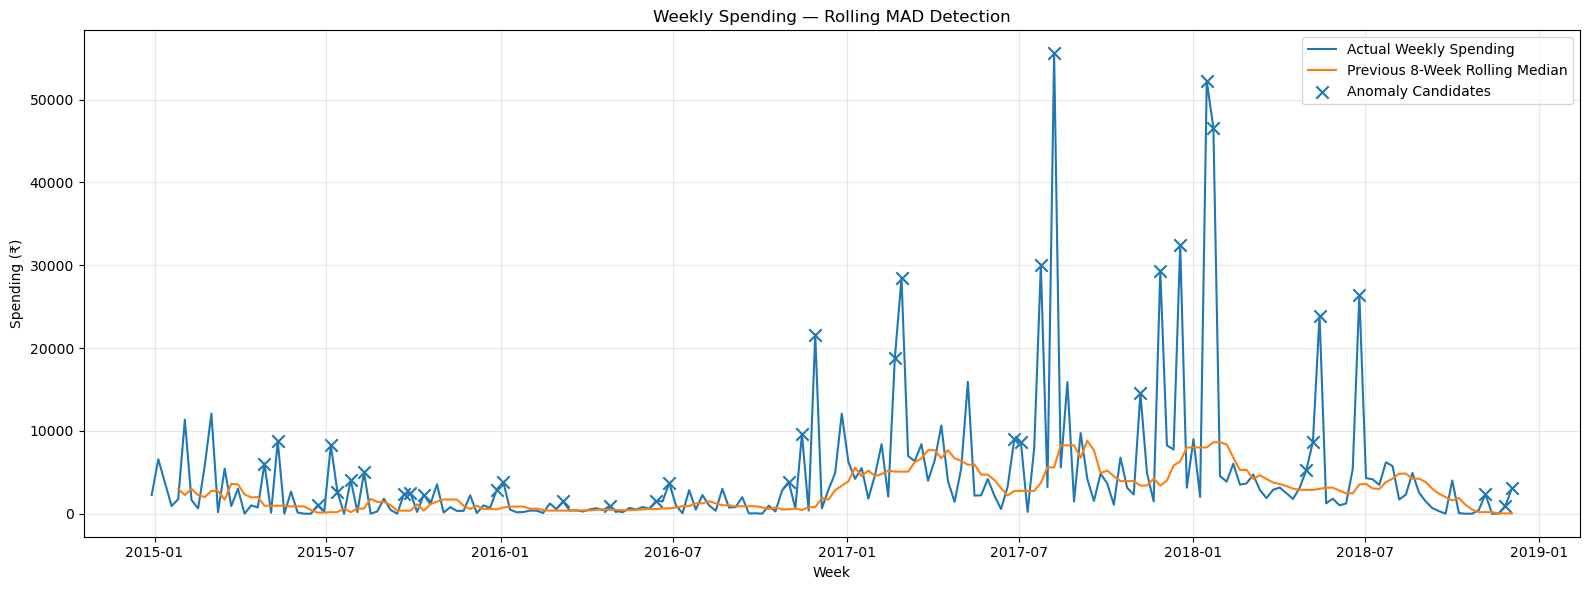

In [77]:

# ============================================================
# STEP 7: WEEKLY ROLLING MAD ANOMALY DETECTION
# ============================================================

WEEKLY_WINDOW = 8
MIN_HISTORY = 4
WEEKLY_Z_THRESHOLD = 3.5

weekly_detection = weekly_analysis.copy()

# ------------------------------------------------------------
# 1. USE ONLY PREVIOUS WEEKS
# ------------------------------------------------------------

historical_spending = (
    weekly_detection["Total_Spending"].shift(1)
)

# ------------------------------------------------------------
# 2. CALCULATE HISTORICAL ROLLING MEDIAN
# ------------------------------------------------------------

weekly_detection["Historical_Median"] = (
    historical_spending
    .rolling(
        window=WEEKLY_WINDOW,
        min_periods=MIN_HISTORY
    )
    .median()
)

# ------------------------------------------------------------
# 3. CALCULATE HISTORICAL ROLLING MAD
# ------------------------------------------------------------

weekly_detection["Historical_MAD"] = (
    historical_spending
    .rolling(
        window=WEEKLY_WINDOW,
        min_periods=MIN_HISTORY
    )
    .apply(
        lambda x: np.median(
            np.abs(x - np.median(x))
        ),
        raw=True
    )
)

# ------------------------------------------------------------
# 4. CALCULATE ROBUST SCALE
# ------------------------------------------------------------

weekly_detection["Historical_Robust_Scale"] = (
    1.4826 * weekly_detection["Historical_MAD"]
)

# Prevent division by zero
weekly_detection["Historical_Robust_Scale"] = (
    weekly_detection["Historical_Robust_Scale"]
    .replace(0, np.nan)
)

# ------------------------------------------------------------
# 5. CALCULATE ROBUST Z-SCORE
# ------------------------------------------------------------

weekly_detection["Weekly_Robust_Z"] = (
    (
        weekly_detection["Total_Spending"]
        - weekly_detection["Historical_Median"]
    )
    / weekly_detection["Historical_Robust_Scale"]
)

# ------------------------------------------------------------
# 6. DETECT UNUSUALLY HIGH SPENDING
# ------------------------------------------------------------

weekly_detection["Weekly_Anomaly_Flag"] = (
    weekly_detection["Weekly_Robust_Z"]
    > WEEKLY_Z_THRESHOLD
)

# Exclude weeks without sufficient historical information
weekly_detection["Weekly_Anomaly_Flag"] = (
    weekly_detection["Weekly_Anomaly_Flag"]
    & weekly_detection["Weekly_Robust_Z"].notna()
)

# ------------------------------------------------------------
# 7. DISPLAY RESULTS
# ------------------------------------------------------------

print("WEEKLY ANOMALY DETECTION SUMMARY")
print("=" * 55)

print(
    "Total calendar weeks:",
    len(weekly_detection)
)

print(
    "Evaluated weeks:",
    int(weekly_detection["Weekly_Robust_Z"].notna().sum())
)

print(
    "Unevaluated weeks:",
    int(weekly_detection["Weekly_Robust_Z"].isna().sum())
)

print(
    "Detected anomaly candidates:",
    int(weekly_detection["Weekly_Anomaly_Flag"].sum())
)

print("\nWEEKLY ANOMALY CANDIDATES")

display(
    weekly_detection[
        weekly_detection["Weekly_Anomaly_Flag"]
    ][
        [
            "Week_Start",
            "Total_Spending",
            "Transaction_Count",
            "Historical_Median",
            "Historical_MAD",
            "Weekly_Robust_Z"
        ]
    ]
    .sort_values(
        "Weekly_Robust_Z",
        ascending=False
    )
    .round(2)
)

# ------------------------------------------------------------
# 8. VISUALIZE DETECTED WEEKS
# ------------------------------------------------------------

plt.figure(figsize=(16, 6))

plt.plot(
    weekly_detection["Week_Start"],
    weekly_detection["Total_Spending"],
    label="Actual Weekly Spending"
)

plt.plot(
    weekly_detection["Week_Start"],
    weekly_detection["Historical_Median"],
    label="Previous 8-Week Rolling Median"
)

anomaly_weeks = weekly_detection[
    weekly_detection["Weekly_Anomaly_Flag"]
]

plt.scatter(
    anomaly_weeks["Week_Start"],
    anomaly_weeks["Total_Spending"],
    marker="x",
    s=80,
    label="Anomaly Candidates"
)

plt.title("Weekly Spending — Rolling MAD Detection")
plt.xlabel("Week")
plt.ylabel("Spending (₹)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [78]:

# ============================================================
# STEP 8: TRANSACTION DETECTOR COMPARISON
# ============================================================

comparison = pd.DataFrame({
    "Method": [
        "Global 99th Percentile",
        "Category 95th Percentile",
        "Category Robust MAD"
    ],
    "Detected_Candidates": [
        transaction_detection["Global_P99_Flag"].sum(),
        transaction_detection["Category_Q95_Flag"].sum(),
        transaction_detection["Robust_MAD_Flag"].sum()
    ]
})

comparison["Percentage_of_Transactions"] = (
    comparison["Detected_Candidates"]
    / len(transaction_detection)
    * 100
)

print("DETECTION METHOD COMPARISON")
display(comparison.round(2))

# Compare overlapping detections
overlap = pd.crosstab(
    transaction_detection["Global_P99_Flag"],
    transaction_detection["Robust_MAD_Flag"],
    rownames=["Global P99"],
    colnames=["Robust MAD"]
)

print("\nGLOBAL P99 VS ROBUST MAD OVERLAP")
display(overlap)

# Category-level comparison
category_comparison = (
    transaction_detection.groupby("Category")
    .agg(
        Transactions=("Amount", "count"),
        Global_P99_Alerts=("Global_P99_Flag", "sum"),
        Category_Q95_Alerts=("Category_Q95_Flag", "sum"),
        Robust_MAD_Alerts=("Robust_MAD_Flag", "sum")
    )
    .sort_values("Robust_MAD_Alerts", ascending=False)
)

print("\nCATEGORY-WISE DETECTION COMPARISON")
display(category_comparison)


DETECTION METHOD COMPARISON


,Method,Detected_Candidates,Percentage_of_Transactions
0,Global 99th Percentile,18,0.90
1,Category 95th Percentile,94,4.71
2,Category Robust MAD,311,15.58



GLOBAL P99 VS ROBUST MAD OVERLAP


Robust MAD,False,True
Global P99,,
False,1683,295
True,2,16



CATEGORY-WISE DETECTION COMPARISON


,Transactions,Global_P99_Alerts,Category_Q95_Alerts,Robust_MAD_Alerts
Category,,,,
Food,906,0,46,134
Transportation,307,4,16,64
Household,176,5,8,33
subscription,143,2,6,27
Other,111,0,6,15
Health,94,2,5,14
Apparel,47,1,3,10
Family,71,0,0,8
Gift,30,2,2,4


In [79]:

# ============================================================
# STEP 9: MANUAL ANOMALY CANDIDATE REVIEW
# ============================================================

print("TOP TRANSACTION ANOMALY CANDIDATES")
print("=" * 55)

review_transactions = (
    transaction_detection[
        transaction_detection["Robust_MAD_Flag"]
    ]
    .sort_values(
        "Category_Robust_Z",
        ascending=False
    )
    .head(30)
)

display(
    review_transactions[
        [
            "Date",
            "Category",
            "Subcategory",
            "Note",
            "Amount",
            "Category_Median",
            "Category_Robust_Z"
        ]
    ].round(2)
)

print("\nTOP WEEKLY ANOMALY CANDIDATES")
print("=" * 55)

review_weeks = (
    weekly_detection[
        weekly_detection["Weekly_Anomaly_Flag"]
    ]
    .sort_values(
        "Weekly_Robust_Z",
        ascending=False
    )
    .head(20)
)

display(
    review_weeks[
        [
            "Week_Start",
            "Total_Spending",
            "Transaction_Count",
            "Historical_Median",
            "Weekly_Robust_Z"
        ]
    ].round(2)
)


TOP TRANSACTION ANOMALY CANDIDATES


,Date,Category,Subcategory,Note,Amount,Category_Median,Category_Robust_Z
1478,2018-01-18,Transportation,Bike,Two Wheeler Bikedelux second installment,50000.00,40.0,1684.90
1501,2018-01-27,Transportation,Bike,Two Wheeler Bikedelux third installment,43000.00,40.0,1448.83
1408,2017-12-20,subscription,Edtech Course,Renewal,28400.00,251.0,271.24
196,2015-05-17,Transportation,Taxi,BR to mumbai,6000.00,40.0,201.00
646,2017-02-22,Transportation,Taxi,Place 2 to Place 1,5500.00,40.0,184.14
484,2016-11-14,Transportation,Travels,Kabra Travels - Place 2 to BRC (2 Adults),4662.00,40.0,155.88
1360,2017-11-30,Health,Health,Family's Glasses,22700.00,150.5,129.44
406,2016-06-27,Transportation,Travels,Chalisgaon to Baroda return,3200.00,40.0,106.57
1737,2018-05-15,Household,Appliances,LG Washing Machine,21500.00,200.0,95.46
510,2016-11-28,Household,Appliances,Metz 32 inch TV,20500.00,200.0,90.98



TOP WEEKLY ANOMALY CANDIDATES


,Week_Start,Total_Spending,Transaction_Count,Historical_Median,Weekly_Robust_Z
2018-12-03/2018-12-09,2018-12-03,3083.00,11,35.50,57.90
2015-07-06/2015-07-12,2015-07-06,8280.00,2,190.50,28.64
2016-11-28/2016-12-04,2016-11-28,21637.00,8,798.00,21.20
2018-11-26/2018-12-02,2018-11-26,954.00,5,35.50,17.45
2018-05-14/2018-05-20,2018-05-14,23914.00,15,2999.00,17.23
2016-11-14/2016-11-20,2016-11-14,9637.00,22,448.50,14.35
2015-07-27/2015-08-02,2015-07-27,4106.00,6,190.50,13.86
2018-05-07/2018-05-13,2018-05-07,8692.00,19,2876.00,11.40
2017-08-07/2017-08-13,2017-08-07,55597.00,12,5600.50,10.50
2017-11-27/2017-12-03,2017-11-27,29370.00,22,3399.23,10.32


In [80]:

# ============================================================
# STEP 10: CATEGORY MAD DIAGNOSTICS
# ============================================================

category_diagnostics = (
    transaction_detection.groupby("Category")
    .agg(
        Transactions=("Amount", "count"),
        Median=("Category_Median", "first"),
        MAD=("Category_MAD", "first"),
        MAD_Alerts=("Robust_MAD_Flag", "sum"),
        Alert_Rate=("Robust_MAD_Flag", "mean")
    )
    .sort_values("MAD_Alerts", ascending=False)
)

category_diagnostics["Alert_Rate"] *= 100

print("CATEGORY MAD DIAGNOSTICS")
display(category_diagnostics.round(2))

print("\nCATEGORIES WITH HIGHEST ALERT RATES")

display(
    category_diagnostics[
        category_diagnostics["MAD_Alerts"] > 0
    ].sort_values(
        "Alert_Rate",
        ascending=False
    )
)


CATEGORY MAD DIAGNOSTICS


,Transactions,Median,MAD,MAD_Alerts,Alert_Rate
Category,,,,,
Food,906,45.00,25.00,134,14.79
Transportation,307,40.00,20.00,64,20.85
Household,176,200.00,150.50,33,18.75
subscription,143,251.00,70.00,27,18.88
Other,111,199.00,169.00,15,13.51
Health,94,150.50,117.50,14,14.89
Apparel,47,100.00,90.00,10,21.28
Family,71,500.00,430.00,8,11.27
Gift,30,574.50,400.00,4,13.33



CATEGORIES WITH HIGHEST ALERT RATES


,Transactions,Median,MAD,MAD_Alerts,Alert_Rate
Category,,,,,
Apparel,47,100.0,90.0,10,21.276596
Transportation,307,40.0,20.0,64,20.846906
subscription,143,251.0,70.0,27,18.881119
Household,176,200.0,150.5,33,18.750000
Health,94,150.5,117.5,14,14.893617
Food,906,45.0,25.0,134,14.790287
Other,111,199.0,169.0,15,13.513514
Gift,30,574.5,400.0,4,13.333333
Family,71,500.0,430.0,8,11.267606


In [81]:

# ============================================================
# STEP 11: WEEKLY BASELINE DIAGNOSTICS
# ============================================================

weekly_diagnostic_rows = []

for position in range(len(weekly_detection)):

    current = weekly_detection.iloc[position]

    if not current["Weekly_Anomaly_Flag"]:
        continue

    history = weekly_detection.iloc[
        max(0, position - WEEKLY_WINDOW):position
    ]["Total_Spending"]

    weekly_diagnostic_rows.append({
        "Week": current["Week_Start"],
        "Current_Spending": current["Total_Spending"],
        "Historical_Median": current["Historical_Median"],
        "Historical_MAD": current["Historical_MAD"],
        "Robust_Z": current["Weekly_Robust_Z"],
        "History_Min": history.min(),
        "History_Max": history.max(),
        "History_Mean": history.mean(),
        "History_Values": history.tolist()
    })

weekly_baseline_diagnostics = pd.DataFrame(
    weekly_diagnostic_rows
)

print("WEEKLY ANOMALY BASELINE INVESTIGATION")

display(
    weekly_baseline_diagnostics.sort_values(
        "Robust_Z",
        ascending=False
    ).round(2)
)


WEEKLY ANOMALY BASELINE INVESTIGATION


,Week,Current_Spending,Historical_Median,Historical_MAD,Robust_Z,History_Min,History_Max,History_Mean,History_Values
36,2018-12-03,3083.00,35.50,35.50,57.90,0.0,2350.0,477.62,"[71.0, 0.0, 0.0, 446.0, 2350.0, 0.0, 0.0, 954.0]"
3,2015-07-06,8280.00,190.50,190.50,28.64,0.0,8779.0,1603.75,"[8779.0, 0.0, 2671.0, 145.0, 0.0, 0.0, 999.0, ..."
18,2016-11-28,21637.00,798.00,663.00,21.20,0.0,9637.0,2317.02,"[0.0, 969.0, 270.0, 2788.2, 3859.0, 627.0, 963..."
35,2018-11-26,954.00,35.50,35.50,17.45,0.0,4012.0,859.88,"[4012.0, 71.0, 0.0, 0.0, 446.0, 2350.0, 0.0, 0.0]"
32,2018-05-14,23914.00,2999.00,818.62,17.23,1785.0,8692.0,3657.84,"[1882.75, 2883.0, 3166.0, 2478.0, 1785.0, 3115..."
17,2016-11-14,9637.00,448.50,432.00,14.35,0.0,3859.0,1074.15,"[33.0, 47.0, 0.0, 969.0, 270.0, 2788.2, 3859.0..."
5,2015-07-27,4106.00,190.50,190.50,13.86,0.0,8280.0,1532.38,"[145.0, 0.0, 0.0, 999.0, 236.0, 8280.0, 2599.0..."
31,2018-05-07,8692.00,2876.00,344.00,11.40,1785.0,5261.0,2929.97,"[2869.0, 1882.75, 2883.0, 3166.0, 2478.0, 1785..."
24,2017-08-07,55597.00,5600.50,3210.30,10.50,211.0,30001.0,7851.20,"[560.0, 3282.0, 9016.5, 8605.1, 211.0, 7919.0,..."
26,2017-11-27,29370.00,3399.23,1697.00,10.32,1088.0,14538.6,4737.01,"[3658.98, 1088.0, 6780.0, 3139.49, 2321.0, 145..."


In [82]:

# ============================================================
# STEP 12: WEEKLY PERCENTILE COMPARISON
# ============================================================

weekly_values = weekly_detection["Total_Spending"]

WEEKLY_P95 = weekly_values.quantile(0.95)
WEEKLY_P99 = weekly_values.quantile(0.99)

weekly_detection["Global_P95_Flag"] = (
    weekly_detection["Total_Spending"] > WEEKLY_P95
)

weekly_detection["Global_P99_Flag"] = (
    weekly_detection["Total_Spending"] > WEEKLY_P99
)

weekly_comparison = pd.DataFrame({
    "Method": [
        "Rolling MAD",
        "Global Weekly P95",
        "Global Weekly P99"
    ],
    "Threshold_or_Rule": [
        f"Robust Z > {WEEKLY_Z_THRESHOLD}",
        f"Spending > ₹{WEEKLY_P95:,.2f}",
        f"Spending > ₹{WEEKLY_P99:,.2f}"
    ],
    "Candidates": [
        weekly_detection["Weekly_Anomaly_Flag"].sum(),
        weekly_detection["Global_P95_Flag"].sum(),
        weekly_detection["Global_P99_Flag"].sum()
    ]
})

print("WEEKLY DETECTOR COMPARISON")
display(weekly_comparison)

print("\nWEEKLY DETECTION OVERLAP")

display(
    pd.crosstab(
        weekly_detection["Weekly_Anomaly_Flag"],
        weekly_detection["Global_P99_Flag"],
        rownames=["Rolling MAD"],
        colnames=["Global P99"]
    )
)

print("\nGLOBAL WEEKLY THRESHOLDS")
print(f"P95: ₹{WEEKLY_P95:,.2f}")
print(f"P99: ₹{WEEKLY_P99:,.2f}")


WEEKLY DETECTOR COMPARISON


,Method,Threshold_or_Rule,Candidates
0,Rolling MAD,Robust Z > 3.5,37
1,Global Weekly P95,"Spending > ₹18,100.25",11
2,Global Weekly P99,"Spending > ₹45,904.75",3



WEEKLY DETECTION OVERLAP


Global P99,False,True
Rolling MAD,,
False,169,0
True,34,3



GLOBAL WEEKLY THRESHOLDS
P95: ₹18,100.25
P99: ₹45,904.75


In [83]:

# ============================================================
# STEP 13: LOG-TRANSFORMED CATEGORY ROBUST MAD
# ============================================================

LOG_MAD_THRESHOLD = 3.5
MIN_LOG_CATEGORY_SAMPLES = 20

log_detection = transaction_df.copy()

log_detection["Log_Amount"] = np.log1p(
    log_detection["Amount"]
)

log_results = []

for category, group in log_detection.groupby("Category"):

    values = group["Log_Amount"]

    median_value = values.median()

    mad_value = np.median(
        np.abs(values - median_value)
    )

    eligible = (
        len(group) >= MIN_LOG_CATEGORY_SAMPLES
        and mad_value > 0
    )

    if eligible:

        robust_z = (
            0.6745 * (values - median_value) / mad_value
        )

    else:

        robust_z = pd.Series(
            np.nan,
            index=group.index
        )

    for idx, score in robust_z.items():

        log_results.append({
            "Index": idx,
            "Log_Category_Median": median_value,
            "Log_Category_MAD": mad_value,
            "Log_Robust_Z": score,
            "Log_Baseline_Available": eligible
        })

log_results_df = pd.DataFrame(
    log_results
).set_index("Index")

log_detection = log_detection.join(
    log_results_df
)

log_detection["Log_MAD_Flag"] = (
    log_detection["Log_Baseline_Available"]
    &
    (log_detection["Log_Robust_Z"] > LOG_MAD_THRESHOLD)
)

print("LOG-TRANSFORMED MAD RESULTS")
print("=" * 55)

print(
    "Eligible categories:",
    log_detection.loc[
        log_detection["Log_Baseline_Available"],
        "Category"
    ].nunique()
)

print(
    "Log MAD candidates:",
    int(log_detection["Log_MAD_Flag"].sum())
)

print(
    "Original MAD candidates:",
    int(transaction_detection["Robust_MAD_Flag"].sum())
)

print("\nTOP LOG MAD CANDIDATES")

display(
    log_detection[
        log_detection["Log_MAD_Flag"]
    ][
        [
            "Date",
            "Category",
            "Subcategory",
            "Note",
            "Amount",
            "Log_Robust_Z"
        ]
    ].sort_values(
        "Log_Robust_Z",
        ascending=False
    ).head(30).round(2)
)

# Compare original and log-transformed detector
print("\nORIGINAL MAD VS LOG MAD OVERLAP")

display(
    pd.crosstab(
        transaction_detection["Robust_MAD_Flag"],
        log_detection["Log_MAD_Flag"],
        rownames=["Original MAD"],
        colnames=["Log MAD"]
    )
)


LOG-TRANSFORMED MAD RESULTS
Eligible categories: 10
Log MAD candidates: 55
Original MAD candidates: 311

TOP LOG MAD CANDIDATES


,Date,Category,Subcategory,Note,Amount,Log_Robust_Z
1408,2017-12-20,subscription,Edtech Course,Renewal,28400.00,9.79
1478,2018-01-18,Transportation,Bike,Two Wheeler Bikedelux second installment,50000.00,7.16
1501,2018-01-27,Transportation,Bike,Two Wheeler Bikedelux third installment,43000.00,7.01
1159,2017-09-10,subscription,Wifi Internet Service,1 Year Plan (40mbps + UL+ 3 Months Free),5640.00,6.44
785,2017-04-08,subscription,Mobile Service Provider,Family Mobile Service Provider recharge,2999.00,5.13
196,2015-05-17,Transportation,Taxi,BR to mumbai,6000.00,5.03
733,2017-03-16,subscription,Wifi Internet Service,6 months ( 30mb UL plan + 1 month free),2820.00,5.01
686,2017-03-01,subscription,Edtech Course,No Note,2816.92,5.00
557,2016-12-31,subscription,Edtech Course,EMI 1,2816.00,5.00
646,2017-02-22,Transportation,Taxi,Place 2 to Place 1,5500.00,4.94



ORIGINAL MAD VS LOG MAD OVERLAP


Log MAD,False,True
Original MAD,,
False,1685,0
True,256,55


In [84]:

# ============================================================
# STEP 14: ORIGINAL MAD VS LOG MAD COMPARISON
# ============================================================

detector_comparison = pd.DataFrame({
    "Method": [
        "Original Category MAD",
        "Log-Transformed Category MAD",
        "Global P99"
    ],
    "Alerts": [
        transaction_detection["Robust_MAD_Flag"].sum(),
        log_detection["Log_MAD_Flag"].sum(),
        transaction_detection["Global_P99_Flag"].sum()
    ]
})

detector_comparison["Alert_Rate_Percent"] = (
    detector_comparison["Alerts"]
    / len(transaction_df)
    * 100
)

print("TRANSACTION DETECTOR COMPARISON")
display(detector_comparison.round(2))

print("\nDETECTOR OVERLAP")

display(
    pd.crosstab(
        transaction_detection["Robust_MAD_Flag"],
        log_detection["Log_MAD_Flag"],
        rownames=["Original MAD"],
        colnames=["Log MAD"]
    )
)

# Category-level comparison
category_detector_comparison = pd.DataFrame({
    "Original_MAD_Alerts": (
        transaction_detection.groupby("Category")[
            "Robust_MAD_Flag"
        ].sum()
    ),
    "Log_MAD_Alerts": (
        log_detection.groupby("Category")[
            "Log_MAD_Flag"
        ].sum()
    ),
    "Transactions": (
        transaction_df.groupby("Category")["Amount"].count()
    )
}).fillna(0)

category_detector_comparison["Log_Alert_Rate"] = (
    category_detector_comparison["Log_MAD_Alerts"]
    / category_detector_comparison["Transactions"]
    * 100
)

print("\nCATEGORY-WISE DETECTOR COMPARISON")
display(
    category_detector_comparison.sort_values(
        "Log_MAD_Alerts",
        ascending=False
    ).round(2)
)


TRANSACTION DETECTOR COMPARISON


,Method,Alerts,Alert_Rate_Percent
0,Original Category MAD,311,15.58
1,Log-Transformed Category MAD,55,2.76
2,Global P99,18,0.90



DETECTOR OVERLAP


Log MAD,False,True
Original MAD,,
False,1685,0
True,256,55



CATEGORY-WISE DETECTOR COMPARISON


,Original_MAD_Alerts,Log_MAD_Alerts,Transactions,Log_Alert_Rate
Category,,,,
subscription,27,21,143,14.69
Transportation,64,18,307,5.86
Food,134,15,906,1.66
Beauty,2,1,22,4.55
Culture,0,0,11,0.00
Apparel,10,0,47,0.00
Cook,0,0,4,0.00
Family,8,0,71,0.00
Education,0,0,18,0.00


In [85]:

# ============================================================
# STEP 15: REPEATED TRANSACTION INVESTIGATION
# ============================================================

log_candidates = log_detection[
    log_detection["Log_MAD_Flag"]
].copy()

# Extract month and year
log_candidates["Year_Month"] = (
    log_candidates["Date"].dt.to_period("M").astype(str)
)

# Group similar transactions
repeated_patterns = (
    log_candidates.groupby(
        ["Category", "Subcategory", "Amount", "Note"],
        dropna=False
    )
    .agg(
        Occurrences=("Date", "count"),
        First_Date=("Date", "min"),
        Last_Date=("Date", "max"),
        Maximum_Robust_Z=("Log_Robust_Z", "max")
    )
    .reset_index()
    .sort_values(
        "Occurrences",
        ascending=False
    )
)

print("REPEATED LOG MAD CANDIDATE PATTERNS")
display(
    repeated_patterns.head(30).round(2)
)

# Candidate counts by category and subcategory
candidate_context = (
    log_candidates.groupby(
        ["Category", "Subcategory"],
        dropna=False
    )
    .agg(
        Candidate_Count=("Amount", "count"),
        Total_Amount=("Amount", "sum"),
        Median_Amount=("Amount", "median"),
        Maximum_Amount=("Amount", "max")
    )
    .sort_values(
        "Candidate_Count",
        ascending=False
    )
)

print("\nCANDIDATE CATEGORY AND SUBCATEGORY CONTEXT")
display(candidate_context.round(2))

# Show all flagged transactions in chronological order
print("\nALL LOG MAD CANDIDATES")

display(
    log_candidates[
        [
            "Date",
            "Category",
            "Subcategory",
            "Note",
            "Amount",
            "Log_Robust_Z"
        ]
    ].sort_values("Date").round(2)
)


REPEATED LOG MAD CANDIDATE PATTERNS


,Category,Subcategory,Amount,Note,Occurrences,First_Date,Last_Date,Maximum_Robust_Z
34,subscription,Edtech Course,2700.00,No Note,6,2017-02-08,2017-05-12,4.92
35,subscription,Edtech Course,2700.10,No Note,5,2017-03-02,2017-07-03,4.92
39,subscription,Mobile Service Provider,2545.00,Annual recharge,2,2017-07-20,2018-06-23,4.79
1,Food,Dinner,1076.00,"The X restaurant, Place 1",1,2017-04-17,2017-04-17,3.73
0,Beauty,Makeup,2000.00,hair cut+shaving+dye+facial,1,2015-12-30,2015-12-30,3.65
5,Food,Dinner,1525.00,At restaurant,1,2017-12-11,2017-12-11,4.14
6,Food,Dinner,1783.00,BBQ,1,2018-02-17,2018-02-17,4.32
7,Food,Dinner,2421.00,At restaurant,1,2017-02-28,2017-02-28,4.69
8,Food,Eating out,1087.00,"3 parathe , 1 Hara bhara kabab, 1 rabdi malai,...",1,2016-11-19,2016-11-19,3.74
9,Food,Grocery,889.00,No Note,1,2015-04-04,2015-04-04,3.50



CANDIDATE CATEGORY AND SUBCATEGORY CONTEXT


Candidate_Count  Total_Amount  \
Category       Subcategory                                              
subscription   Edtech Course                         14      63733.42   
Transportation Travels                               13      27650.48   
Food           Dinner                                 7      10319.00   
subscription   Mobile Service Provider                4      10688.00   
Food           Grocery                                4       4295.00   
               Milk                                   2       2182.00   
subscription   Wifi Internet Service                  2       8460.00   
Transportation Taxi                                   2      11500.00   
               Bike                                   2      93000.00   
Beauty         Makeup                                 1       2000.00   
Food           fruits                                 1       1250.00   
               Eating out                             1       1087.00   
Transportation train                                  1       1333.00   
subscription   Newspaper                              1       1749.00   

                                        Median_Amount  Maximum_Amount  
Category       Subcategory                                             
subscription   Edtech Course                   2700.1         28400.0  
Transportation Travels                         1800.0          4662.0  
Food           Dinner                          1234.0          2421.0  
subscription   Mobile Service Provider         2572.0          2999.0  
Food           Grocery                         1063.5          1279.0  
               Milk                            1091.0          1178.0  
subscription   Wifi Internet Service           4230.0          5640.0  
Transportation Taxi                            5750.0          6000.0  
               Bike                           46500.0         50000.0  
Beauty         Makeup                          2000.0          2000.0  
Food           fruits                          1250.0          1250.0  
               Eating out                      1087.0          1087.0  
Transportation train                           1333.0          1333.0  
subscription   Newspaper                       1749.0          1749.0


ALL LOG MAD CANDIDATES


,Date,Category,Subcategory,Note,Amount,Log_Robust_Z
64,2015-01-30,Food,Milk,dinner treat,1004.00,3.65
131,2015-03-05,Food,Grocery,No Note,1178.00,3.83
159,2015-04-02,Food,Milk,grocery,1178.00,3.83
165,2015-04-04,Food,Grocery,No Note,889.00,3.50
196,2015-05-17,Transportation,Taxi,BR to mumbai,6000.00,5.03
314,2015-12-30,Beauty,Makeup,hair cut+shaving+dye+facial,2000.00,3.65
406,2016-06-27,Transportation,Travels,Chalisgaon to Baroda return,3200.00,4.39
414,2016-07-20,subscription,Mobile Service Provider,Mobile Service Provider recharge 365 days,2599.00,4.84
476,2016-11-04,Food,Grocery,No Note,1279.00,3.93
484,2016-11-14,Transportation,Travels,Kabra Travels - Place 2 to BRC (2 Adults),4662.00,4.77


LOG MAD THRESHOLD SENSITIVITY


,Robust_Z_Threshold,Detected_Transactions,Alert_Rate_Percent
0,2.5,122,6.11
1,3.0,74,3.71
2,3.5,55,2.76
3,4.0,32,1.60
4,4.5,26,1.30
5,5.0,9,0.45


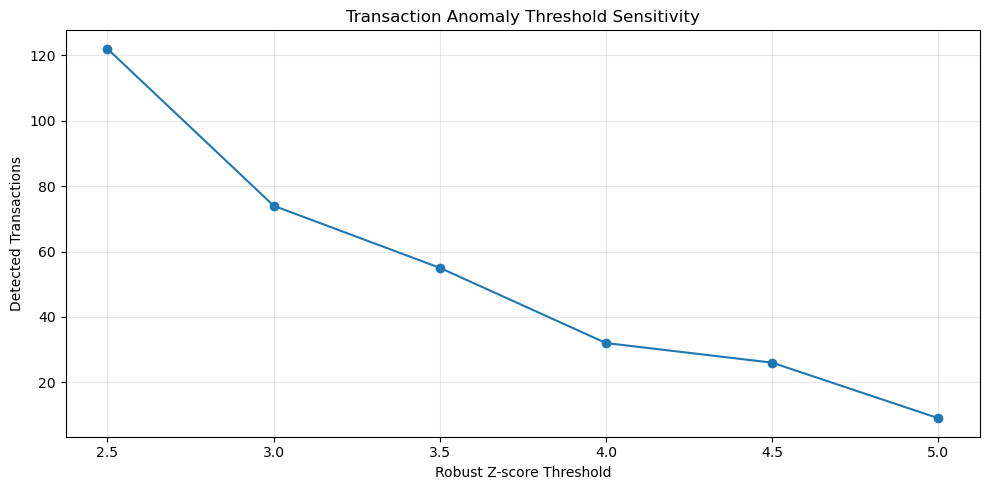

In [86]:

# ============================================================
# STEP 16: LOG MAD THRESHOLD SENSITIVITY
# ============================================================

thresholds = [2.5, 3.0, 3.5, 4.0, 4.5, 5.0]

threshold_results = []

for threshold in thresholds:

    flags = (
        log_detection["Log_Baseline_Available"]
        &
        (log_detection["Log_Robust_Z"] > threshold)
    )

    threshold_results.append({
        "Robust_Z_Threshold": threshold,
        "Detected_Transactions": int(flags.sum()),
        "Alert_Rate_Percent": (
            flags.sum() / len(log_detection) * 100
        )
    })

threshold_sensitivity = pd.DataFrame(
    threshold_results
)

print("LOG MAD THRESHOLD SENSITIVITY")
display(threshold_sensitivity.round(2))

plt.figure(figsize=(10, 5))

plt.plot(
    threshold_sensitivity["Robust_Z_Threshold"],
    threshold_sensitivity["Detected_Transactions"],
    marker="o"
)

plt.xlabel("Robust Z-score Threshold")
plt.ylabel("Detected Transactions")
plt.title("Transaction Anomaly Threshold Sensitivity")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


WEEKLY THRESHOLD SENSITIVITY


,Robust_Z_Threshold,Detected_Weeks,Alert_Rate_Percent
0,2.5,44,22.22
1,3.0,41,20.71
2,3.5,37,18.69
3,4.0,30,15.15
4,4.5,25,12.63
5,5.0,20,10.10



WEEKLY ANOMALY CANDIDATE INVESTIGATION


,Week_Start,Total_Spending,Transaction_Count,Historical_Median,Historical_MAD,Historical_Max_8,Weekly_Robust_Z,Current_to_Historical_Median,Above_Previous_History_Max,Above_Global_P95,Above_Global_P99
2018-12-03/2018-12-09,2018-12-03,3083.00,11,35.50,35.50,2350.0,57.90,86.85,True,False,False
2015-07-06/2015-07-12,2015-07-06,8280.00,2,190.50,190.50,8779.0,28.64,43.46,False,False,False
2016-11-28/2016-12-04,2016-11-28,21637.00,8,798.00,663.00,9637.0,21.20,27.11,True,True,False
2018-11-26/2018-12-02,2018-11-26,954.00,5,35.50,35.50,4012.0,17.45,26.87,False,False,False
2018-05-14/2018-05-20,2018-05-14,23914.00,15,2999.00,818.62,8692.0,17.23,7.97,True,True,False
2016-11-14/2016-11-20,2016-11-14,9637.00,22,448.50,432.00,3859.0,14.35,21.49,True,False,False
2015-07-27/2015-08-02,2015-07-27,4106.00,6,190.50,190.50,8280.0,13.86,21.55,False,False,False
2018-05-07/2018-05-13,2018-05-07,8692.00,19,2876.00,344.00,5261.0,11.40,3.02,True,False,False
2017-08-07/2017-08-13,2017-08-07,55597.00,12,5600.50,3210.30,30001.0,10.50,9.93,True,True,True
2017-11-27/2017-12-03,2017-11-27,29370.00,22,3399.23,1697.00,14538.6,10.32,8.64,True,True,False


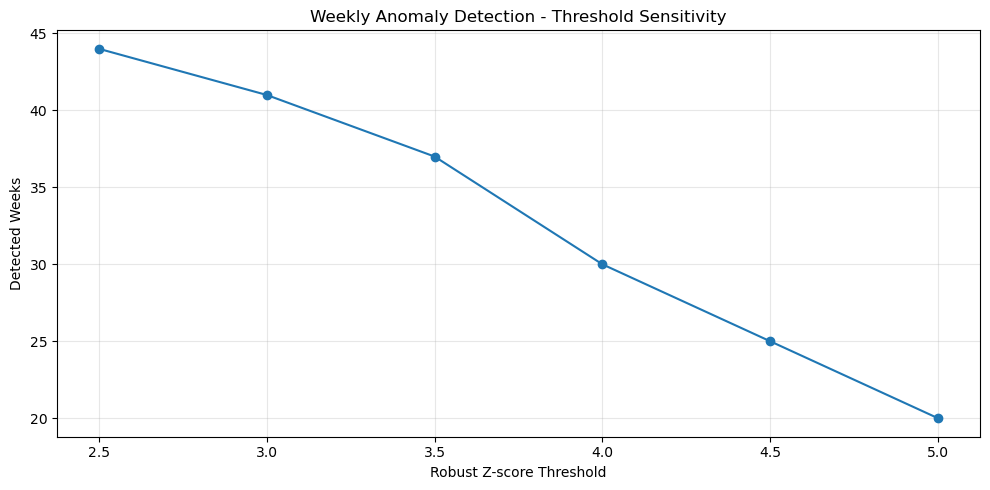


WEEKLY DETECTION SUMMARY
Total calendar weeks: 206
Evaluated weeks: 198
Unevaluated weeks: 8
Rolling MAD candidates at threshold 3.5: 37
Candidates exceeding previous 8-week maximum: 22
Candidates exceeding global P95: 11

STEP 17 COMPLETED


In [87]:

# ============================================================
# STEP 17: WEEKLY THRESHOLD SENSITIVITY AND CONTEXT
# ============================================================

# ------------------------------------------------------------
# 1. TEST DIFFERENT ROBUST Z-SCORE THRESHOLDS
# ------------------------------------------------------------

weekly_thresholds = [2.5, 3.0, 3.5, 4.0, 4.5, 5.0]

weekly_threshold_results = []

evaluated_weeks = (
    weekly_detection["Weekly_Robust_Z"].notna().sum()
)

for threshold in weekly_thresholds:

    flags = (
        weekly_detection["Weekly_Robust_Z"] > threshold
    )

    detected_count = int(flags.sum())

    weekly_threshold_results.append({
        "Robust_Z_Threshold": threshold,
        "Detected_Weeks": detected_count,
        "Alert_Rate_Percent": (
            detected_count / evaluated_weeks * 100
            if evaluated_weeks > 0 else np.nan
        )
    })

weekly_threshold_sensitivity = pd.DataFrame(
    weekly_threshold_results
)

print("WEEKLY THRESHOLD SENSITIVITY")
print("=" * 55)

display(
    weekly_threshold_sensitivity.round(2)
)

# ------------------------------------------------------------
# 2. CALCULATE PREVIOUS EIGHT-WEEK MAXIMUM
# ------------------------------------------------------------

weekly_context = weekly_detection.copy()

weekly_context["Historical_Max_8"] = (
    weekly_context["Total_Spending"]
    .shift(1)
    .rolling(
        window=8,
        min_periods=4
    )
    .max()
)

# ------------------------------------------------------------
# 3. COMPARE CURRENT SPENDING WITH HISTORICAL BASELINE
# ------------------------------------------------------------

weekly_context["Above_Previous_History_Max"] = (
    weekly_context["Total_Spending"]
    > weekly_context["Historical_Max_8"]
)

weekly_context["Above_Global_P95"] = (
    weekly_context["Total_Spending"]
    > WEEKLY_P95
)

weekly_context["Above_Global_P99"] = (
    weekly_context["Total_Spending"]
    > WEEKLY_P99
)

weekly_context["Current_to_Historical_Median"] = (
    weekly_context["Total_Spending"]
    / weekly_context["Historical_Median"].replace(0, np.nan)
)

# ------------------------------------------------------------
# 4. INVESTIGATE WEEKLY ANOMALY CANDIDATES
# ------------------------------------------------------------

weekly_candidates_context = weekly_context[
    weekly_context["Weekly_Robust_Z"] > 3.5
].copy()

print("\nWEEKLY ANOMALY CANDIDATE INVESTIGATION")
print("=" * 55)

display(
    weekly_candidates_context[
        [
            "Week_Start",
            "Total_Spending",
            "Transaction_Count",
            "Historical_Median",
            "Historical_MAD",
            "Historical_Max_8",
            "Weekly_Robust_Z",
            "Current_to_Historical_Median",
            "Above_Previous_History_Max",
            "Above_Global_P95",
            "Above_Global_P99"
        ]
    ]
    .sort_values(
        "Weekly_Robust_Z",
        ascending=False
    )
    .round(2)
)

# ------------------------------------------------------------
# 5. VISUALIZE THRESHOLD SENSITIVITY
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    weekly_threshold_sensitivity["Robust_Z_Threshold"],
    weekly_threshold_sensitivity["Detected_Weeks"],
    marker="o"
)

plt.xlabel("Robust Z-score Threshold")
plt.ylabel("Detected Weeks")

plt.title(
    "Weekly Anomaly Detection - Threshold Sensitivity"
)

plt.xticks(weekly_thresholds)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. FINAL SUMMARY
# ------------------------------------------------------------

print("\nWEEKLY DETECTION SUMMARY")
print("=" * 55)

print("Total calendar weeks:", len(weekly_context))
print("Evaluated weeks:", int(evaluated_weeks))

print(
    "Unevaluated weeks:",
    int(weekly_context["Weekly_Robust_Z"].isna().sum())
)

print(
    "Rolling MAD candidates at threshold 3.5:",
    int(weekly_candidates_context.shape[0])
)

print(
    "Candidates exceeding previous 8-week maximum:",
    int(
        weekly_candidates_context[
            "Above_Previous_History_Max"
        ].sum()
    )
)

print(
    "Candidates exceeding global P95:",
    int(
        weekly_candidates_context[
            "Above_Global_P95"
        ].sum()
    )
)

print("\nSTEP 17 COMPLETED")


In [88]:

# ============================================================
# STEP 18: SUBCATEGORY SPENDING DISTRIBUTION
# ============================================================

subcategory_stats = (
    transaction_df.groupby(
        ["Category", "Subcategory"],
        dropna=False
    )
    .agg(
        Transaction_Count=("Amount", "count"),
        Median_Amount=("Amount", "median"),
        Mean_Amount=("Amount", "mean"),
        Q90=("Amount", lambda x: x.quantile(0.90)),
        Q95=("Amount", lambda x: x.quantile(0.95)),
        Maximum=("Amount", "max")
    )
    .sort_values(
        "Transaction_Count",
        ascending=False
    )
)

print("SUBCATEGORY SPENDING DISTRIBUTION")
display(subcategory_stats.round(2))

# ------------------------------------------------------------
# INVESTIGATE LOG MAD ALERTS BY SUBCATEGORY
# ------------------------------------------------------------

subcategory_alerts = (
    log_detection.groupby(
        ["Category", "Subcategory"],
        dropna=False
    )
    .agg(
        Total_Transactions=("Amount", "count"),
        Log_MAD_Alerts=("Log_MAD_Flag", "sum")
    )
)

subcategory_alerts["Alert_Rate_Percent"] = (
    subcategory_alerts["Log_MAD_Alerts"]
    / subcategory_alerts["Total_Transactions"]
    * 100
)

print("\nSUBCATEGORY LOG MAD ALERT SUMMARY")

display(
    subcategory_alerts[
        subcategory_alerts["Log_MAD_Alerts"] > 0
    ].sort_values(
        "Log_MAD_Alerts",
        ascending=False
    ).round(2)
)

# ------------------------------------------------------------
# OBSERVATION SUPPORT ANALYSIS
# ------------------------------------------------------------

print("\nSUBCATEGORY SAMPLE SIZE DISTRIBUTION")

for minimum in [5, 8, 10, 15, 20]:

    eligible_groups = (
        subcategory_stats["Transaction_Count"] >= minimum
    ).sum()

    eligible_transactions = (
        subcategory_stats.loc[
            subcategory_stats["Transaction_Count"] >= minimum,
            "Transaction_Count"
        ].sum()
    )

    print(
        f"Minimum {minimum} observations:"
        f" {eligible_groups} groups,"
        f" {eligible_transactions} transactions"
    )


SUBCATEGORY SPENDING DISTRIBUTION


Transaction_Count  Median_Amount  Mean_Amount  \
Category       Subcategory                                                   
Food           Milk                        247          60.00        70.17   
Transportation auto                        166          30.00        54.19   
Food           snacks                      115          35.00        52.01   
               Grocery                     113          80.00       159.15   
Other          Unknown                     111         199.00       513.74   
...                                        ...            ...          ...   
Social Life    Leisure                       1         298.00       298.00   
Transportation ropeway                       1         338.00       338.00   
               Petrol                        1         360.00       360.00   
Tourism        Entry Fees                    1         308.85       308.85   
subscription   OTT Platform                  1         300.00       300.00   

                                 Q90      Q95  Maximum  
Category       Subcategory                              
Food           Milk            80.00   169.00  1178.00  
Transportation auto            90.00   163.00   760.00  
Food           snacks         100.00   150.00   250.00  
               Grocery        418.00   564.00  1279.00  
Other          Unknown       1780.00  2424.50  4720.00  
...                              ...      ...      ...  
Social Life    Leisure        298.00   298.00   298.00  
Transportation ropeway        338.00   338.00   338.00  
               Petrol         360.00   360.00   360.00  
Tourism        Entry Fees     308.85   308.85   308.85  
subscription   OTT Platform   300.00   300.00   300.00  

[94 rows x 6 columns]


SUBCATEGORY LOG MAD ALERT SUMMARY


Total_Transactions  Log_MAD_Alerts  \
Category       Subcategory                                                   
subscription   Edtech Course                            14              14   
Transportation Travels                                  19              13   
Food           Dinner                                   55               7   
subscription   Mobile Service Provider                  66               4   
Food           Grocery                                 113               4   
               Milk                                    247               2   
subscription   Wifi Internet Service                     2               2   
Transportation Taxi                                     19               2   
               Bike                                     12               2   
Beauty         Makeup                                    1               1   
Food           fruits                                   28               1   
               Eating out                                8               1   
Transportation train                                    19               1   
subscription   Newspaper                                 9               1   

                                        Alert_Rate_Percent  
Category       Subcategory                                  
subscription   Edtech Course                        100.00  
Transportation Travels                               68.42  
Food           Dinner                                12.73  
subscription   Mobile Service Provider                6.06  
Food           Grocery                                3.54  
               Milk                                   0.81  
subscription   Wifi Internet Service                100.00  
Transportation Taxi                                  10.53  
               Bike                                  16.67  
Beauty         Makeup                               100.00  
Food           fruits                                 3.57  
               Eating out                            12.50  
Transportation train                                  5.26  
subscription   Newspaper                             11.11


SUBCATEGORY SAMPLE SIZE DISTRIBUTION
Minimum 5 observations: 55 groups, 1909 transactions
Minimum 8 observations: 48 groups, 1867 transactions
Minimum 10 observations: 43 groups, 1826 transactions
Minimum 15 observations: 34 groups, 1711 transactions
Minimum 20 observations: 26 groups, 1573 transactions


SUBCATEGORY BASELINE SUPPORT COMPARISON


,Minimum_Samples,Eligible_Subcategories,Covered_Transactions,Coverage_Percent
0,5,55,1909,95.64
1,8,48,1867,93.54
2,10,43,1826,91.48
3,12,41,1805,90.43
4,15,34,1711,85.72
5,20,26,1573,78.81


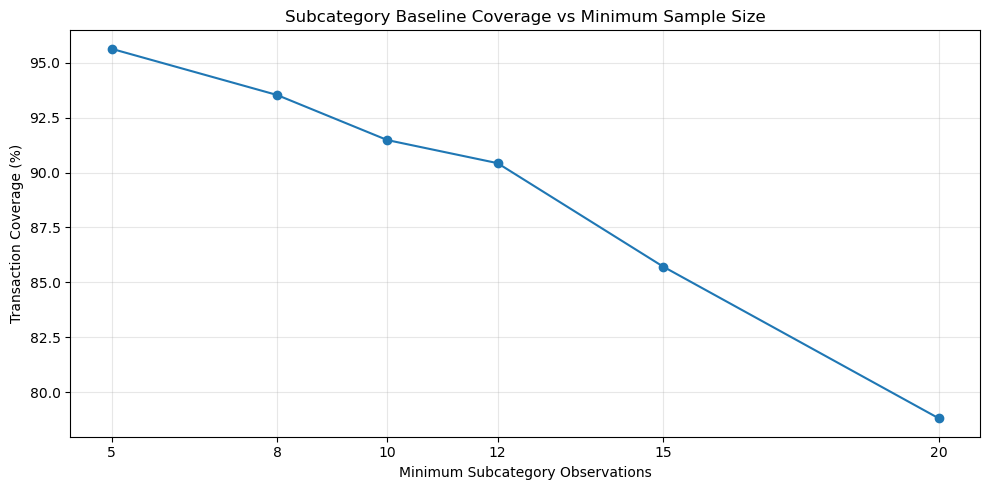

In [89]:

# ============================================================
# STEP 19: SUBCATEGORY BASELINE ELIGIBILITY
# ============================================================

support_levels = [5, 8, 10, 12, 15, 20]

support_results = []

for minimum in support_levels:

    eligible_groups = subcategory_stats[
        subcategory_stats["Transaction_Count"] >= minimum
    ]

    eligible_transactions = int(
        eligible_groups["Transaction_Count"].sum()
    )

    support_results.append({
        "Minimum_Samples": minimum,
        "Eligible_Subcategories": len(eligible_groups),
        "Covered_Transactions": eligible_transactions,
        "Coverage_Percent": (
            eligible_transactions / len(transaction_df) * 100
        )
    })

support_comparison = pd.DataFrame(support_results)

print("SUBCATEGORY BASELINE SUPPORT COMPARISON")
display(support_comparison.round(2))

# Visualize coverage
plt.figure(figsize=(10, 5))

plt.plot(
    support_comparison["Minimum_Samples"],
    support_comparison["Coverage_Percent"],
    marker="o"
)

plt.xlabel("Minimum Subcategory Observations")
plt.ylabel("Transaction Coverage (%)")
plt.title("Subcategory Baseline Coverage vs Minimum Sample Size")
plt.xticks(support_levels)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [90]:

# ============================================================
# STEP 20: HIERARCHICAL LOG MAD EXPERIMENT
# ============================================================

def calculate_log_mad_scores(data, group_columns, min_samples):

    result = data.copy()

    result["Log_Amount"] = np.log1p(result["Amount"])

    grouped = result.groupby(
        group_columns,
        dropna=False
    )["Log_Amount"]

    stats = grouped.agg(
        Group_Count="count",
        Group_Median="median"
    )

    mad_values = grouped.apply(
        lambda x: np.median(
            np.abs(x - np.median(x))
        )
    ).rename("Group_MAD")

    stats = stats.join(mad_values)

    result = result.join(
        stats,
        on=group_columns
    )

    result["Group_Robust_Z"] = (
        0.6745
        * (
            result["Log_Amount"]
            - result["Group_Median"]
        )
        / result["Group_MAD"].replace(0, np.nan)
    )

    result["Group_Eligible"] = (
        (result["Group_Count"] >= min_samples)
        & (result["Group_MAD"] > 0)
    )

    return result


hierarchical_results = []

for minimum in [8, 10, 15]:

    # Subcategory-specific baseline
    sub_result = calculate_log_mad_scores(
        transaction_df,
        ["Category", "Subcategory"],
        minimum
    )

    sub_result["Subcategory_Flag"] = (
        sub_result["Group_Eligible"]
        & (sub_result["Group_Robust_Z"] > 3.5)
    )

    # Category fallback baseline
    category_result = calculate_log_mad_scores(
        transaction_df,
        ["Category"],
        20
    )

    category_result["Category_Flag"] = (
        category_result["Group_Eligible"]
        & (category_result["Group_Robust_Z"] > 3.5)
    )

    # Hierarchical approach:
    # Use subcategory when eligible, otherwise category fallback
    use_subcategory = sub_result["Group_Eligible"]

    hierarchical_flags = pd.Series(
        np.where(
            use_subcategory,
            sub_result["Subcategory_Flag"],
            category_result["Category_Flag"]
        ),
        index=transaction_df.index
    )

    subcategory_only_count = int(
        sub_result["Subcategory_Flag"].sum()
    )

    hierarchical_count = int(
        hierarchical_flags.sum()
    )

    hierarchical_results.append({
        "Minimum_Subcategory_Samples": minimum,
        "Subcategory_Only_Alerts": subcategory_only_count,
        "Hierarchical_Alerts": hierarchical_count,
        "Hierarchical_Alert_Rate": (
            hierarchical_count / len(transaction_df) * 100
        )
    })

hierarchical_comparison = pd.DataFrame(
    hierarchical_results
)

print("HIERARCHICAL LOG MAD COMPARISON")
display(hierarchical_comparison.round(2))

print("\nREFERENCE: EXISTING CATEGORY LOG MAD")

print(
    "Category Log MAD alerts:",
    int(log_detection["Log_MAD_Flag"].sum())
)


HIERARCHICAL LOG MAD COMPARISON


,Minimum_Subcategory_Samples,Subcategory_Only_Alerts,Hierarchical_Alerts,Hierarchical_Alert_Rate
0,8,28,32,1.60
1,10,28,33,1.65
2,15,22,43,2.15



REFERENCE: EXISTING CATEGORY LOG MAD
Category Log MAD alerts: 55


WEEKLY DETECTOR COMPARISON
Original Rolling MAD candidates: 37
Refined weekly candidates: 22

REFINED WEEKLY CANDIDATES


,Week_Start,Total_Spending,Transaction_Count,Historical_Median,Historical_Max_8,Weekly_Robust_Z,Above_Global_P95,Above_Global_P99
2018-12-03/2018-12-09,2018-12-03,3083.00,11,35.50,2350.0,57.90,False,False
2016-11-28/2016-12-04,2016-11-28,21637.00,8,798.00,9637.0,21.20,True,False
2018-05-14/2018-05-20,2018-05-14,23914.00,15,2999.00,8692.0,17.23,True,False
2016-11-14/2016-11-20,2016-11-14,9637.00,22,448.50,3859.0,14.35,False,False
2018-05-07/2018-05-13,2018-05-07,8692.00,19,2876.00,5261.0,11.40,False,False
2017-08-07/2017-08-13,2017-08-07,55597.00,12,5600.50,30001.0,10.50,True,True
2017-11-27/2017-12-03,2017-11-27,29370.00,22,3399.23,14538.6,10.32,True,False
2016-06-27/2016-07-03,2016-06-27,3717.90,4,644.75,1543.0,8.57,False,False
2017-02-27/2017-03-05,2017-02-27,28453.47,48,5081.00,18824.0,7.55,True,False
2018-06-25/2018-07-01,2018-06-25,26429.67,29,3534.50,23914.0,6.73,True,False



CATEGORY CONTRIBUTIONS TO REFINED ANOMALOUS WEEKS


,Week,Category,Amount
3,2015-05-11/2015-05-17,Transportation,6000.00
2,2015-05-11/2015-05-17,Other,2257.00
0,2015-05-11/2015-05-17,Food,272.00
1,2015-05-11/2015-05-17,Health,250.00
4,2015-12-28/2016-01-03,Beauty,2000.00
...,...,...,...
107,2018-06-25/2018-07-01,Tourism,308.85
111,2018-12-03/2018-12-09,Transportation,1293.00
112,2018-12-03/2018-12-09,subscription,866.00
109,2018-12-03/2018-12-09,Food,812.00


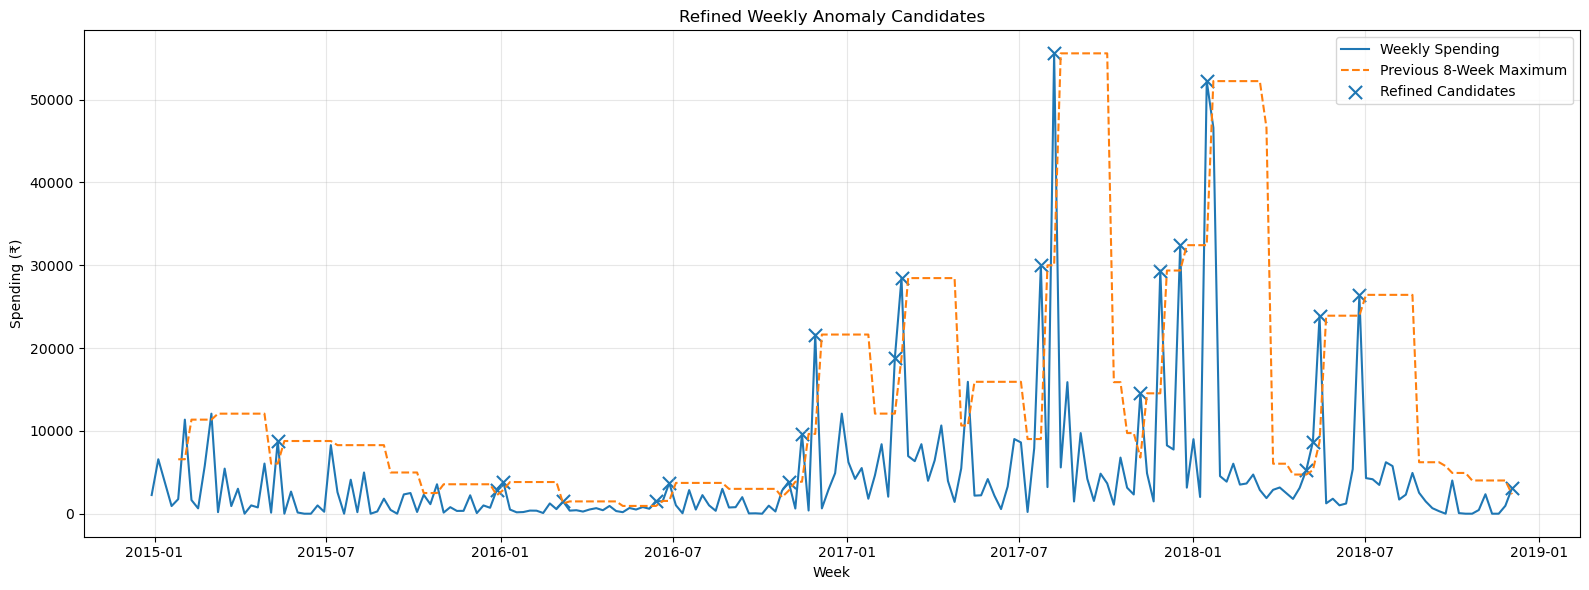

In [91]:

# ============================================================
# STEP 21: REFINED WEEKLY ANOMALY DETECTION
# ============================================================

weekly_refined = weekly_context.copy()

# Candidate must satisfy both conditions:
# 1. Robust Z-score exceeds 3.5
# 2. Current spending exceeds the previous 8-week maximum

weekly_refined["Refined_Weekly_Flag"] = (
    (weekly_refined["Weekly_Robust_Z"] > 3.5)
    &
    weekly_refined["Above_Previous_History_Max"]
)

print("WEEKLY DETECTOR COMPARISON")
print("=" * 55)

print(
    "Original Rolling MAD candidates:",
    int(weekly_refined["Weekly_Anomaly_Flag"].sum())
)

print(
    "Refined weekly candidates:",
    int(weekly_refined["Refined_Weekly_Flag"].sum())
)

print("\nREFINED WEEKLY CANDIDATES")

display(
    weekly_refined[
        weekly_refined["Refined_Weekly_Flag"]
    ][
        [
            "Week_Start",
            "Total_Spending",
            "Transaction_Count",
            "Historical_Median",
            "Historical_Max_8",
            "Weekly_Robust_Z",
            "Above_Global_P95",
            "Above_Global_P99"
        ]
    ].sort_values(
        "Weekly_Robust_Z",
        ascending=False
    ).round(2)
)

# ------------------------------------------------------------
# INVESTIGATE WHICH CATEGORIES DRIVE THESE WEEKS
# ------------------------------------------------------------

transaction_weekly = transaction_df.copy()

transaction_weekly["Week"] = (
    transaction_weekly["Date"].dt.to_period("W-SUN")
)

refined_periods = weekly_refined.index[
    weekly_refined["Refined_Weekly_Flag"]
]

weekly_category_composition = (
    transaction_weekly[
        transaction_weekly["Week"].isin(refined_periods)
    ]
    .groupby(["Week", "Category"])["Amount"]
    .sum()
    .reset_index()
    .sort_values(["Week", "Amount"], ascending=[True, False])
)

print("\nCATEGORY CONTRIBUTIONS TO REFINED ANOMALOUS WEEKS")

display(
    weekly_category_composition.round(2)
)

# ------------------------------------------------------------
# VISUALIZE REFINED CANDIDATES
# ------------------------------------------------------------

plt.figure(figsize=(16, 6))

plt.plot(
    weekly_refined["Week_Start"],
    weekly_refined["Total_Spending"],
    label="Weekly Spending"
)

plt.plot(
    weekly_refined["Week_Start"],
    weekly_refined["Historical_Max_8"],
    label="Previous 8-Week Maximum",
    linestyle="--"
)

refined_points = weekly_refined[
    weekly_refined["Refined_Weekly_Flag"]
]

plt.scatter(
    refined_points["Week_Start"],
    refined_points["Total_Spending"],
    marker="x",
    s=90,
    label="Refined Candidates"
)

plt.title("Refined Weekly Anomaly Candidates")
plt.xlabel("Week")
plt.ylabel("Spending (₹)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [92]:

# STEP 22: Compare different historical windows

import numpy as np
import pandas as pd

WINDOWS = [8, 13, 26]

MIN_PERIODS = {
    8: 4,
    13: 6,
    26: 10
}

weekly_window_results = weekly_df[["Total_Spending"]].copy()

for window in WINDOWS:

    history = weekly_df["Total_Spending"].shift(1)

    rolling_median = history.rolling(
        window=window,
        min_periods=MIN_PERIODS[window]
    ).median()

    rolling_mad = history.rolling(
        window=window,
        min_periods=MIN_PERIODS[window]
    ).apply(
        lambda x: np.median(np.abs(x - np.median(x))),
        raw=True
    )

    weekly_window_results[f"Median_{window}W"] = rolling_median
    weekly_window_results[f"MAD_{window}W"] = rolling_mad

    weekly_window_results[f"Robust_Z_{window}W"] = (
        0.6745 *
        (weekly_df["Total_Spending"] - rolling_median) /
        rolling_mad.replace(0, np.nan)
    )

weekly_window_results.tail(15)


,Total_Spending,Median_8W,MAD_8W,Robust_Z_8W,Median_13W,MAD_13W,Robust_Z_13W,Median_26W,MAD_26W,Robust_Z_26W
2018-08-27/2018-09-02,2525.85,4229.500,1137.500,-1.010208,4161.00,1861.00,-0.592643,3321.500,1525.000,-0.351912
2018-09-03/2018-09-09,1481.00,3819.000,1406.075,-1.121548,4161.00,1635.15,-1.105501,3140.500,1391.500,-0.804407
2018-09-10/2018-09-16,670.00,3001.425,1404.425,-1.119708,4161.00,1635.15,-1.440039,2999.000,1292.500,-1.215405
2018-09-17/2018-09-23,308.00,2412.925,1337.425,-1.061571,4161.00,1635.15,-1.589364,2999.000,1408.500,-1.288661
2018-09-24/2018-09-30,0.00,2006.500,931.000,-1.453689,3477.00,1764.00,-1.329499,2999.000,1632.500,-1.239097
2018-10-01/2018-10-07,4012.00,1597.000,927.925,1.755441,2525.85,1772.15,0.565645,2820.425,1580.125,0.508642
2018-10-08/2018-10-14,71.00,1890.500,1401.500,-0.875671,2525.85,1635.15,-1.012627,2820.425,1580.125,-1.173633
2018-10-15/2018-10-21,0.00,1075.500,1040.000,-0.697524,2300.00,1712.00,-0.906162,2820.425,1698.625,-1.119951
2018-10-22/2018-10-28,0.00,489.000,489.000,-0.674500,1713.00,1642.00,-0.703665,2820.425,1953.900,-0.973631
2018-10-29/2018-11-04,446.00,189.500,189.500,0.912978,1481.00,1410.00,-0.495112,2412.925,1995.000,-0.665008


In [93]:

# Compare alert counts across historical windows

WEEKLY_Z_THRESHOLD = 3.5

window_comparison = []

for window in WINDOWS:

    score_col = f"Robust_Z_{window}W"

    evaluated = weekly_window_results[score_col].notna()

    flags = (
        weekly_window_results[score_col] > WEEKLY_Z_THRESHOLD
    ) & evaluated

    window_comparison.append({
        "Window": f"{window} weeks",
        "Evaluated_Weeks": int(evaluated.sum()),
        "Unevaluated_Weeks": int((~evaluated).sum()),
        "Alert_Count": int(flags.sum()),
        "Alert_Rate": round(
            flags.sum() / evaluated.sum() * 100, 2
        ) if evaluated.sum() else np.nan
    })

window_comparison_df = pd.DataFrame(window_comparison)

display(window_comparison_df)


,Window,Evaluated_Weeks,Unevaluated_Weeks,Alert_Count,Alert_Rate
0,8 weeks,198,8,37,18.69
1,13 weeks,193,13,26,13.47
2,26 weeks,180,26,21,11.67


In [94]:

# Identify which weeks are flagged by each window

for window in WINDOWS:

    score_col = f"Robust_Z_{window}W"

    weekly_window_results[f"Flag_{window}W"] = (
        weekly_window_results[score_col] > WEEKLY_Z_THRESHOLD
    ) & weekly_window_results[score_col].notna()

flag_columns = [f"Flag_{window}W" for window in WINDOWS]

weekly_window_results["Number_Of_Detectors_Flagging"] = (
    weekly_window_results[flag_columns].sum(axis=1)
)

display(
    weekly_window_results.loc[
        weekly_window_results["Number_Of_Detectors_Flagging"] > 0,
        [
            "Total_Spending",
            "Number_Of_Detectors_Flagging",
            *flag_columns
        ]
    ].sort_values(
        "Total_Spending",
        ascending=False
    )
)


,Total_Spending,Number_Of_Detectors_Flagging,Flag_8W,Flag_13W,Flag_26W
2017-08-07/2017-08-13,55597.00,3,True,True,True
2018-01-15/2018-01-21,52244.00,3,True,True,True
2018-01-22/2018-01-28,46613.90,3,True,True,True
2017-12-18/2017-12-24,32431.00,3,True,True,True
2017-07-24/2017-07-30,30001.00,3,True,True,True
2017-11-27/2017-12-03,29370.00,3,True,True,True
2017-02-27/2017-03-05,28453.47,3,True,True,True
2018-06-25/2018-07-01,26429.67,3,True,True,True
2018-05-14/2018-05-20,23914.00,3,True,True,True
2016-11-28/2016-12-04,21637.00,3,True,True,True


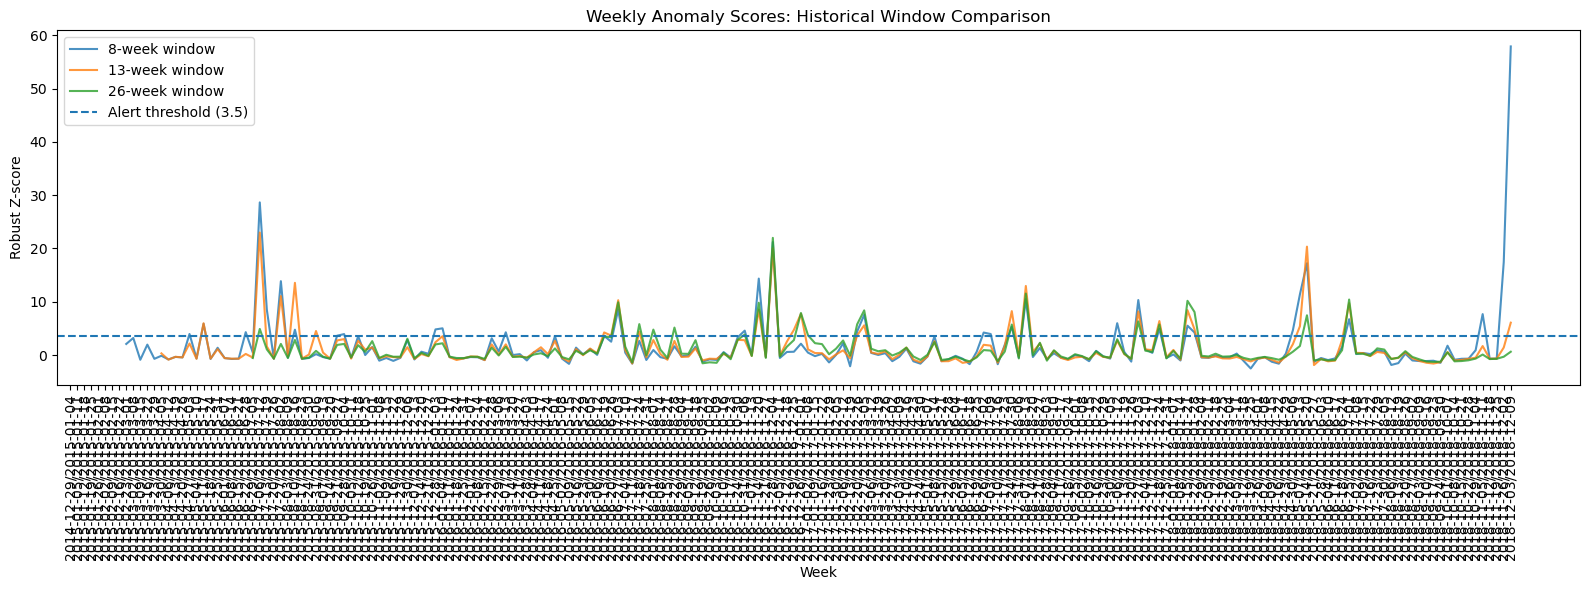

In [95]:

# Compare robust Z-scores over time

import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

for window in WINDOWS:
    plt.plot(
        weekly_window_results.index.astype(str),
        weekly_window_results[f"Robust_Z_{window}W"],
        label=f"{window}-week window",
        alpha=0.8
    )

plt.axhline(
    WEEKLY_Z_THRESHOLD,
    linestyle="--",
    label="Alert threshold (3.5)"
)

plt.title("Weekly Anomaly Scores: Historical Window Comparison")
plt.xlabel("Week")
plt.ylabel("Robust Z-score")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()


In [96]:

# STEP 22.1: FAIR COMPARISON ON COMMON EVALUATION WEEKS

# Only compare weeks where all three detectors have valid scores.

common_evaluation = weekly_window_results[
    [
        "Robust_Z_8W",
        "Robust_Z_13W",
        "Robust_Z_26W"
    ]
].notna().all(axis=1)

common_results = weekly_window_results.loc[
    common_evaluation
].copy()

fair_comparison = []

for window in WINDOWS:

    score_col = f"Robust_Z_{window}W"

    flags = common_results[score_col] > WEEKLY_Z_THRESHOLD

    fair_comparison.append({
        "Window": f"{window} weeks",
        "Common_Evaluated_Weeks": len(common_results),
        "Alert_Count": int(flags.sum()),
        "Alert_Rate": round(flags.mean() * 100, 2)
    })

fair_comparison_df = pd.DataFrame(fair_comparison)

display(fair_comparison_df)

print("Common evaluation weeks:", len(common_results))


,Window,Common_Evaluated_Weeks,Alert_Count,Alert_Rate
0,8 weeks,180,34,18.89
1,13 weeks,180,25,13.89
2,26 weeks,180,21,11.67


Common evaluation weeks: 180


In [97]:

# ============================================================
# STEP 23: ADAPTIVE DEVIATION FLOOR
# ============================================================

ADAPTIVE_RESULTS = weekly_df[["Total_Spending"]].copy()

for window in WINDOWS:

    min_periods = MIN_PERIODS[window]

    # Only use information available before the current week
    history = weekly_df["Total_Spending"].shift(1)

    # Historical rolling median
    rolling_median = history.rolling(
        window=window,
        min_periods=min_periods
    ).median()

    # Historical rolling MAD
    rolling_mad = history.rolling(
        window=window,
        min_periods=min_periods
    ).apply(
        lambda x: np.median(np.abs(x - np.median(x))),
        raw=True
    )

    # Convert MAD into a robust standard-deviation scale
    mad_scale = 1.4826 * rolling_mad

    # Historical median absolute week-to-week change
    absolute_changes = history.diff().abs()

    change_scale = absolute_changes.rolling(
        window=window,
        min_periods=min_periods
    ).median()

    # Adaptive scale: use the larger historical variation estimate
    effective_scale = pd.concat(
        [mad_scale, change_scale],
        axis=1
    ).max(axis=1)

    # Store results
    ADAPTIVE_RESULTS[f"Median_{window}W"] = rolling_median
    ADAPTIVE_RESULTS[f"MAD_Scale_{window}W"] = mad_scale
    ADAPTIVE_RESULTS[f"Change_Scale_{window}W"] = change_scale
    ADAPTIVE_RESULTS[f"Effective_Scale_{window}W"] = effective_scale

    # Calculate adaptive robust score
    ADAPTIVE_RESULTS[f"Adaptive_Z_{window}W"] = (
        weekly_df["Total_Spending"] - rolling_median
    ) / effective_scale.replace(0, np.nan)

ADAPTIVE_RESULTS.tail(15)


,Total_Spending,Median_8W,MAD_Scale_8W,Change_Scale_8W,Effective_Scale_8W,Adaptive_Z_8W,Median_13W,MAD_Scale_13W,Change_Scale_13W,Effective_Scale_13W,Adaptive_Z_13W,Median_26W,MAD_Scale_26W,Change_Scale_26W,Effective_Scale_26W,Adaptive_Z_26W
2018-08-27/2018-09-02,2525.85,4229.500,1686.457500,1653.400,1686.457500,-1.010194,4161.00,2759.11860,793.00,2759.11860,-0.592635,3321.500,2260.965000,1039.625,2260.965000,-0.351907
2018-09-03/2018-09-09,1481.00,3819.000,2084.646795,1540.475,2084.646795,-1.121533,4161.00,2424.27339,2396.95,2424.27339,-1.105486,3140.500,2063.037900,1204.500,2063.037900,-0.804396
2018-09-10/2018-09-16,670.00,3001.425,2082.200505,1720.900,2082.200505,-1.119693,4161.00,2424.27339,2396.95,2424.27339,-1.440019,2999.000,1916.260500,1187.425,1916.260500,-1.215388
2018-09-17/2018-09-23,308.00,2412.925,1982.866305,1720.900,1982.866305,-1.061557,4161.00,2424.27339,2396.95,2424.27339,-1.589342,2999.000,2088.242100,1022.550,2088.242100,-1.288644
2018-09-24/2018-09-30,0.00,2006.500,1380.300600,927.925,1380.300600,-1.453669,3477.00,2615.30640,1044.85,2615.30640,-1.329481,2999.000,2420.344500,1022.550,2420.344500,-1.239080
2018-10-01/2018-10-07,4012.00,1597.000,1375.741605,927.925,1375.741605,1.755417,2525.85,2627.38959,811.00,2627.38959,0.565637,2820.425,2342.693325,927.925,2342.693325,0.508635
2018-10-08/2018-10-14,71.00,1890.500,2077.863900,927.925,2077.863900,-0.875659,2525.85,2424.27339,811.00,2424.27339,-1.012613,2820.425,2342.693325,1187.425,2342.693325,-1.173617
2018-10-15/2018-10-21,0.00,1075.500,1541.904000,1720.900,1720.900000,-0.624964,2300.00,2538.21120,1044.85,2538.21120,-0.906150,2820.425,2518.381425,1738.000,2518.381425,-1.119936
2018-10-22/2018-10-28,0.00,489.000,724.991400,927.925,927.925000,-0.526982,1713.00,2434.42920,1044.85,2434.42920,-0.703656,2820.425,2896.852140,1738.000,2896.852140,-0.973617
2018-10-29/2018-11-04,446.00,189.500,280.952700,586.500,586.500000,0.437340,1481.00,2090.46600,811.00,2090.46600,-0.495105,2412.925,2957.787000,1595.425,2957.787000,-0.664999


In [98]:

# ============================================================
# STEP 23.1: ORIGINAL VS ADAPTIVE DETECTOR
# ============================================================

adaptive_comparison = []

for window in WINDOWS:

    original_col = f"Robust_Z_{window}W"
    adaptive_col = f"Adaptive_Z_{window}W"

    original_flags = (
        weekly_window_results[original_col] > WEEKLY_Z_THRESHOLD
    )

    adaptive_flags = (
        ADAPTIVE_RESULTS[adaptive_col] > WEEKLY_Z_THRESHOLD
    )

    adaptive_comparison.append({
        "Window": f"{window} weeks",

        "Original_Evaluated": int(
            weekly_window_results[original_col].notna().sum()
        ),

        "Original_Alerts": int(original_flags.sum()),

        "Adaptive_Evaluated": int(
            ADAPTIVE_RESULTS[adaptive_col].notna().sum()
        ),

        "Adaptive_Alerts": int(adaptive_flags.sum())
    })

adaptive_comparison_df = pd.DataFrame(adaptive_comparison)

display(adaptive_comparison_df)


,Window,Original_Evaluated,Original_Alerts,Adaptive_Evaluated,Adaptive_Alerts
0,8 weeks,198,37,201,20
1,13 weeks,193,26,199,18
2,26 weeks,180,21,195,18


In [99]:

# ============================================================
# STEP 23.2: INVESTIGATE 13-WEEK ALERT CHANGES
# ============================================================

comparison_13w = pd.DataFrame(index=weekly_df.index)

comparison_13w["Total_Spending"] = weekly_df["Total_Spending"]

comparison_13w["Original_Z"] = weekly_window_results["Robust_Z_13W"]

comparison_13w["Adaptive_Z"] = ADAPTIVE_RESULTS["Adaptive_Z_13W"]

comparison_13w["Original_Flag"] = (
    comparison_13w["Original_Z"] > WEEKLY_Z_THRESHOLD
)

comparison_13w["Adaptive_Flag"] = (
    comparison_13w["Adaptive_Z"] > WEEKLY_Z_THRESHOLD
)

comparison_13w["Detection_Change"] = np.select(
    [
        comparison_13w["Original_Flag"] &
        comparison_13w["Adaptive_Flag"],

        comparison_13w["Original_Flag"] &
        ~comparison_13w["Adaptive_Flag"],

        ~comparison_13w["Original_Flag"] &
        comparison_13w["Adaptive_Flag"]
    ],
    [
        "Flagged by both",
        "Removed by adaptive scale",
        "New adaptive alert"
    ],
    default="Not flagged"
)

display(
    comparison_13w[
        comparison_13w["Detection_Change"] != "Not flagged"
    ].sort_values(
        "Total_Spending",
        ascending=False
    )
)


,Total_Spending,Original_Z,Adaptive_Z,Original_Flag,Adaptive_Flag,Detection_Change
2017-08-07/2017-08-13,55597.00,12.963434,9.122853,True,True,Flagged by both
2018-01-15/2018-01-21,52244.00,8.423399,6.512833,True,True,Flagged by both
2018-01-22/2018-01-28,46613.90,4.828458,4.024595,True,True,Flagged by both
2017-12-18/2017-12-24,32431.00,6.383462,6.383375,True,True,Flagged by both
2017-07-24/2017-07-30,30001.00,8.248039,8.247926,True,True,Flagged by both
2017-11-27/2017-12-03,29370.00,8.184165,7.062478,True,True,Flagged by both
2017-02-27/2017-03-05,28453.47,5.580600,5.580524,True,True,Flagged by both
2018-06-25/2018-07-01,26429.67,9.737725,9.737591,True,True,Flagged by both
2018-05-14/2018-05-20,23914.00,20.340881,19.228916,True,True,Flagged by both
2016-11-28/2016-12-04,21637.00,20.040230,17.276261,True,True,Flagged by both


In [100]:

# ============================================================
# STEP 23.3: ADAPTIVE SCALE DIAGNOSTICS
# ============================================================

scale_diagnostics = []

for window in WINDOWS:

    mad_col = f"MAD_Scale_{window}W"
    change_col = f"Change_Scale_{window}W"
    effective_col = f"Effective_Scale_{window}W"

    valid = ADAPTIVE_RESULTS[
        [mad_col, change_col, effective_col]
    ].dropna()

    scale_diagnostics.append({
        "Window": f"{window} weeks",
        "Valid_Weeks": len(valid),

        "Zero_MAD_Weeks": int(
            (valid[mad_col] == 0).sum()
        ),

        "Change_Scale_Greater_Weeks": int(
            (valid[change_col] > valid[mad_col]).sum()
        ),

        "Median_MAD_Scale": round(
            valid[mad_col].median(), 2
        ),

        "Median_Change_Scale": round(
            valid[change_col].median(), 2
        ),

        "Median_Effective_Scale": round(
            valid[effective_col].median(), 2
        )
    })

scale_diagnostics_df = pd.DataFrame(scale_diagnostics)

display(scale_diagnostics_df)


,Window,Valid_Weeks,Zero_MAD_Weeks,Change_Scale_Greater_Weeks,Median_MAD_Scale,Median_Change_Scale,Median_Effective_Scale
0,8 weeks,198,0,161,1498.91,2030.50,2337.62
1,13 weeks,193,0,136,1518.18,2396.95,2599.00
2,26 weeks,180,0,116,2216.67,2168.15,2522.27


In [101]:

# STEP 23.4: FAIR ORIGINAL VS ADAPTIVE COMPARISON

fair_adaptive_results = []

for window in WINDOWS:

    original_col = f"Robust_Z_{window}W"
    adaptive_col = f"Adaptive_Z_{window}W"

    # Keep only weeks evaluated by BOTH detectors
    common = (
        weekly_window_results[original_col].notna()
        & ADAPTIVE_RESULTS[adaptive_col].notna()
    )

    original_scores = weekly_window_results.loc[
        common, original_col
    ]

    adaptive_scores = ADAPTIVE_RESULTS.loc[
        common, adaptive_col
    ]

    original_flags = original_scores > WEEKLY_Z_THRESHOLD
    adaptive_flags = adaptive_scores > WEEKLY_Z_THRESHOLD

    fair_adaptive_results.append({
        "Window": f"{window} weeks",
        "Common_Weeks": int(common.sum()),
        "Original_Alerts": int(original_flags.sum()),
        "Adaptive_Alerts": int(adaptive_flags.sum()),
        "Flagged_By_Both": int(
            (original_flags & adaptive_flags).sum()
        ),
        "Removed_By_Adaptive": int(
            (original_flags & ~adaptive_flags).sum()
        ),
        "New_Adaptive_Alerts": int(
            (~original_flags & adaptive_flags).sum()
        )
    })

fair_adaptive_comparison_df = pd.DataFrame(
    fair_adaptive_results
)

display(fair_adaptive_comparison_df)


,Window,Common_Weeks,Original_Alerts,Adaptive_Alerts,Flagged_By_Both,Removed_By_Adaptive,New_Adaptive_Alerts
0,8 weeks,198,37,20,20,17,0
1,13 weeks,193,26,18,18,8,0
2,26 weeks,180,21,18,18,3,0


In [102]:

# ============================================================
# STEP 24: COMPARE DETECTOR COMBINATIONS
# CELL 1: COMMON EVALUATION PERIOD (CORRECTED)
# ============================================================

# Start with all weeks included
common_mask = pd.Series(
    True,
    index=weekly_df.index
)

# Require valid scores from both original and adaptive detectors
for window in WINDOWS:

    original_col = f"Robust_Z_{window}W"
    adaptive_col = f"Adaptive_Z_{window}W"

    common_mask &= weekly_window_results[original_col].notna()

    common_mask &= ADAPTIVE_RESULTS[adaptive_col].notna()


# Create common evaluation dataset
step24_results = pd.DataFrame(index=weekly_df.index)

step24_results["Total_Spending"] = weekly_df["Total_Spending"]

step24_results = step24_results.loc[common_mask].copy()


print("Total calendar weeks:", len(weekly_df))
print("Common evaluation weeks:", len(step24_results))
print("Excluded weeks:", len(weekly_df) - len(step24_results))

display(step24_results.head())


Total calendar weeks: 206
Common evaluation weeks: 180
Excluded weeks: 26


,Total_Spending
2015-06-29/2015-07-05,236.0
2015-07-06/2015-07-12,8280.0
2015-07-13/2015-07-19,2599.0
2015-07-20/2015-07-26,0.0
2015-07-27/2015-08-02,4106.0


In [103]:

# ============================================================
# STEP 24.1: DETECTOR COMPARISON
# ============================================================

comparison_rows = []

for window in WINDOWS:

    original_col = f"Robust_Z_{window}W"
    adaptive_col = f"Adaptive_Z_{window}W"

    # Historical maximum using previous weeks only
    previous_max = (
        weekly_df["Total_Spending"]
        .shift(1)
        .rolling(
            window=window,
            min_periods=MIN_PERIODS[window]
        )
        .max()
    )

    original_z = weekly_window_results.loc[
        common_mask, original_col
    ]

    adaptive_z = ADAPTIVE_RESULTS.loc[
        common_mask, adaptive_col
    ]

    spending = weekly_df.loc[
        common_mask, "Total_Spending"
    ]

    historical_max = previous_max.loc[common_mask]

    # Four detector versions
    original_flags = original_z > WEEKLY_Z_THRESHOLD

    adaptive_flags = adaptive_z > WEEKLY_Z_THRESHOLD

    original_refined_flags = (
        original_flags & (spending > historical_max)
    )

    adaptive_refined_flags = (
        adaptive_flags & (spending > historical_max)
    )

    detector_flags = {
        "Original MAD": original_flags,
        "Adaptive MAD": adaptive_flags,
        "Original MAD + Previous Max": original_refined_flags,
        "Adaptive MAD + Previous Max": adaptive_refined_flags
    }

    for detector_name, flags in detector_flags.items():

        comparison_rows.append({
            "Window": f"{window} weeks",
            "Detector": detector_name,
            "Evaluated_Weeks": len(flags),
            "Alert_Count": int(flags.sum()),
            "Alert_Rate_Percent": round(
                flags.mean() * 100, 2
            )
        })

step24_comparison_df = pd.DataFrame(comparison_rows)

display(
    step24_comparison_df.sort_values(
        ["Window", "Alert_Count"],
        ascending=[True, False]
    )
)


,Window,Detector,Evaluated_Weeks,Alert_Count,Alert_Rate_Percent
4,13 weeks,Original MAD,180,25,13.89
5,13 weeks,Adaptive MAD,180,18,10.00
6,13 weeks,Original MAD + Previous Max,180,14,7.78
7,13 weeks,Adaptive MAD + Previous Max,180,13,7.22
8,26 weeks,Original MAD,180,21,11.67
9,26 weeks,Adaptive MAD,180,18,10.00
10,26 weeks,Original MAD + Previous Max,180,6,3.33
11,26 weeks,Adaptive MAD + Previous Max,180,5,2.78
0,8 weeks,Original MAD,180,34,18.89
2,8 weeks,Original MAD + Previous Max,180,21,11.67


In [104]:

# ============================================================
# STEP 24.2: ALERT AGREEMENT AND FLAGGED WEEKS
# ============================================================

window_to_inspect = 13

previous_max = (
    weekly_df["Total_Spending"]
    .shift(1)
    .rolling(
        window=window_to_inspect,
        min_periods=MIN_PERIODS[window_to_inspect]
    )
    .max()
)

inspection = pd.DataFrame(index=step24_results.index)

inspection["Total_Spending"] = step24_results["Total_Spending"]

inspection["Previous_Historical_Max"] = previous_max.loc[
    step24_results.index
]

inspection["Original_Z"] = weekly_window_results.loc[
    step24_results.index, "Robust_Z_13W"
]

inspection["Adaptive_Z"] = ADAPTIVE_RESULTS.loc[
    step24_results.index, "Adaptive_Z_13W"
]

inspection["Original_MAD_Flag"] = (
    inspection["Original_Z"] > WEEKLY_Z_THRESHOLD
)

inspection["Adaptive_MAD_Flag"] = (
    inspection["Adaptive_Z"] > WEEKLY_Z_THRESHOLD
)

inspection["Original_Refined_Flag"] = (
    inspection["Original_MAD_Flag"]
    & (
        inspection["Total_Spending"]
        > inspection["Previous_Historical_Max"]
    )
)

inspection["Adaptive_Refined_Flag"] = (
    inspection["Adaptive_MAD_Flag"]
    & (
        inspection["Total_Spending"]
        > inspection["Previous_Historical_Max"]
    )
)

display(
    inspection[
        inspection[
            [
                "Original_MAD_Flag",
                "Adaptive_MAD_Flag",
                "Original_Refined_Flag",
                "Adaptive_Refined_Flag"
            ]
        ].any(axis=1)
    ].sort_values(
        "Total_Spending",
        ascending=False
    )
)


,Total_Spending,Previous_Historical_Max,Original_Z,Adaptive_Z,Original_MAD_Flag,Adaptive_MAD_Flag,Original_Refined_Flag,Adaptive_Refined_Flag
2017-08-07/2017-08-13,55597.00,30001.0,12.963434,9.122853,True,True,True,True
2018-01-15/2018-01-21,52244.00,32431.0,8.423399,6.512833,True,True,True,True
2018-01-22/2018-01-28,46613.90,52244.0,4.828458,4.024595,True,True,False,False
2017-12-18/2017-12-24,32431.00,29370.0,6.383462,6.383375,True,True,True,True
2017-07-24/2017-07-30,30001.00,15929.0,8.248039,8.247926,True,True,True,True
2017-11-27/2017-12-03,29370.00,14538.6,8.184165,7.062478,True,True,True,True
2017-02-27/2017-03-05,28453.47,21637.0,5.580600,5.580524,True,True,True,True
2018-06-25/2018-07-01,26429.67,23914.0,9.737725,9.737591,True,True,True,True
2018-05-14/2018-05-20,23914.00,8692.0,20.340881,19.228916,True,True,True,True
2016-11-28/2016-12-04,21637.00,9637.0,20.040230,17.276261,True,True,True,True


In [105]:

# ============================================================
# STEP 25: CATEGORY CONTRIBUTION ANALYSIS
# CELL 1: WEEKLY CATEGORY SPENDING MATRIX
# ============================================================

category_data = transaction_df.copy()

category_data["Week"] = (
    category_data["Date"].dt.to_period("W-SUN")
)

category_data["Category"] = (
    category_data["Category"].fillna("Unknown")
)

categories = sorted(category_data["Category"].unique())

weekly_category_spending = (
    category_data
    .groupby(["Week", "Category"])["Amount"]
    .sum()
    .unstack(fill_value=0)
    .reindex(
        index=weekly_df.index,
        columns=categories,
        fill_value=0
    )
)

print("Weekly category matrix shape:", weekly_category_spending.shape)
print("Number of categories:", len(categories))
print("Number of weeks:", len(weekly_category_spending))

display(weekly_category_spending.head())


Weekly category matrix shape: (206, 23)
Number of categories: 23
Number of weeks: 206


Category,Apparel,Beauty,Cook,Culture,Documents,Education,Family,Festivals,Food,Gift,...,Other,Rent,Self-development,Social Life,Tourism,Transportation,garbage disposal,maid,subscription,water (jar /tanker)
2014-12-29/2015-01-04,248.0,0.0,0.0,40.0,0.0,0.0,0.0,0.0,880.0,0.0,...,0.0,0.0,0.0,0.0,0.0,302.0,0.0,0.0,0.0,0.0
2015-01-05/2015-01-11,0.0,0.0,776.0,0.0,0.0,0.0,0.0,0.0,20.0,0.0,...,0.0,5376.0,0.0,0.0,0.0,70.0,0.0,333.0,0.0,0.0
2015-01-12/2015-01-18,773.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,489.0,1024.0,...,500.0,0.0,0.0,0.0,0.0,950.0,0.0,0.0,0.0,0.0
2015-01-19/2015-01-25,0.0,60.0,0.0,0.0,0.0,0.0,0.0,0.0,402.0,0.0,...,0.0,0.0,0.0,0.0,0.0,402.0,0.0,0.0,0.0,0.0
2015-01-26/2015-02-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1659.0,0.0,...,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0


In [106]:

# ============================================================
# STEP 25.1: CATEGORY CONTRIBUTION TO ALERT WEEKS
# ============================================================

category_contribution_rows = []

for window in WINDOWS:

    # Candidate detector: Adaptive MAD + Previous Maximum
    adaptive_scores = ADAPTIVE_RESULTS[
        f"Adaptive_Z_{window}W"
    ]

    previous_max = (
        weekly_df["Total_Spending"]
        .shift(1)
        .rolling(
            window=window,
            min_periods=MIN_PERIODS[window]
        )
        .max()
    )

    alert_flags = (
        (adaptive_scores > WEEKLY_Z_THRESHOLD)
        & (weekly_df["Total_Spending"] > previous_max)
    )

    alert_weeks = weekly_df.index[alert_flags]

    # Category-specific historical median using past weeks only
    category_history = (
        weekly_category_spending
        .shift(1)
        .rolling(
            window=window,
            min_periods=MIN_PERIODS[window]
        )
        .median()
    )

    for week in alert_weeks:

        current = weekly_category_spending.loc[week]
        baseline = category_history.loc[week]

        valid = baseline.notna()

        current = current[valid]
        baseline = baseline[valid]

        # Positive excess above each category's historical median
        excess = (current - baseline).clip(lower=0)

        total_excess = excess.sum()

        if total_excess <= 0:
            continue

        for category in excess.index:

            if excess[category] <= 0:
                continue

            category_contribution_rows.append({
                "Window": f"{window} weeks",
                "Week": week,
                "Category": category,
                "Current_Spending": current[category],
                "Historical_Category_Median": baseline[category],
                "Positive_Excess": excess[category],
                "Excess_Contribution_Percent": (
                    excess[category] / total_excess * 100
                )
            })

category_contributions = pd.DataFrame(
    category_contribution_rows
)

print("Category contribution records:", len(category_contributions))

display(
    category_contributions.sort_values(
        ["Window", "Week", "Positive_Excess"],
        ascending=[True, True, False]
    ).head(30).round(2)
)


Category contribution records: 183


,Window,Week,Category,Current_Spending,Historical_Category_Median,Positive_Excess,Excess_Contribution_Percent
89,13 weeks,2016-06-13/2016-06-19,Family,905.00,0.0,905.00,58.65
90,13 weeks,2016-06-13/2016-06-19,Food,600.00,0.0,600.00,38.89
91,13 weeks,2016-06-13/2016-06-19,Other,38.00,0.0,38.00,2.46
94,13 weeks,2016-06-27/2016-07-03,Transportation,3200.00,0.0,3200.00,94.15
93,13 weeks,2016-06-27/2016-07-03,Other,106.90,0.0,106.90,3.15
92,13 weeks,2016-06-27/2016-07-03,Food,160.00,68.0,92.00,2.71
97,13 weeks,2016-11-14/2016-11-20,Transportation,7408.00,0.0,7408.00,77.72
95,13 weeks,2016-11-14/2016-11-20,Food,1379.00,105.0,1274.00,13.37
96,13 weeks,2016-11-14/2016-11-20,Other,850.00,0.0,850.00,8.92
100,13 weeks,2016-11-28/2016-12-04,Household,20500.00,0.0,20500.00,94.83


In [107]:

# ============================================================
# STEP 25.2: OVERALL CATEGORY CONTRIBUTION SUMMARY
# ============================================================

if not category_contributions.empty:

    category_contribution_summary = (
        category_contributions
        .groupby(["Window", "Category"])
        .agg(
            Alert_Weeks=("Week", "nunique"),
            Total_Positive_Excess=("Positive_Excess", "sum"),
            Average_Contribution_Percent=(
                "Excess_Contribution_Percent", "mean"
            )
        )
        .reset_index()
        .sort_values(
            ["Window", "Total_Positive_Excess"],
            ascending=[True, False]
        )
    )

    display(category_contribution_summary.round(2))

else:
    print("No positive category excess contributions found.")


,Window,Category,Alert_Weeks,Total_Positive_Excess,Average_Contribution_Percent
7,13 weeks,Household,9,74426.00,34.36
11,13 weeks,Transportation,10,65586.00,28.61
10,13 weeks,Tourism,3,63308.85,49.37
12,13 weeks,subscription,5,40014.22,26.45
6,13 weeks,Health,4,32528.00,38.05
5,13 weeks,Gift,3,10473.00,8.41
4,13 weeks,Food,11,8390.25,7.01
0,13 weeks,Apparel,5,7839.82,11.99
8,13 weeks,Other,8,7012.90,4.69
3,13 weeks,Family,5,5163.00,13.73


In [108]:

# ============================================================
# STEP 26: CHRONOLOGICAL BACKTESTING
# CELL 1: PREPARE THE EVALUATION PERIOD
# ============================================================

backtest_results = pd.DataFrame(index=weekly_df.index)

backtest_results["Total_Spending"] = weekly_df["Total_Spending"]

score_columns = []

for window in WINDOWS:

    original_col = f"Robust_Z_{window}W"
    adaptive_col = f"Adaptive_Z_{window}W"

    backtest_results[original_col] = (
        weekly_window_results[original_col]
    )

    backtest_results[adaptive_col] = (
        ADAPTIVE_RESULTS[adaptive_col]
    )

    previous_max = (
        weekly_df["Total_Spending"]
        .shift(1)
        .rolling(
            window=window,
            min_periods=MIN_PERIODS[window]
        )
        .max()
    )

    backtest_results[f"Previous_Max_{window}W"] = previous_max

    score_columns.extend([original_col, adaptive_col])

# Require every detector to have valid historical information
common_backtest_mask = (
    backtest_results[score_columns].notna().all(axis=1)
)

for window in WINDOWS:
    common_backtest_mask &= (
        backtest_results[f"Previous_Max_{window}W"].notna()
    )

# Chronological split: first 70% development, last 30% evaluation
split_position = int(len(weekly_df) * 0.70)

test_start_week = weekly_df.index[split_position]

test_mask = (
    common_backtest_mask
    & (backtest_results.index >= test_start_week)
)

backtest_test = backtest_results.loc[test_mask].copy()

print("Total calendar weeks:", len(weekly_df))
print("Development period ends:", weekly_df.index[split_position - 1])
print("Evaluation period starts:", test_start_week)
print("Common evaluation weeks:", len(backtest_test))


Total calendar weeks: 206
Development period ends: 2017-09-25/2017-10-01
Evaluation period starts: 2017-10-02/2017-10-08
Common evaluation weeks: 62


In [109]:

# ============================================================
# STEP 26.1: GENERATE BACKTEST DETECTION FLAGS
# ============================================================

for window in WINDOWS:

    original_z = backtest_results[f"Robust_Z_{window}W"]

    adaptive_z = backtest_results[f"Adaptive_Z_{window}W"]

    previous_max = backtest_results[f"Previous_Max_{window}W"]

    original_flag = original_z > WEEKLY_Z_THRESHOLD

    adaptive_flag = adaptive_z > WEEKLY_Z_THRESHOLD

    # Four detection strategies
    backtest_results[f"Original_MAD_{window}W"] = original_flag

    backtest_results[f"Adaptive_MAD_{window}W"] = adaptive_flag

    backtest_results[f"Original_Refined_{window}W"] = (
        original_flag
        & (backtest_results["Total_Spending"] > previous_max)
    )

    backtest_results[f"Adaptive_Refined_{window}W"] = (
        adaptive_flag
        & (backtest_results["Total_Spending"] > previous_max)
    )

# Extract only the chronological evaluation period
backtest_test = backtest_results.loc[test_mask].copy()

print("Backtesting detection flags generated successfully.")

display(backtest_test.head())


Backtesting detection flags generated successfully.


,Total_Spending,Robust_Z_8W,Adaptive_Z_8W,Previous_Max_8W,Robust_Z_13W,Adaptive_Z_13W,Previous_Max_13W,Robust_Z_26W,Adaptive_Z_26W,Previous_Max_26W,...,Original_Refined_8W,Adaptive_Refined_8W,Original_MAD_13W,Adaptive_MAD_13W,Original_Refined_13W,Adaptive_Refined_13W,Original_MAD_26W,Adaptive_MAD_26W,Original_Refined_26W,Adaptive_Refined_26W
2017-10-02/2017-10-08,3658.98,-0.282765,-0.167241,55597.0,-0.321424,-0.229807,55597.0,-0.193269,-0.153358,55597.0,...,False,False,False,False,False,False,False,False,False,False
2017-10-09/2017-10-15,1088.00,-1.144551,-0.498212,15888.0,-0.767054,-0.446266,55597.0,-0.780096,-0.552156,55597.0,...,False,False,False,False,False,False,False,False,False,False
2017-10-16/2017-10-22,6780.00,0.790952,0.645054,15888.0,0.398475,0.235585,55597.0,0.714574,0.481572,55597.0,...,False,False,False,False,False,False,False,False,False,False
2017-10-23/2017-10-29,3139.49,-0.221160,-0.180365,9738.0,-0.346978,-0.205139,55597.0,-0.265354,-0.188530,55597.0,...,False,False,False,False,False,False,False,False,False,False
2017-10-30/2017-11-05,2321.00,-0.660981,-0.465495,9738.0,-0.496226,-0.332045,55597.0,-0.482975,-0.334442,55597.0,...,False,False,False,False,False,False,False,False,False,False


In [110]:

# ============================================================
# STEP 26.2: BACKTEST COMPARISON
# ============================================================

backtest_summary = []

for window in WINDOWS:

    detector_names = {
        "Original MAD": f"Original_MAD_{window}W",
        "Adaptive MAD": f"Adaptive_MAD_{window}W",
        "Original MAD + Previous Max": f"Original_Refined_{window}W",
        "Adaptive MAD + Previous Max": f"Adaptive_Refined_{window}W"
    }

    for detector_name, flag_col in detector_names.items():

        flags = backtest_test[flag_col].astype(bool)

        flagged_spending = backtest_test.loc[
            flags, "Total_Spending"
        ]

        backtest_summary.append({
            "Window": f"{window} weeks",
            "Detector": detector_name,
            "Evaluation_Weeks": len(backtest_test),
            "Alert_Count": int(flags.sum()),
            "Alert_Rate_Percent": round(flags.mean() * 100, 2),
            "Median_Alert_Spending": (
                round(flagged_spending.median(), 2)
                if len(flagged_spending) else np.nan
            ),
            "Maximum_Alert_Spending": (
                round(flagged_spending.max(), 2)
                if len(flagged_spending) else np.nan
            )
        })

backtest_summary_df = pd.DataFrame(backtest_summary)

display(
    backtest_summary_df.sort_values(
        ["Window", "Alert_Count"],
        ascending=[True, False]
    )
)


,Window,Detector,Evaluation_Weeks,Alert_Count,Alert_Rate_Percent,Median_Alert_Spending,Maximum_Alert_Spending
4,13 weeks,Original MAD,62,8,12.90,27899.83,52244.0
5,13 weeks,Adaptive MAD,62,7,11.29,29370.00,52244.0
6,13 weeks,Original MAD + Previous Max,62,6,9.68,27899.83,52244.0
7,13 weeks,Adaptive MAD + Previous Max,62,6,9.68,27899.83,52244.0
8,26 weeks,Original MAD,62,6,9.68,30900.50,52244.0
9,26 weeks,Adaptive MAD,62,6,9.68,30900.50,52244.0
10,26 weeks,Original MAD + Previous Max,62,0,0.00,NaN,NaN
11,26 weeks,Adaptive MAD + Previous Max,62,0,0.00,NaN,NaN
0,8 weeks,Original MAD,62,12,19.35,19226.30,52244.0
2,8 weeks,Original MAD + Previous Max,62,9,14.52,23914.00,52244.0


In [111]:

# ============================================================
# STEP 26.3: INSPECT EVALUATION-PERIOD ALERTS
# ============================================================

inspection_columns = [
    "Total_Spending",
    "Original_Refined_8W",
    "Adaptive_Refined_8W",
    "Original_Refined_13W",
    "Adaptive_Refined_13W",
    "Original_Refined_26W",
    "Adaptive_Refined_26W"
]

evaluation_alerts = backtest_test[
    backtest_test[
        inspection_columns[1:]
    ].any(axis=1)
][inspection_columns].copy()

evaluation_alerts["Detector_Agreement_Count"] = (
    evaluation_alerts[inspection_columns[1:]].sum(axis=1)
)

display(
    evaluation_alerts.sort_values(
        "Total_Spending",
        ascending=False
    )
)

print("Unique weeks flagged:", len(evaluation_alerts))


,Total_Spending,Original_Refined_8W,Adaptive_Refined_8W,Original_Refined_13W,Adaptive_Refined_13W,Original_Refined_26W,Adaptive_Refined_26W,Detector_Agreement_Count
2018-01-15/2018-01-21,52244.00,True,False,True,True,False,False,3
2017-12-18/2017-12-24,32431.00,True,True,True,True,False,False,4
2017-11-27/2017-12-03,29370.00,True,True,True,True,False,False,4
2018-06-25/2018-07-01,26429.67,True,True,True,True,False,False,4
2018-05-14/2018-05-20,23914.00,True,True,True,True,False,False,4
2017-11-06/2017-11-12,14538.60,True,True,False,False,False,False,2
2018-05-07/2018-05-13,8692.00,True,True,True,True,False,False,4
2018-04-30/2018-05-06,5261.00,True,False,False,False,False,False,1
2018-12-03/2018-12-09,3083.00,True,True,False,False,False,False,2


Unique weeks flagged: 9


In [112]:

# ============================================================
# STEP 26.4: MANUAL AUDIT OF BACKTEST ALERTS
# CELL 1: TRANSACTION-LEVEL INVESTIGATION
# ============================================================

flagged_weeks = evaluation_alerts.index

audit_transactions = transaction_df.copy()

audit_transactions["Week"] = (
    audit_transactions["Date"].dt.to_period("W-SUN")
)

audit_transactions = audit_transactions[
    audit_transactions["Week"].isin(flagged_weeks)
].copy()

audit_transactions = audit_transactions.sort_values(
    ["Week", "Amount"],
    ascending=[True, False]
)

display(
    audit_transactions[
        [
            "Week",
            "Date",
            "Category",
            "Subcategory",
            "Note",
            "Amount"
        ]
    ].round(2)
)

print("Flagged weeks:", len(flagged_weeks))
print("Transactions in flagged weeks:", len(audit_transactions))


,Week,Date,Category,Subcategory,Note,Amount
1286,2017-11-06/2017-11-12,2017-11-07,Family,Pocket money,No Note,5000.0
1300,2017-11-06/2017-11-12,2017-11-09,Transportation,Travels,2 Place 1 to Place 2 - Novelty tour and travels,2598.0
1299,2017-11-06/2017-11-12,2017-11-09,Family,Pocket money,No Note,2500.0
1285,2017-11-06/2017-11-12,2017-11-07,Family,Pocket money,No Note,1500.0
1301,2017-11-06/2017-11-12,2017-11-10,Transportation,train,Place 2 to Place 3 sevagram,658.6
...,...,...,...,...,...,...
1990,2018-12-03/2018-12-09,2018-12-05,Food,Milk,milk 1lit,72.0
1992,2018-12-03/2018-12-09,2018-12-05,Food,Lunch,Catering Service,70.0
1991,2018-12-03/2018-12-09,2018-12-05,Food,snacks,4 kachori,48.0
1994,2018-12-03/2018-12-09,2018-12-07,Food,Eggs,6 eggs,35.0


Flagged weeks: 9
Transactions in flagged weeks: 174


In [113]:

# ============================================================
# STEP 26.5: WEEKLY ALERT AUDIT SUMMARY
# ============================================================

audit_week_summary = (
    audit_transactions.groupby("Week")
    .agg(
        Transaction_Count=("Amount", "count"),
        Total_Spending=("Amount", "sum"),
        Largest_Transaction=("Amount", "max"),
        Median_Transaction=("Amount", "median"),
        Number_Of_Categories=("Category", "nunique")
    )
    .sort_values("Total_Spending", ascending=False)
)

display(audit_week_summary.round(2))

print("\nCATEGORY CONTRIBUTION BY FLAGGED WEEK")

audit_category_summary = (
    audit_transactions.groupby(["Week", "Category"])
    .agg(
        Transaction_Count=("Amount", "count"),
        Category_Spending=("Amount", "sum")
    )
    .reset_index()
)

audit_category_summary["Contribution_Percent"] = (
    audit_category_summary["Category_Spending"]
    /
    audit_category_summary.groupby("Week")[
        "Category_Spending"
    ].transform("sum")
    * 100
)

display(
    audit_category_summary.sort_values(
        ["Week", "Category_Spending"],
        ascending=[True, False]
    ).round(2)
)


,Transaction_Count,Total_Spending,Largest_Transaction,Median_Transaction,Number_Of_Categories
Week,,,,,
2018-01-15/2018-01-21,19,52244.00,50000.0,69.0,5
2017-12-18/2017-12-24,18,32431.00,28400.0,82.5,7
2017-11-27/2017-12-03,22,29370.00,22700.0,59.5,8
2018-06-25/2018-07-01,29,26429.67,13050.0,80.0,6
2018-05-14/2018-05-20,15,23914.00,21500.0,50.0,6
2017-11-06/2017-11-12,21,14538.60,5000.0,100.0,6
2018-05-07/2018-05-13,19,8692.00,4300.0,30.0,6
2018-04-30/2018-05-06,20,5261.00,1357.0,101.0,6
2018-12-03/2018-12-09,11,3083.00,1293.0,112.0,4



CATEGORY CONTRIBUTION BY FLAGGED WEEK


,Week,Category,Transaction_Count,Category_Spending,Contribution_Percent
2,2017-11-06/2017-11-12,Family,3,9000.00,61.90
5,2017-11-06/2017-11-12,Transportation,9,4406.60,30.31
3,2017-11-06/2017-11-12,Food,6,522.00,3.59
4,2017-11-06/2017-11-12,Gift,1,500.00,3.44
0,2017-11-06/2017-11-12,Beauty,1,100.00,0.69
1,2017-11-06/2017-11-12,Education,1,10.00,0.07
10,2017-11-27/2017-12-03,Health,4,24522.00,83.49
6,2017-11-27/2017-12-03,Apparel,1,2699.00,9.19
12,2017-11-27/2017-12-03,Other,1,850.00,2.89
9,2017-11-27/2017-12-03,Food,7,529.00,1.80


## ForeSight – Unusual Spending Detection: Analysis Update

We have completed the major exploratory analysis and experimental development of the Unusual Spending Detection module.

The objective was to develop a system that can identify unusual financial behaviour by analysing individual transactions and weekly spending patterns.

### Work completed

1. Performed transaction-level statistical analysis to understand spending distributions and extreme values.
2. Implemented category-based anomaly detection using Median Absolute Deviation (MAD).
3. Experimented with log-transformed MAD and hierarchical detection to handle highly skewed spending data.
4. Developed weekly anomaly detection using rolling historical baselines.
5. Compared 8-week, 13-week and 26-week detection windows.
6. Developed and evaluated an adaptive deviation scale.
7. Analysed category contributions to explain unusual weekly spending.
8. Conducted chronological backtesting and transaction-level investigation of detected weeks.

### Key benefits

- Identifies unusual transactions based on individual spending categories.
- Detects abnormal increases in weekly expenditure.
- Provides historical comparisons rather than relying on fixed spending limits.
- Helps identify the categories responsible for unusual spending.
- Supports more explainable and personalised financial insights.
- Provides a foundation for proactive spending alerts and financial decision support.

### Current outcome

The analysis has produced several candidate detection approaches. The 13-week rolling MAD combined with a previous historical maximum condition is currently a promising weekly detection candidate.

However, final model approval requires further validation and human verification because we do not yet have labelled anomaly data.

### Next phase

The next phase will focus on final detector selection, integration with the other ForeSight ML components, backend development and dashboard implementation.

**Overall objective:** Transform raw financial transactions into meaningful, explainable and actionable spending insights.

In [114]:
# ============================================================
# FORESIGHT — NOTEBOOK 07
# STEP 27.1: BACKTEST INTEGRITY AUDIT
# ============================================================

print("=" * 65)
print("FORESIGHT — WEEKLY ANOMALY BACKTEST INTEGRITY")
print("=" * 65)


# ------------------------------------------------------------
# 1. CHRONOLOGICAL SPLIT AUDIT
# ------------------------------------------------------------

print("\n1. CHRONOLOGICAL SPLIT")
print("-" * 65)

development_end = weekly_df.index[split_position - 1]
evaluation_start = weekly_df.index[split_position]

print("Development period ends:", development_end)
print("Evaluation period starts:", evaluation_start)
print("Evaluation observations:", len(backtest_test))

assert development_end < evaluation_start, (
    "ERROR: Development and evaluation periods overlap."
)

assert len(backtest_test) == 62, (
    "ERROR: Unexpected evaluation period length."
)

print("Chronological separation: PASSED")


# ------------------------------------------------------------
# 2. HISTORICAL MEDIAN BASELINE AUDIT
# ------------------------------------------------------------

print("\n2. HISTORICAL BASELINE CHECK")
print("-" * 65)

history = weekly_df["Total_Spending"].shift(1)

baseline_checks = []

for window in WINDOWS:

    expected_median = history.rolling(
        window=window,
        min_periods=MIN_PERIODS[window]
    ).median()

    actual_median = ADAPTIVE_RESULTS[
        f"Median_{window}W"
    ]

    comparable = (
        expected_median.notna()
        & actual_median.notna()
    )

    matches = np.allclose(
        expected_median[comparable],
        actual_median[comparable]
    )

    baseline_checks.append({
        "Window": f"{window} weeks",
        "Comparable_Weeks": int(comparable.sum()),
        "Baseline_Matches": matches
    })

baseline_audit = pd.DataFrame(baseline_checks)

display(baseline_audit)

assert baseline_audit["Baseline_Matches"].all(), (
    "ERROR: Historical median baseline mismatch."
)

print("Historical median baseline: PASSED")


# ------------------------------------------------------------
# 3. EVALUATION PERIOD BOUNDARIES
# ------------------------------------------------------------

print("\n3. EVALUATION PERIOD")
print("-" * 65)

print("First evaluation week:", backtest_test.index.min())
print("Last evaluation week:", backtest_test.index.max())

print("Total evaluation weeks:", len(backtest_test))
print("Flagged weeks:", len(evaluation_alerts))

assert backtest_test.index.min() == evaluation_start

print("Evaluation period verification: PASSED")


# ------------------------------------------------------------
# 4. FINAL STATUS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("STEP 27.1 COMPLETED SUCCESSFULLY")
print("=" * 65)

FORESIGHT — WEEKLY ANOMALY BACKTEST INTEGRITY

1. CHRONOLOGICAL SPLIT
-----------------------------------------------------------------
Development period ends: 2017-09-25/2017-10-01
Evaluation period starts: 2017-10-02/2017-10-08
Evaluation observations: 62
Chronological separation: PASSED

2. HISTORICAL BASELINE CHECK
-----------------------------------------------------------------


,Window,Comparable_Weeks,Baseline_Matches
0,8 weeks,202,True
1,13 weeks,200,True
2,26 weeks,196,True


Historical median baseline: PASSED

3. EVALUATION PERIOD
-----------------------------------------------------------------
First evaluation week: 2017-10-02/2017-10-08
Last evaluation week: 2018-12-03/2018-12-09
Total evaluation weeks: 62
Flagged weeks: 9
Evaluation period verification: PASSED

STEP 27.1 COMPLETED SUCCESSFULLY


In [115]:
# ============================================================
# FORESIGHT — NOTEBOOK 07
# STEP 27.2: 13-WEEK DETECTOR COMPARISON
# ============================================================

print("=" * 65)
print("13-WEEK REFINED DETECTOR COMPARISON")
print("=" * 65)

original_col = "Original_Refined_13W"
adaptive_col = "Adaptive_Refined_13W"

# Extract evaluation-period flags
comparison = backtest_test[
    ["Total_Spending", original_col, adaptive_col]
].copy()

comparison[original_col] = comparison[original_col].astype(bool)
comparison[adaptive_col] = comparison[adaptive_col].astype(bool)

# Compare detector agreement
original_weeks = set(comparison.index[comparison[original_col]])
adaptive_weeks = set(comparison.index[comparison[adaptive_col]])

common_weeks = original_weeks & adaptive_weeks
original_only = original_weeks - adaptive_weeks
adaptive_only = adaptive_weeks - original_weeks

agreement_summary = pd.DataFrame([
    {"Metric": "Original MAD alerts", "Count": len(original_weeks)},
    {"Metric": "Adaptive MAD alerts", "Count": len(adaptive_weeks)},
    {"Metric": "Alerts detected by both", "Count": len(common_weeks)},
    {"Metric": "Original-only alerts", "Count": len(original_only)},
    {"Metric": "Adaptive-only alerts", "Count": len(adaptive_only)}
])

display(agreement_summary)

# Show every week flagged by either detector
flagged_comparison = comparison[
    comparison[original_col] | comparison[adaptive_col]
].copy()

flagged_comparison["Agreement"] = flagged_comparison.apply(
    lambda row:
        "Both"
        if row[original_col] and row[adaptive_col]
        else "Original only"
        if row[original_col]
        else "Adaptive only",
    axis=1
)

display(
    flagged_comparison.sort_values(
        "Total_Spending",
        ascending=False
    )
)

# Compare the spending characteristics of each group
print("\nSPENDING CHARACTERISTICS BY AGREEMENT")

if len(flagged_comparison):
    display(
        flagged_comparison.groupby("Agreement")["Total_Spending"]
        .agg(["count", "median", "mean", "max", "min"])
        .round(2)
    )

print("\nSTEP 27.2 COMPLETED")

13-WEEK REFINED DETECTOR COMPARISON


,Metric,Count
0,Original MAD alerts,6
1,Adaptive MAD alerts,6
2,Alerts detected by both,6
3,Original-only alerts,0
4,Adaptive-only alerts,0


,Total_Spending,Original_Refined_13W,Adaptive_Refined_13W,Agreement
2018-01-15/2018-01-21,52244.00,True,True,Both
2017-12-18/2017-12-24,32431.00,True,True,Both
2017-11-27/2017-12-03,29370.00,True,True,Both
2018-06-25/2018-07-01,26429.67,True,True,Both
2018-05-14/2018-05-20,23914.00,True,True,Both
2018-05-07/2018-05-13,8692.00,True,True,Both



SPENDING CHARACTERISTICS BY AGREEMENT


,count,median,mean,max,min
Agreement,,,,,
Both,6,27899.84,28846.78,52244.0,8692.0



STEP 27.2 COMPLETED


In [116]:
# ============================================================
# STEP 27.3: 13-WEEK ALERT SCORE AND BASELINE AUDIT
# ============================================================

print("=" * 65)
print("13-WEEK ALERT SCORE AUDIT")
print("=" * 65)

alert_mask = (
    backtest_test["Original_Refined_13W"].astype(bool)
    | backtest_test["Adaptive_Refined_13W"].astype(bool)
)

alert_details = backtest_test.loc[alert_mask, [
    "Total_Spending",
    "Previous_Max_13W",
    "Original_Refined_13W",
    "Adaptive_Refined_13W"
]].copy()

alert_details["Original_Robust_Z"] = (
    weekly_window_results.loc[
        alert_details.index, "Robust_Z_13W"
    ]
)

alert_details["Adaptive_Robust_Z"] = (
    ADAPTIVE_RESULTS.loc[
        alert_details.index, "Adaptive_Z_13W"
    ]
)

alert_details["Above_Previous_Max"] = (
    alert_details["Total_Spending"]
    - alert_details["Previous_Max_13W"]
)

alert_details["Above_Max_Percent"] = (
    alert_details["Above_Previous_Max"]
    / alert_details["Previous_Max_13W"].replace(0, np.nan)
    * 100
)

display(alert_details.round(2))

print("\nTotal refined 13-week alerts:", len(alert_details))
print("Original and adaptive scores identical:",
      np.allclose(
          alert_details["Original_Robust_Z"],
          alert_details["Adaptive_Robust_Z"],
          equal_nan=True
      ))

print("\nSTEP 27.3 COMPLETED")

13-WEEK ALERT SCORE AUDIT


,Total_Spending,Previous_Max_13W,Original_Refined_13W,Adaptive_Refined_13W,Original_Robust_Z,Adaptive_Robust_Z,Above_Previous_Max,Above_Max_Percent
2017-11-27/2017-12-03,29370.00,14538.6,True,True,8.18,7.06,14831.40,102.01
2017-12-18/2017-12-24,32431.00,29370.0,True,True,6.38,6.38,3061.00,10.42
2018-01-15/2018-01-21,52244.00,32431.0,True,True,8.42,6.51,19813.00,61.09
2018-05-07/2018-05-13,8692.00,6039.0,True,True,5.42,5.42,2653.00,43.93
2018-05-14/2018-05-20,23914.00,8692.0,True,True,20.34,19.23,15222.00,175.13
2018-06-25/2018-07-01,26429.67,23914.0,True,True,9.74,9.74,2515.67,10.52



Total refined 13-week alerts: 6
Original and adaptive scores identical: False

STEP 27.3 COMPLETED


In [117]:
# ============================================================
# STEP 27.4: CATEGORY-LEVEL EXPLANATION OF ALERTS
# ============================================================

print("=" * 65)
print("CATEGORY CONTRIBUTION TO 13-WEEK ALERTS")
print("=" * 65)

category_alert_rows = []

for week in alert_details.index:

    current_categories = weekly_category_spending.loc[week]

    total_spending = current_categories.sum()

    if total_spending <= 0:
        continue

    category_shares = (
        current_categories / total_spending * 100
    )

    top_categories = (
        current_categories[current_categories > 0]
        .sort_values(ascending=False)
        .head(5)
    )

    for category, amount in top_categories.items():

        category_alert_rows.append({
            "Week": str(week),
            "Category": category,
            "Category_Spending": amount,
            "Contribution_Percent": category_shares[category]
        })

category_alert_details = pd.DataFrame(category_alert_rows)

display(
    category_alert_details.sort_values(
        ["Week", "Category_Spending"],
        ascending=[True, False]
    ).round(2)
)

print("\nTOP CATEGORY PER ALERT WEEK")

if not category_alert_details.empty:

    top_category_summary = (
        category_alert_details
        .sort_values("Category_Spending", ascending=False)
        .groupby("Week")
        .head(1)
        .sort_values("Week")
    )

    display(top_category_summary.round(2))

print("\nSTEP 27.4 COMPLETED")

CATEGORY CONTRIBUTION TO 13-WEEK ALERTS


,Week,Category,Category_Spending,Contribution_Percent
0,2017-11-27/2017-12-03,Health,24522.00,83.49
1,2017-11-27/2017-12-03,Apparel,2699.00,9.19
2,2017-11-27/2017-12-03,Other,850.00,2.89
3,2017-11-27/2017-12-03,Food,529.00,1.80
4,2017-11-27/2017-12-03,Culture,440.00,1.50
5,2017-12-18/2017-12-24,subscription,28400.00,87.57
6,2017-12-18/2017-12-24,Gift,2162.00,6.67
7,2017-12-18/2017-12-24,Food,799.00,2.46
8,2017-12-18/2017-12-24,Family,500.00,1.54
9,2017-12-18/2017-12-24,Apparel,312.00,0.96



TOP CATEGORY PER ALERT WEEK


,Week,Category,Category_Spending,Contribution_Percent
0,2017-11-27/2017-12-03,Health,24522.0,83.49
5,2017-12-18/2017-12-24,subscription,28400.0,87.57
10,2018-01-15/2018-01-21,Transportation,50306.0,96.29
15,2018-05-07/2018-05-13,Health,4300.0,49.47
20,2018-05-14/2018-05-20,Household,21525.0,90.01
25,2018-06-25/2018-07-01,Household,18974.0,71.79



STEP 27.4 COMPLETED


In [118]:
# ============================================================
# STEP 27.5: THRESHOLD SENSITIVITY ANALYSIS
# ============================================================

print("=" * 65)
print("13-WEEK DETECTOR THRESHOLD SENSITIVITY")
print("=" * 65)

thresholds_to_test = [3.0, 3.5, 4.0]

sensitivity_rows = []

for threshold in thresholds_to_test:

    original_flags = (
        backtest_test["Robust_Z_13W"] > threshold
    ) & (
        backtest_test["Total_Spending"]
        > backtest_test["Previous_Max_13W"]
    )

    adaptive_flags = (
        backtest_test["Adaptive_Z_13W"] > threshold
    ) & (
        backtest_test["Total_Spending"]
        > backtest_test["Previous_Max_13W"]
    )

    sensitivity_rows.append({
        "Threshold": threshold,
        "Original_Alerts": int(original_flags.sum()),
        "Adaptive_Alerts": int(adaptive_flags.sum()),
        "Common_Alerts": int(
            (original_flags & adaptive_flags).sum()
        ),
        "Original_Only": int(
            (original_flags & ~adaptive_flags).sum()
        ),
        "Adaptive_Only": int(
            (~original_flags & adaptive_flags).sum()
        )
    })

threshold_sensitivity = pd.DataFrame(sensitivity_rows)

display(threshold_sensitivity)

print("\nCurrent notebook threshold:", WEEKLY_Z_THRESHOLD)

print("""
INTERPRETATION:
This is a sensitivity diagnostic, not a method for selecting
the final threshold from the evaluation period.

We will not change the threshold based only on these results.
""")

print("\nSTEP 27.5 COMPLETED")

13-WEEK DETECTOR THRESHOLD SENSITIVITY


,Threshold,Original_Alerts,Adaptive_Alerts,Common_Alerts,Original_Only,Adaptive_Only
0,3.0,6,6,6,0,0
1,3.5,6,6,6,0,0
2,4.0,6,6,6,0,0



Current notebook threshold: 3.5

INTERPRETATION:
This is a sensitivity diagnostic, not a method for selecting
the final threshold from the evaluation period.

We will not change the threshold based only on these results.


STEP 27.5 COMPLETED


In [119]:
# ============================================================
# STEP 27.6: TRANSACTION-LEVEL AUDIT OF 13-WEEK ALERTS
# ============================================================

print("=" * 65)
print("TRANSACTION AUDIT — SIX REFINED ALERT WEEKS")
print("=" * 65)

selected_alert_weeks = alert_details.index

# Use the existing transaction dataset
alert_transactions_13w = transaction_df.copy()

alert_transactions_13w["Week"] = (
    alert_transactions_13w["Date"].dt.to_period("W-SUN")
)

alert_transactions_13w = alert_transactions_13w[
    alert_transactions_13w["Week"].isin(selected_alert_weeks)
].copy()

# Calculate transaction concentration
transaction_audit = (
    alert_transactions_13w.groupby("Week")
    .agg(
        Transaction_Count=("Amount", "count"),
        Weekly_Total=("Amount", "sum"),
        Largest_Transaction=("Amount", "max"),
        Median_Transaction=("Amount", "median"),
        Category_Count=("Category", "nunique")
    )
)

transaction_audit["Largest_Transaction_Share_Percent"] = (
    transaction_audit["Largest_Transaction"]
    / transaction_audit["Weekly_Total"] * 100
)

# Add top category contribution
category_totals = (
    alert_transactions_13w.groupby(["Week", "Category"])["Amount"]
    .sum()
    .reset_index()
)

top_category = (
    category_totals.sort_values("Amount", ascending=False)
    .groupby("Week")
    .head(1)
    .set_index("Week")
)

transaction_audit["Top_Category"] = top_category["Category"]
transaction_audit["Top_Category_Spending"] = top_category["Amount"]

transaction_audit["Top_Category_Share_Percent"] = (
    transaction_audit["Top_Category_Spending"]
    / transaction_audit["Weekly_Total"] * 100
)

display(transaction_audit.round(2))

print("\nLARGEST TRANSACTIONS IN EACH ALERT WEEK")

display(
    alert_transactions_13w.sort_values(
        ["Week", "Amount"],
        ascending=[True, False]
    )[
        ["Week", "Date", "Category", "Subcategory", "Note", "Amount"]
    ].groupby("Week").head(3)
)

print("\nSTEP 27.6 COMPLETED")

TRANSACTION AUDIT — SIX REFINED ALERT WEEKS


,Transaction_Count,Weekly_Total,Largest_Transaction,Median_Transaction,Category_Count,Largest_Transaction_Share_Percent,Top_Category,Top_Category_Spending,Top_Category_Share_Percent
Week,,,,,,,,,
2017-11-27/2017-12-03,22,29370.00,22700.0,59.5,8,77.29,Health,24522.0,83.49
2017-12-18/2017-12-24,18,32431.00,28400.0,82.5,7,87.57,subscription,28400.0,87.57
2018-01-15/2018-01-21,19,52244.00,50000.0,69.0,5,95.70,Transportation,50306.0,96.29
2018-05-07/2018-05-13,19,8692.00,4300.0,30.0,6,49.47,Health,4300.0,49.47
2018-05-14/2018-05-20,15,23914.00,21500.0,50.0,6,89.91,Household,21525.0,90.01
2018-06-25/2018-07-01,29,26429.67,13050.0,80.0,6,49.38,Household,18974.0,71.79



LARGEST TRANSACTIONS IN EACH ALERT WEEK


,Week,Date,Category,Subcategory,Note,Amount
1360,2017-11-27/2017-12-03,2017-11-30,Health,Health,Family's Glasses,22700.0
1346,2017-11-27/2017-12-03,2017-11-27,Apparel,Footwear,Sandals Hush puppies,2699.0
1350,2017-11-27/2017-12-03,2017-11-27,Health,Health,Glasses advance,1000.0
1408,2017-12-18/2017-12-24,2017-12-20,subscription,Edtech Course,Renewal,28400.0
1419,2017-12-18/2017-12-24,2017-12-24,Gift,Unknown,Birthday gift,1364.0
1415,2017-12-18/2017-12-24,2017-12-23,Gift,Unknown,Birthday gift,798.0
1478,2018-01-15/2018-01-21,2018-01-18,Transportation,Bike,Two Wheeler Bikedelux second installment,50000.0
1486,2018-01-15/2018-01-21,2018-01-21,Food,Dinner,Home Food Delivery,384.0
1474,2018-01-15/2018-01-21,2018-01-16,Social Life,Leisure,Marathon,298.0
1715,2018-05-07/2018-05-13,2018-05-08,Health,Health,eyewear Glasses payment remaining,4300.0



STEP 27.6 COMPLETED


In [120]:
# ============================================================
# STEP 27.7: CONSECUTIVE ALERT EPISODE ANALYSIS
# ============================================================

print("=" * 65)
print("CONSECUTIVE WEEKLY ALERT EPISODES")
print("=" * 65)

sorted_weeks = sorted(alert_details.index)

episodes = []
current_episode = []

for week in sorted_weeks:

    if not current_episode:
        current_episode = [week]
        continue

    previous_week = current_episode[-1]

    if week.ordinal - previous_week.ordinal == 1:
        current_episode.append(week)
    else:
        episodes.append(current_episode)
        current_episode = [week]

if current_episode:
    episodes.append(current_episode)

episode_rows = []

for episode_number, episode_weeks in enumerate(episodes, start=1):

    episode_data = alert_details.loc[episode_weeks]

    episode_rows.append({
        "Episode": episode_number,
        "Start_Week": str(episode_weeks[0]),
        "End_Week": str(episode_weeks[-1]),
        "Consecutive_Weeks": len(episode_weeks),
        "Combined_Spending": episode_data["Total_Spending"].sum(),
        "Highest_Weekly_Spending": episode_data["Total_Spending"].max()
    })

episode_summary = pd.DataFrame(episode_rows)

display(episode_summary.round(2))

print("\nTotal flagged weeks:", len(sorted_weeks))
print("Distinct alert episodes:", len(episodes))

print("\nSTEP 27.7 COMPLETED")

CONSECUTIVE WEEKLY ALERT EPISODES


,Episode,Start_Week,End_Week,Consecutive_Weeks,Combined_Spending,Highest_Weekly_Spending
0,1,2017-11-27/2017-12-03,2017-11-27/2017-12-03,1,29370.00,29370.00
1,2,2017-12-18/2017-12-24,2017-12-18/2017-12-24,1,32431.00,32431.00
2,3,2018-01-15/2018-01-21,2018-01-15/2018-01-21,1,52244.00,52244.00
3,4,2018-05-07/2018-05-13,2018-05-14/2018-05-20,2,32606.00,23914.00
4,5,2018-06-25/2018-07-01,2018-06-25/2018-07-01,1,26429.67,26429.67



Total flagged weeks: 6
Distinct alert episodes: 5

STEP 27.7 COMPLETED


In [121]:
# ============================================================
# STEP 27.8: PROVISIONAL DETECTOR DECISION
# ============================================================

print("=" * 65)
print("FORESIGHT — PROVISIONAL WEEKLY DETECTOR DECISION")
print("=" * 65)

provisional_decision = pd.DataFrame([
    {
        "Evaluation_Criterion": "Historical-only baseline",
        "Finding": "Verified",
        "Decision": "Pass"
    },
    {
        "Evaluation_Criterion": "Original/adaptive agreement",
        "Finding": "Both identify the same 6 weeks",
        "Decision": "Pass"
    },
    {
        "Evaluation_Criterion": "Threshold sensitivity",
        "Finding": "6 alerts at thresholds 3.0, 3.5 and 4.0",
        "Decision": "Stable in tested range"
    },
    {
        "Evaluation_Criterion": "Historical maximum condition",
        "Finding": "All 6 alerts exceed previous 13-week maximum",
        "Decision": "Pass"
    },
    {
        "Evaluation_Criterion": "Transaction explainability",
        "Finding": "Category and transaction contributions available",
        "Decision": "Requires interpretation"
    },
    {
        "Evaluation_Criterion": "Ground-truth accuracy",
        "Finding": "No labelled anomaly outcomes available",
        "Decision": "Not established"
    }
])

display(provisional_decision)

print("""
PROVISIONAL RECOMMENDATION

Keep the 13-week refined detector as the leading candidate.

Prefer the original MAD version for now because it produces
the same decisions as adaptive MAD with a simpler calculation.

Retain adaptive MAD as a comparison method.

Do not yet claim production readiness or proven anomaly accuracy.
""")

print("\nSTEP 27.8 COMPLETED")

FORESIGHT — PROVISIONAL WEEKLY DETECTOR DECISION


,Evaluation_Criterion,Finding,Decision
0,Historical-only baseline,Verified,Pass
1,Original/adaptive agreement,Both identify the same 6 weeks,Pass
2,Threshold sensitivity,"6 alerts at thresholds 3.0, 3.5 and 4.0",Stable in tested range
3,Historical maximum condition,All 6 alerts exceed previous 13-week maximum,Pass
4,Transaction explainability,Category and transaction contributions available,Requires interpretation
5,Ground-truth accuracy,No labelled anomaly outcomes available,Not established



PROVISIONAL RECOMMENDATION

Keep the 13-week refined detector as the leading candidate.

Prefer the original MAD version for now because it produces
the same decisions as adaptive MAD with a simpler calculation.

Retain adaptive MAD as a comparison method.

Do not yet claim production readiness or proven anomaly accuracy.


STEP 27.8 COMPLETED


In [122]:
# ============================================================
# FORESIGHT — STEP 28.1
# REUSABLE WEEKLY ANOMALY INFERENCE FUNCTION
# ============================================================

def detect_unusual_week(
    current_spending,
    historical_spending,
    threshold=3.5
):
    """
    Detect unusual weekly spending using the original
    13-week rolling MAD + previous historical maximum method.

    historical_spending must contain the 13 completed
    weeks immediately preceding the current week.
    """

    history = np.asarray(historical_spending, dtype=float)

    # Input validation
    if len(history) != 13:
        raise ValueError(
            "Exactly 13 previous weekly spending values are required."
        )

    if not np.isfinite(history).all():
        raise ValueError(
            "Historical spending must contain finite numeric values."
        )

    if not np.isfinite(current_spending):
        raise ValueError(
            "Current spending must be finite."
        )

    if current_spending < 0 or (history < 0).any():
        raise ValueError(
            "Spending values cannot be negative."
        )

    if not np.isfinite(threshold) or threshold <= 0:
        raise ValueError(
            "Threshold must be a positive finite number."
        )

    historical_median = np.median(history)

    historical_mad = np.median(
        np.abs(history - historical_median)
    )

    if historical_mad <= 0:
        raise ValueError(
            "Historical MAD is zero; a reliable robust score cannot be calculated."
        )

    robust_z = (
        0.6745
        * (current_spending - historical_median)
        / historical_mad
    )

    previous_maximum = np.max(history)

    mad_flag = robust_z > threshold

    previous_max_flag = current_spending > previous_maximum

    unusual = mad_flag and previous_max_flag

    return {
        "Current_Spending": float(current_spending),
        "Historical_Median": float(historical_median),
        "Historical_MAD": float(historical_mad),
        "Previous_Maximum": float(previous_maximum),
        "Robust_Z": float(robust_z),
        "MAD_Flag": bool(mad_flag),
        "Previous_Max_Flag": bool(previous_max_flag),
        "Unusual_Week": bool(unusual)
    }


print("Weekly anomaly inference function created successfully.")

Weekly anomaly inference function created successfully.


In [123]:
# ============================================================
# FORESIGHT — STEP 28.2
# INFERENCE VS HISTORICAL BACKTEST CONSISTENCY
# ============================================================

inference_comparison = []

for week in backtest_test.index:

    position = weekly_df.index.get_loc(week)

    historical_values = (
        weekly_df["Total_Spending"]
        .iloc[position - 13:position]
        .values
    )

    current_value = weekly_df.loc[
        week, "Total_Spending"
    ]

    prediction = detect_unusual_week(
        current_spending=current_value,
        historical_spending=historical_values
    )

    expected_score = backtest_test.loc[
        week, "Robust_Z_13W"
    ]

    expected_flag = backtest_test.loc[
        week, "Original_Refined_13W"
    ]

    inference_comparison.append({
        "Week": week,
        "Expected_Score": expected_score,
        "Predicted_Score": prediction["Robust_Z"],
        "Score_Match": np.isclose(
            expected_score,
            prediction["Robust_Z"],
            rtol=1e-9,
            atol=1e-9
        ),
        "Expected_Flag": bool(expected_flag),
        "Predicted_Flag": prediction["Unusual_Week"],
        "Flag_Match": (
            bool(expected_flag)
            == prediction["Unusual_Week"]
        )
    })

inference_comparison_df = pd.DataFrame(
    inference_comparison
).set_index("Week")

display(inference_comparison_df)

score_matches = inference_comparison_df["Score_Match"].all()
flag_matches = inference_comparison_df["Flag_Match"].all()

print("\nTOTAL EVALUATION WEEKS:", len(inference_comparison_df))
print("Score matches:", inference_comparison_df["Score_Match"].sum())
print("Flag matches:", inference_comparison_df["Flag_Match"].sum())

assert score_matches, "Inference scores do not match the original backtest."
assert flag_matches, "Inference flags do not match the original backtest."

print("\nSTEP 28.2 PASSED")

,Expected_Score,Predicted_Score,Score_Match,Expected_Flag,Predicted_Flag,Flag_Match
Week,,,,,,
2017-10-02/2017-10-08,-0.321424,-0.321424,True,False,False,True
2017-10-09/2017-10-15,-0.767054,-0.767054,True,False,False,True
2017-10-16/2017-10-22,0.398475,0.398475,True,False,False,True
2017-10-23/2017-10-29,-0.346978,-0.346978,True,False,False,True
2017-10-30/2017-11-05,-0.496226,-0.496226,True,False,False,True
...,...,...,...,...,...,...
2018-11-05/2018-11-11,1.691284,1.691284,True,False,False,True
2018-11-12/2018-11-18,-0.674500,-0.674500,True,False,False,True
2018-11-19/2018-11-25,-0.674500,-0.674500,True,False,False,True



TOTAL EVALUATION WEEKS: 62
Score matches: 62
Flag matches: 62

STEP 28.2 PASSED


In [124]:
# ============================================================
# FORESIGHT — STEP 28.3
# WEEKLY INFERENCE INPUT VALIDATION
# ============================================================

valid_history = (
    weekly_df["Total_Spending"]
    .iloc[-13:]
    .values
)

valid_current = 5000.0

inference_tests = []

def run_inference_test(name, function, expected_exception=None):

    try:
        function()

        if expected_exception is None:
            result = "PASS"
            actual = "Accepted valid input"
        else:
            result = "FAIL"
            actual = "Invalid input was accepted"

    except Exception as error:

        if (
            expected_exception is not None
            and isinstance(error, expected_exception)
        ):
            result = "PASS"
            actual = type(error).__name__
        else:
            result = "FAIL"
            actual = f"Unexpected {type(error).__name__}: {error}"

    inference_tests.append({
        "Test": name,
        "Actual_Result": actual,
        "Status": result
    })


run_inference_test(
    "Valid weekly input",
    lambda: detect_unusual_week(valid_current, valid_history)
)

run_inference_test(
    "Insufficient history",
    lambda: detect_unusual_week(valid_current, valid_history[:10]),
    ValueError
)

run_inference_test(
    "Too much history",
    lambda: detect_unusual_week(valid_current, np.append(valid_history, 100)),
    ValueError
)

run_inference_test(
    "Negative current spending",
    lambda: detect_unusual_week(-100, valid_history),
    ValueError
)

run_inference_test(
    "Negative historical spending",
    lambda: detect_unusual_week(valid_current, np.append(valid_history[:-1], -10)),
    ValueError
)

run_inference_test(
    "NaN current spending",
    lambda: detect_unusual_week(np.nan, valid_history),
    ValueError
)

run_inference_test(
    "Infinite historical spending",
    lambda: detect_unusual_week(valid_current, np.append(valid_history[:-1], np.inf)),
    ValueError
)

run_inference_test(
    "Invalid threshold",
    lambda: detect_unusual_week(valid_current, valid_history, threshold=0),
    ValueError
)

inference_test_report = pd.DataFrame(inference_tests)

display(inference_test_report)

passed = (inference_test_report["Status"] == "PASS").sum()
failed = (inference_test_report["Status"] == "FAIL").sum()

print("\nPassed:", passed)
print("Failed:", failed)

assert failed == 0, "One or more inference tests failed."

print("\nSTEP 28.3 PASSED")

,Test,Actual_Result,Status
0,Valid weekly input,Accepted valid input,PASS
1,Insufficient history,ValueError,PASS
2,Too much history,ValueError,PASS
3,Negative current spending,ValueError,PASS
4,Negative historical spending,ValueError,PASS
5,NaN current spending,ValueError,PASS
6,Infinite historical spending,ValueError,PASS
7,Invalid threshold,ValueError,PASS



Passed: 8
Failed: 0

STEP 28.3 PASSED


In [125]:
# ============================================================
# FORESIGHT — STEP 28.4
# TRANSACTION-LEVEL ANOMALY INFERENCE
# ============================================================

# Build a category baseline from the existing log-MAD analysis
transaction_baselines = (
    log_detection.groupby("Category")
    .agg(
        Log_Category_Median=("Log_Category_Median", "first"),
        Log_Category_MAD=("Log_Category_MAD", "first"),
        Baseline_Available=("Log_Baseline_Available", "first")
    )
    .to_dict("index")
)


def detect_unusual_transaction(
    amount,
    category,
    baselines=transaction_baselines,
    threshold=LOG_MAD_THRESHOLD
):
    """
    Detect an unusual transaction using the fitted
    log-transformed category MAD baseline.

    Baselines must come from historical/training data
    when used prospectively.
    """

    try:
        amount = float(amount)
    except (TypeError, ValueError):
        raise ValueError("Transaction amount must be numeric.")

    if not np.isfinite(amount) or amount < 0:
        raise ValueError("Amount must be finite and non-negative.")

    if not np.isfinite(threshold) or threshold <= 0:
        raise ValueError("Threshold must be positive and finite.")

    if not isinstance(category, str) or not category.strip():
        raise ValueError("A valid category is required.")

    if category not in baselines:
        raise ValueError(f"No baseline found for category: {category}")

    baseline = baselines[category]

    if not baseline["Baseline_Available"]:
        return {
            "Category": category,
            "Amount": amount,
            "Baseline_Available": False,
            "Log_Robust_Z": np.nan,
            "Unusual_Transaction": False,
            "Status": "Insufficient category baseline"
        }

    log_amount = np.log1p(amount)

    median_value = baseline["Log_Category_Median"]
    mad_value = baseline["Log_Category_MAD"]

    if not np.isfinite(mad_value) or mad_value <= 0:
        raise ValueError("Invalid category MAD baseline.")

    robust_z = (
        0.6745 * (log_amount - median_value) / mad_value
    )

    unusual = robust_z > threshold

    return {
        "Category": category,
        "Amount": amount,
        "Baseline_Available": True,
        "Log_Robust_Z": float(robust_z),
        "Unusual_Transaction": bool(unusual),
        "Status": "Evaluated"
    }


print("Transaction-level inference function created.")
print("Available category baselines:", len(transaction_baselines))

Transaction-level inference function created.
Available category baselines: 23


In [126]:
# ============================================================
# FORESIGHT — STEP 28.5
# TRANSACTION INFERENCE CONSISTENCY
# ============================================================

transaction_inference_results = []

for idx, row in log_detection.iterrows():

    prediction = detect_unusual_transaction(
        amount=row["Amount"],
        category=row["Category"]
    )

    expected_score = row["Log_Robust_Z"]
    predicted_score = prediction["Log_Robust_Z"]

    score_match = np.isclose(
        expected_score,
        predicted_score,
        rtol=1e-9,
        atol=1e-9,
        equal_nan=True
    )

    expected_flag = bool(row["Log_MAD_Flag"])
    predicted_flag = prediction["Unusual_Transaction"]

    transaction_inference_results.append({
        "Index": idx,
        "Expected_Score": expected_score,
        "Predicted_Score": predicted_score,
        "Score_Match": score_match,
        "Expected_Flag": expected_flag,
        "Predicted_Flag": predicted_flag,
        "Flag_Match": expected_flag == predicted_flag
    })

transaction_inference_df = pd.DataFrame(
    transaction_inference_results
).set_index("Index")

display(transaction_inference_df.head(10))

score_matches = transaction_inference_df["Score_Match"].all()
flag_matches = transaction_inference_df["Flag_Match"].all()

print("\nTOTAL TRANSACTIONS:", len(transaction_inference_df))
print("Score matches:", transaction_inference_df["Score_Match"].sum())
print("Flag matches:", transaction_inference_df["Flag_Match"].sum())

assert score_matches, "Transaction inference scores do not match."
assert flag_matches, "Transaction inference flags do not match."

print("\nSTEP 28.5 PASSED")

,Expected_Score,Predicted_Score,Score_Match,Expected_Flag,Predicted_Flag,Flag_Match
Index,,,,,,
0,-1.326395,-1.326395,True,False,False,True
1,2.559848,2.559848,True,False,False,True
2,-0.674500,-0.674500,True,False,False,True
3,0.400538,0.400538,True,False,False,True
4,NaN,NaN,True,False,False,True
5,-1.691433,-1.691433,True,False,False,True
6,1.259450,1.259450,True,False,False,True
7,-0.674500,-0.674500,True,False,False,True
8,-0.674500,-0.674500,True,False,False,True



TOTAL TRANSACTIONS: 1996
Score matches: 1996
Flag matches: 1996

STEP 28.5 PASSED


In [127]:
# ============================================================
# FORESIGHT — STEP 28.6
# TRANSACTION INFERENCE INPUT VALIDATION
# ============================================================

transaction_test_results = []

valid_category = next(
    category for category, baseline in transaction_baselines.items()
    if baseline["Baseline_Available"]
)

ineligible_categories = [
    category for category, baseline in transaction_baselines.items()
    if not baseline["Baseline_Available"]
]

def strict_transaction_test(name, function, expected_exception=None):

    try:
        result = function()

        if expected_exception is None:
            status = "PASS"
            actual = "Accepted"
        else:
            status = "FAIL"
            actual = "Invalid input accepted"

    except Exception as error:

        if (
            expected_exception is not None
            and type(error) is expected_exception
        ):
            status = "PASS"
            actual = type(error).__name__
        else:
            status = "FAIL"
            actual = f"Unexpected {type(error).__name__}: {error}"

    transaction_test_results.append({
        "Test": name,
        "Actual_Result": actual,
        "Status": status
    })


strict_transaction_test(
    "Valid transaction",
    lambda: detect_unusual_transaction(500, valid_category)
)

strict_transaction_test(
    "Negative amount",
    lambda: detect_unusual_transaction(-100, valid_category),
    ValueError
)

strict_transaction_test(
    "NaN amount",
    lambda: detect_unusual_transaction(np.nan, valid_category),
    ValueError
)

strict_transaction_test(
    "Infinite amount",
    lambda: detect_unusual_transaction(np.inf, valid_category),
    ValueError
)

strict_transaction_test(
    "Non-numeric amount",
    lambda: detect_unusual_transaction("invalid", valid_category),
    ValueError
)

strict_transaction_test(
    "Unknown category",
    lambda: detect_unusual_transaction(500, "Unknown_Category"),
    ValueError
)

strict_transaction_test(
    "Invalid threshold",
    lambda: detect_unusual_transaction(
        500, valid_category, threshold=0
    ),
    ValueError
)

if ineligible_categories:
    strict_transaction_test(
        "Insufficient category baseline",
        lambda: detect_unusual_transaction(
            500, ineligible_categories[0]
        )
    )

transaction_test_report = pd.DataFrame(transaction_test_results)

display(transaction_test_report)

passed = (transaction_test_report["Status"] == "PASS").sum()
failed = (transaction_test_report["Status"] == "FAIL").sum()

print("\nPassed:", passed)
print("Failed:", failed)

assert failed == 0, "Transaction inference validation failed."

print("\nSTEP 28.6 COMPLETED")

,Test,Actual_Result,Status
0,Valid transaction,Accepted,PASS
1,Negative amount,ValueError,PASS
2,NaN amount,ValueError,PASS
3,Infinite amount,ValueError,PASS
4,Non-numeric amount,ValueError,PASS
5,Unknown category,ValueError,PASS
6,Invalid threshold,ValueError,PASS
7,Insufficient category baseline,Accepted,PASS



Passed: 8
Failed: 0

STEP 28.6 COMPLETED


In [128]:
# ============================================================
# FORESIGHT — STEP 29.1 (CORRECTED)
# DATE-BASED CHRONOLOGICAL TRANSACTION SPLIT
# ============================================================

transaction_data = transaction_df.copy()

transaction_data["Date"] = pd.to_datetime(
    transaction_data["Date"]
)

transaction_data = transaction_data.sort_values(
    "Date"
).copy()

# Get unique transaction dates
unique_dates = np.sort(
    transaction_data["Date"].dropna().unique()
)

# Split by unique dates instead of individual transaction rows
split_date_position = int(len(unique_dates) * 0.70)

evaluation_start_date = pd.Timestamp(
    unique_dates[split_date_position]
)

# Keep every transaction from the same date together
transaction_train = transaction_data[
    transaction_data["Date"] < evaluation_start_date
].copy()

transaction_test = transaction_data[
    transaction_data["Date"] >= evaluation_start_date
].copy()

print("=" * 65)
print("FORESIGHT — DATE-BASED TRANSACTION SPLIT")
print("=" * 65)

print("Total transactions:", len(transaction_data))
print("Training transactions:", len(transaction_train))
print("Evaluation transactions:", len(transaction_test))

print("\nTraining ends:", transaction_train["Date"].max())
print("Evaluation starts:", transaction_test["Date"].min())

print("\nUnique dates:", len(unique_dates))
print("Evaluation starts at:", evaluation_start_date)

# Validation
assert len(transaction_train) > 0
assert len(transaction_test) > 0

assert (
    transaction_train["Date"].max()
    < transaction_test["Date"].min()
), "ERROR: Training and evaluation dates overlap."

assert (
    len(transaction_train) + len(transaction_test)
    == len(transaction_data)
), "ERROR: Some transactions are missing from the split."

assert (
    set(transaction_train["Date"].unique())
    .isdisjoint(set(transaction_test["Date"].unique()))
), "ERROR: A transaction date appears in both datasets."

print("\nDATE-BASED CHRONOLOGICAL SPLIT: PASSED")
print("STEP 29.1 COMPLETED")

FORESIGHT — DATE-BASED TRANSACTION SPLIT
Total transactions: 1996
Training transactions: 1332
Evaluation transactions: 664

Training ends: 2017-11-20 00:00:00
Evaluation starts: 2017-11-23 00:00:00

Unique dates: 796
Evaluation starts at: 2017-11-23 00:00:00

DATE-BASED CHRONOLOGICAL SPLIT: PASSED
STEP 29.1 COMPLETED


In [129]:
# ============================================================
# FORESIGHT — STEP 29.2
# TRAINING-ONLY CATEGORY MAD BASELINES
# ============================================================

def build_transaction_baselines(
    training_data,
    min_samples=MIN_LOG_CATEGORY_SAMPLES
):

    baselines = {}

    for category, group in training_data.groupby("Category"):

        log_values = np.log1p(
            group["Amount"].astype(float)
        )

        median_value = log_values.median()

        mad_value = np.median(
            np.abs(log_values - median_value)
        )

        eligible = (
            len(group) >= min_samples
            and mad_value > 0
        )

        baselines[category] = {
            "Log_Category_Median": float(median_value),
            "Log_Category_MAD": float(mad_value),
            "Training_Count": len(group),
            "Baseline_Available": bool(eligible)
        }

    return baselines


transaction_train_baselines = build_transaction_baselines(
    transaction_train
)

baseline_report = pd.DataFrame.from_dict(
    transaction_train_baselines,
    orient="index"
)

baseline_report.index.name = "Category"

display(baseline_report)

print("\nTotal categories:", len(baseline_report))
print(
    "Eligible categories:",
    baseline_report["Baseline_Available"].sum()
)
print(
    "Insufficient categories:",
    (~baseline_report["Baseline_Available"]).sum()
)

assert len(transaction_train_baselines) > 0

print("\nSTEP 29.2 PASSED")

,Log_Category_Median,Log_Category_MAD,Training_Count,Baseline_Available
Category,,,,
Apparel,5.517453,1.226993,25,True
Beauty,4.394449,0.462624,17,False
Cook,7.968387,0.549006,4,False
Culture,6.079933,0.249788,5,False
Education,3.332205,0.287682,15,False
Family,6.809039,1.015407,37,True
Festivals,5.597475,0.619132,12,False
Food,3.901922,0.643825,586,True
Gift,6.645208,0.757235,24,True



Total categories: 21
Eligible categories: 9
Insufficient categories: 12

STEP 29.2 PASSED


In [130]:
# ============================================================
# FORESIGHT — STEP 29.3
# ROBUST LEAKAGE-FREE TRANSACTION EVALUATION
# Handles categories absent from training data
# ============================================================

print("=" * 70)
print("FORESIGHT — TRANSACTION DETECTION EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. IDENTIFY ALL LEGITIMATE CATEGORIES
# ------------------------------------------------------------

known_transaction_categories = set(
    transaction_data["Category"].dropna().unique()
)

print("\nKnown categories:", len(known_transaction_categories))
print("Training baseline categories:", len(transaction_train_baselines))


# ------------------------------------------------------------
# 2. UPDATE INFERENCE FUNCTION
# ------------------------------------------------------------

def detect_unusual_transaction(
    amount,
    category,
    baselines=None,
    threshold=LOG_MAD_THRESHOLD
):

    if baselines is None:
        baselines = transaction_train_baselines

    # Validate amount
    try:
        amount = float(amount)
    except (TypeError, ValueError):
        raise ValueError("Transaction amount must be numeric.")

    if not np.isfinite(amount) or amount < 0:
        raise ValueError("Amount must be finite and non-negative.")

    # Validate threshold
    if not np.isfinite(threshold) or threshold <= 0:
        raise ValueError("Threshold must be positive and finite.")

    # Validate category
    if not isinstance(category, str) or not category.strip():
        raise ValueError("A valid category is required.")

    # Truly unknown category
    if category not in known_transaction_categories:
        raise ValueError(f"Unknown category: {category}")

    # Known category but absent from training
    if category not in baselines:
        return {
            "Category": category,
            "Amount": amount,
            "Baseline_Available": False,
            "Log_Robust_Z": np.nan,
            "Unusual_Transaction": False,
            "Status": "No historical category baseline"
        }

    baseline = baselines[category]

    # Category exists but has insufficient training data
    if not baseline["Baseline_Available"]:
        return {
            "Category": category,
            "Amount": amount,
            "Baseline_Available": False,
            "Log_Robust_Z": np.nan,
            "Unusual_Transaction": False,
            "Status": "Insufficient category history"
        }

    median_value = baseline["Log_Category_Median"]
    mad_value = baseline["Log_Category_MAD"]

    if not np.isfinite(mad_value) or mad_value <= 0:
        raise ValueError("Invalid category MAD baseline.")

    log_amount = np.log1p(amount)

    robust_z = (
        0.6745 * (log_amount - median_value) / mad_value
    )

    unusual = robust_z > threshold

    return {
        "Category": category,
        "Amount": amount,
        "Baseline_Available": True,
        "Log_Robust_Z": float(robust_z),
        "Unusual_Transaction": bool(unusual),
        "Status": "Evaluated"
    }


# ------------------------------------------------------------
# 3. EVALUATE ALL HELD-OUT TRANSACTIONS
# ------------------------------------------------------------

transaction_test_results = []

for idx, row in transaction_test.iterrows():

    prediction = detect_unusual_transaction(
        amount=row["Amount"],
        category=row["Category"],
        baselines=transaction_train_baselines
    )

    transaction_test_results.append({
        "Index": idx,
        "Date": row["Date"],
        "Category": row["Category"],
        "Amount": row["Amount"],
        "Training_Count": transaction_train_baselines.get(
            row["Category"], {}
        ).get("Training_Count", 0),
        "Baseline_Available": prediction["Baseline_Available"],
        "Log_Robust_Z": prediction["Log_Robust_Z"],
        "Unusual_Transaction": prediction["Unusual_Transaction"],
        "Status": prediction["Status"]
    })


transaction_test_results_df = pd.DataFrame(
    transaction_test_results
).set_index("Index")


# ------------------------------------------------------------
# 4. CATEGORY COVERAGE REPORT
# ------------------------------------------------------------

category_coverage = (
    transaction_test_results_df.groupby("Category")
    .agg(
        Evaluation_Count=("Amount", "count"),
        Training_Count=("Training_Count", "first"),
        Baseline_Available=("Baseline_Available", "first"),
        Flagged_Count=("Unusual_Transaction", "sum")
    )
    .reset_index()
)

category_coverage["Evaluation_Status"] = np.where(
    category_coverage["Baseline_Available"],
    "Evaluated",
    "Insufficient historical baseline"
)

display(category_coverage)


# ------------------------------------------------------------
# 5. FINAL EVALUATION SUMMARY
# ------------------------------------------------------------

eligible_test = transaction_test_results_df[
    transaction_test_results_df["Baseline_Available"]
]

unavailable_test = transaction_test_results_df[
    ~transaction_test_results_df["Baseline_Available"]
]

print("\n" + "=" * 65)
print("OUT-OF-TIME EVALUATION SUMMARY")
print("=" * 65)

print("Training transactions:", len(transaction_train))
print("Evaluation transactions:", len(transaction_test))

print("Eligible transactions:", len(eligible_test))
print("Unavailable baseline transactions:", len(unavailable_test))

print(
    "Unusual transactions flagged:",
    int(transaction_test_results_df["Unusual_Transaction"].sum())
)

if len(eligible_test) > 0:

    print(
        "Alert rate among eligible transactions:",
        round(
            eligible_test["Unusual_Transaction"].mean() * 100,
            2
        ),
        "%"
    )

print("\nBaseline coverage:")
print(
    round(
        len(eligible_test) / len(transaction_test_results_df) * 100,
        2
    ),
    "%"
)

# ------------------------------------------------------------
# 6. VALIDATION ASSERTIONS
# ------------------------------------------------------------

assert len(transaction_test_results_df) == len(transaction_test)

assert transaction_test_results_df["Status"].notna().all()

assert not transaction_test_results_df[
    ~transaction_test_results_df["Baseline_Available"]
]["Unusual_Transaction"].any()

assert transaction_test_results_df.index.is_unique

print("\nALL EVALUATION INTEGRITY CHECKS PASSED")
print("STEP 29.3 COMPLETED")

FORESIGHT — TRANSACTION DETECTION EVALUATION

Known categories: 23
Training baseline categories: 21


,Category,Evaluation_Count,Training_Count,Baseline_Available,Flagged_Count,Evaluation_Status
0,Apparel,22,25,True,0,Evaluated
1,Beauty,5,17,False,0,Insufficient historical baseline
2,Culture,6,5,False,0,Insufficient historical baseline
3,Documents,2,0,False,0,Insufficient historical baseline
4,Education,3,15,False,0,Insufficient historical baseline
5,Family,34,37,True,0,Evaluated
6,Festivals,4,12,False,0,Insufficient historical baseline
7,Food,320,586,True,2,Evaluated
8,Gift,6,24,True,0,Evaluated
9,Health,30,64,True,1,Evaluated



OUT-OF-TIME EVALUATION SUMMARY
Training transactions: 1332
Evaluation transactions: 664
Eligible transactions: 635
Unavailable baseline transactions: 29
Unusual transactions flagged: 14
Alert rate among eligible transactions: 2.2 %

Baseline coverage:
95.63 %

ALL EVALUATION INTEGRITY CHECKS PASSED
STEP 29.3 COMPLETED


In [131]:
# ============================================================
# FORESIGHT — STEP 29.4–29.6
# TRANSACTION ALERT REVIEW, THRESHOLD SENSITIVITY
# AND PROVISIONAL READINESS ASSESSMENT
# ============================================================

print("=" * 75)
print("FORESIGHT — TRANSACTION DETECTOR VALIDATION")
print("=" * 75)


# ------------------------------------------------------------
# STEP 29.4 — INSPECT FLAGGED TRANSACTIONS
# ------------------------------------------------------------

print("\nSTEP 29.4 — FLAGGED TRANSACTION INVESTIGATION")
print("-" * 75)

# Only transactions with valid historical baselines
eligible_results = transaction_test_results_df[
    transaction_test_results_df["Baseline_Available"]
].copy()

flagged_results = eligible_results[
    eligible_results["Unusual_Transaction"]
].copy()

# Attach original transaction descriptions
description_columns = [
    col for col in ["Subcategory", "Note"]
    if col in transaction_test.columns
]

flagged_details = flagged_results.join(
    transaction_test[description_columns],
    how="left"
)

flagged_details = flagged_details.sort_values(
    "Log_Robust_Z",
    ascending=False
)

display(
    flagged_details[
        [
            col for col in [
                "Date",
                "Category",
                "Subcategory",
                "Note",
                "Amount",
                "Training_Count",
                "Log_Robust_Z"
            ]
            if col in flagged_details.columns
        ]
    ].round(2)
)

# Category-wise alert summary
alert_category_summary = (
    flagged_results.groupby("Category")
    .agg(
        Alert_Count=("Amount", "count"),
        Average_Amount=("Amount", "mean"),
        Maximum_Amount=("Amount", "max"),
        Maximum_Robust_Z=("Log_Robust_Z", "max")
    )
    .sort_values("Alert_Count", ascending=False)
)

print("\nCATEGORY-WISE FLAGGED TRANSACTIONS")
display(alert_category_summary.round(2))

print("\nFlagged transaction count:", len(flagged_results))


# ------------------------------------------------------------
# STEP 29.5 — THRESHOLD SENSITIVITY
# ------------------------------------------------------------

print("\nSTEP 29.5 — THRESHOLD SENSITIVITY")
print("-" * 75)

threshold_values = [2.5, 3.0, 3.5, 4.0, 4.5]

sensitivity_rows = []

for threshold in threshold_values:

    flags = eligible_results["Log_Robust_Z"] > threshold

    sensitivity_rows.append({
        "Threshold": threshold,
        "Eligible_Transactions": len(eligible_results),
        "Flagged_Transactions": int(flags.sum()),
        "Alert_Rate_Percent": round(flags.mean() * 100, 2)
    })

transaction_threshold_sensitivity = pd.DataFrame(
    sensitivity_rows
)

display(transaction_threshold_sensitivity)

# Confirm the 3.5 result matches the existing inference output
threshold_35_count = int(
    (
        eligible_results["Log_Robust_Z"]
        > LOG_MAD_THRESHOLD
    ).sum()
)

assert threshold_35_count == int(
    flagged_results["Unusual_Transaction"].sum()
)

print("Current threshold:", LOG_MAD_THRESHOLD)
print("Current threshold alert count:", threshold_35_count)


# ------------------------------------------------------------
# STEP 29.6 — PROVISIONAL READINESS ASSESSMENT
# ------------------------------------------------------------

print("\nSTEP 29.6 — PROVISIONAL READINESS ASSESSMENT")
print("-" * 75)

total_evaluation = len(transaction_test_results_df)
eligible_count = len(eligible_results)
unavailable_count = total_evaluation - eligible_count

coverage = (
    eligible_count / total_evaluation * 100
    if total_evaluation else 0
)

alert_rate = (
    len(flagged_results) / eligible_count * 100
    if eligible_count else 0
)

readiness_summary = pd.DataFrame([
    {
        "Criterion": "Chronological date-based split",
        "Result": "Passed",
        "Evidence": "Training and evaluation dates do not overlap"
    },
    {
        "Criterion": "Training-only category baselines",
        "Result": "Passed",
        "Evidence": f"{len(transaction_train_baselines)} training categories"
    },
    {
        "Criterion": "Evaluation coverage",
        "Result": "Measured",
        "Evidence": f"{coverage:.2f}% ({eligible_count}/{total_evaluation})"
    },
    {
        "Criterion": "Unseen transaction scoring",
        "Result": "Completed",
        "Evidence": f"{eligible_count} transactions evaluated"
    },
    {
        "Criterion": "Flagged transaction investigation",
        "Result": "Completed",
        "Evidence": f"{len(flagged_results)} transactions flagged"
    },
    {
        "Criterion": "Ground-truth accuracy",
        "Result": "Not established",
        "Evidence": "No labelled anomaly outcomes available"
    },
    {
        "Criterion": "Production readiness",
        "Result": "Not yet approved",
        "Evidence": "Further human review and deployment testing required"
    }
])

display(readiness_summary)

print("\nFINAL EVALUATION COUNTS")
print("Evaluation transactions:", total_evaluation)
print("Eligible transactions:", eligible_count)
print("Unavailable baseline:", unavailable_count)
print("Baseline coverage:", round(coverage, 2), "%")
print("Flagged transactions:", len(flagged_results))
print("Alert rate:", round(alert_rate, 2), "%")

assert total_evaluation == len(transaction_test)
assert eligible_count + unavailable_count == total_evaluation
assert flagged_results["Unusual_Transaction"].all()

print("\n" + "=" * 75)
print("STEPS 29.4–29.6 COMPLETED")
print("=" * 75)

FORESIGHT — TRANSACTION DETECTOR VALIDATION

STEP 29.4 — FLAGGED TRANSACTION INVESTIGATION
---------------------------------------------------------------------------


,Date,Category,Subcategory,Note,Amount,Training_Count,Log_Robust_Z
Index,,,,,,,
1408,2017-12-20,subscription,Edtech Course,Renewal,28400.0,103,17.61
1775,2018-06-23,subscription,Mobile Service Provider,Annual recharge,2545.0,103,8.62
1424,2017-12-26,subscription,Newspaper,"ET Prime (1+1) till 24 Dec,2024",1749.0,103,7.22
1478,2018-01-18,Transportation,Bike,Two Wheeler Bikedelux second installment,50000.0,213,7.16
1501,2018-01-27,Transportation,Bike,Two Wheeler Bikedelux third installment,43000.0,213,7.01
1752,2018-06-01,subscription,Mahanagar Gas,No Note,810.0,103,4.36
1454,2018-01-07,Transportation,Travels,2 Place 2 to Place 1 - Shree Sharma Travels,1890.0,213,3.86
1547,2018-02-17,Food,Dinner,BBQ,1783.0,586,3.76
1375,2017-12-08,Transportation,Travels,2 Place 2 to Place 1 - Shree Sharma Travels,1665.0,213,3.73



CATEGORY-WISE FLAGGED TRANSACTIONS


,Alert_Count,Average_Amount,Maximum_Amount,Maximum_Robust_Z
Category,,,,
subscription,7,5072.14,28400.0,17.61
Transportation,4,24138.75,50000.0,7.16
Food,2,1654.00,1783.0,3.76
Health,1,22700.00,22700.0,3.56



Flagged transaction count: 14

STEP 29.5 — THRESHOLD SENSITIVITY
---------------------------------------------------------------------------


,Threshold,Eligible_Transactions,Flagged_Transactions,Alert_Rate_Percent
0,2.5,635,30,4.72
1,3.0,635,23,3.62
2,3.5,635,14,2.20
3,4.0,635,6,0.94
4,4.5,635,5,0.79


Current threshold: 3.5
Current threshold alert count: 14

STEP 29.6 — PROVISIONAL READINESS ASSESSMENT
---------------------------------------------------------------------------


,Criterion,Result,Evidence
0,Chronological date-based split,Passed,Training and evaluation dates do not overlap
1,Training-only category baselines,Passed,21 training categories
2,Evaluation coverage,Measured,95.63% (635/664)
3,Unseen transaction scoring,Completed,635 transactions evaluated
4,Flagged transaction investigation,Completed,14 transactions flagged
5,Ground-truth accuracy,Not established,No labelled anomaly outcomes available
6,Production readiness,Not yet approved,Further human review and deployment testing re...



FINAL EVALUATION COUNTS
Evaluation transactions: 664
Eligible transactions: 635
Unavailable baseline: 29
Baseline coverage: 95.63 %
Flagged transactions: 14
Alert rate: 2.2 %

STEPS 29.4–29.6 COMPLETED


In [132]:
# ============================================================
# FORESIGHT — STEP 30
# TEMPORAL ROBUSTNESS + ALERT REVIEW PREPARATION
# ============================================================

print("=" * 75)
print("FORESIGHT — TRANSACTION DETECTOR ROBUSTNESS")
print("=" * 75)

# ------------------------------------------------------------
# STEP 30.1 — MULTIPLE CHRONOLOGICAL CUTOFFS
# ------------------------------------------------------------

cutoff_results = []
threshold_results = []

unique_dates = np.sort(
    transaction_data["Date"].dropna().unique()
)

cutoffs = [0.60, 0.70, 0.80]
thresholds = [3.0, 3.5, 4.0]

for cutoff in cutoffs:

    split_position = int(len(unique_dates) * cutoff)

    split_date = pd.Timestamp(unique_dates[split_position])

    train_part = transaction_data[
        transaction_data["Date"] < split_date
    ].copy()

    test_part = transaction_data[
        transaction_data["Date"] >= split_date
    ].copy()

    baselines = build_transaction_baselines(train_part)

    evaluated_scores = []

    for _, row in test_part.iterrows():

        result = detect_unusual_transaction(
            amount=row["Amount"],
            category=row["Category"],
            baselines=baselines,
            threshold=3.5
        )

        if result["Baseline_Available"]:
            evaluated_scores.append({
                "Category": row["Category"],
                "Amount": row["Amount"],
                "Score": result["Log_Robust_Z"]
            })

    evaluated_df = pd.DataFrame(evaluated_scores)

    eligible_count = len(evaluated_df)
    flagged_count = (
        int((evaluated_df["Score"] > 3.5).sum())
        if eligible_count else 0
    )

    coverage = (
        eligible_count / len(test_part) * 100
        if len(test_part) else 0
    )

    alert_rate = (
        flagged_count / eligible_count * 100
        if eligible_count else 0
    )

    cutoff_results.append({
        "Training_Cutoff": f"{int(cutoff * 100)}%",
        "Training_Count": len(train_part),
        "Evaluation_Count": len(test_part),
        "Eligible_Count": eligible_count,
        "Baseline_Coverage_Percent": round(coverage, 2),
        "Alerts_At_3.5": flagged_count,
        "Alert_Rate_Percent": round(alert_rate, 2)
    })

    # Threshold sensitivity for this same cutoff
    for threshold in thresholds:

        flags = (
            evaluated_df["Score"] > threshold
            if eligible_count
            else pd.Series(dtype=bool)
        )

        threshold_results.append({
            "Training_Cutoff": f"{int(cutoff * 100)}%",
            "Threshold": threshold,
            "Eligible_Count": eligible_count,
            "Alert_Count": int(flags.sum()),
            "Alert_Rate_Percent": round(
                flags.mean() * 100, 2
            ) if eligible_count else 0
        })


temporal_robustness = pd.DataFrame(cutoff_results)
threshold_robustness = pd.DataFrame(threshold_results)

print("\nTEMPORAL ROBUSTNESS RESULTS")
display(temporal_robustness)

print("\nTHRESHOLD SENSITIVITY ACROSS CUTOFFS")
display(threshold_robustness)


# ------------------------------------------------------------
# STEP 30.2 — COMPARE CATEGORY COVERAGE
# ------------------------------------------------------------

print("\nCATEGORY BASELINE COVERAGE")
print("-" * 75)

coverage_rows = []

for cutoff in cutoffs:

    split_position = int(len(unique_dates) * cutoff)
    split_date = pd.Timestamp(unique_dates[split_position])

    train_part = transaction_data[
        transaction_data["Date"] < split_date
    ]

    test_part = transaction_data[
        transaction_data["Date"] >= split_date
    ]

    baselines = build_transaction_baselines(train_part)

    for category in sorted(test_part["Category"].dropna().unique()):

        baseline = baselines.get(category)

        available = (
            baseline is not None
            and baseline["Baseline_Available"]
        )

        coverage_rows.append({
            "Training_Cutoff": f"{int(cutoff * 100)}%",
            "Category": category,
            "Training_Count": (
                baseline["Training_Count"]
                if baseline else 0
            ),
            "Baseline_Available": available
        })

category_robustness = pd.DataFrame(coverage_rows)

category_coverage_summary = (
    category_robustness.groupby("Training_Cutoff")
    .agg(
        Evaluation_Categories=("Category", "nunique"),
        Categories_With_Baseline=("Baseline_Available", "sum")
    )
    .reset_index()
)

display(category_coverage_summary)


# ------------------------------------------------------------
# STEP 30.3 — CREATE HUMAN REVIEW SHEET
# ------------------------------------------------------------

print("\nHUMAN REVIEW SHEET")
print("-" * 75)

human_review_sheet = flagged_details.copy()

human_review_sheet["Review_Label"] = ""
human_review_sheet["Reviewer_Reason"] = ""
human_review_sheet["Follow_Up_Action"] = ""

review_columns = [
    col for col in [
        "Date",
        "Category",
        "Subcategory",
        "Note",
        "Amount",
        "Log_Robust_Z",
        "Review_Label",
        "Reviewer_Reason",
        "Follow_Up_Action"
    ]
    if col in human_review_sheet.columns
]

human_review_sheet = human_review_sheet[review_columns]

display(human_review_sheet)

print("\nREVIEW LABEL GUIDANCE:")
print("Unusual and legitimate")
print("Expected recurring expense")
print("Possible data-entry issue")
print("Requires further investigation")
print("Insufficient context")


# ------------------------------------------------------------
# FINAL INTEGRITY CHECKS
# ------------------------------------------------------------

assert len(temporal_robustness) == 3
assert len(threshold_robustness) == 9
assert len(human_review_sheet) == len(flagged_details)

assert temporal_robustness["Baseline_Coverage_Percent"].between(
    0, 100
).all()

print("\n" + "=" * 75)
print("STEP 30 COMPLETED")
print("Temporal robustness, threshold sensitivity and human review prepared.")
print("=" * 75)

FORESIGHT — TRANSACTION DETECTOR ROBUSTNESS

TEMPORAL ROBUSTNESS RESULTS


,Training_Cutoff,Training_Count,Evaluation_Count,Eligible_Count,Baseline_Coverage_Percent,Alerts_At_3.5,Alert_Rate_Percent
0,60%,1090,906,853,94.15,30,3.52
1,70%,1332,664,635,95.63,14,2.20
2,80%,1568,428,408,95.33,4,0.98



THRESHOLD SENSITIVITY ACROSS CUTOFFS


,Training_Cutoff,Threshold,Eligible_Count,Alert_Count,Alert_Rate_Percent
0,60%,3.0,853,35,4.10
1,60%,3.5,853,30,3.52
2,60%,4.0,853,17,1.99
3,70%,3.0,635,23,3.62
4,70%,3.5,635,14,2.20
5,70%,4.0,635,6,0.94
6,80%,3.0,408,12,2.94
7,80%,3.5,408,4,0.98
8,80%,4.0,408,1,0.25



CATEGORY BASELINE COVERAGE
---------------------------------------------------------------------------


,Training_Cutoff,Evaluation_Categories,Categories_With_Baseline
0,60%,18,9
1,70%,18,9
2,80%,17,9



HUMAN REVIEW SHEET
---------------------------------------------------------------------------


,Date,Category,Subcategory,Note,Amount,Log_Robust_Z,Review_Label,Reviewer_Reason,Follow_Up_Action
Index,,,,,,,,,
1408,2017-12-20,subscription,Edtech Course,Renewal,28400.0,17.607076,,,
1775,2018-06-23,subscription,Mobile Service Provider,Annual recharge,2545.0,8.618978,,,
1424,2017-12-26,subscription,Newspaper,"ET Prime (1+1) till 24 Dec,2024",1749.0,7.221861,,,
1478,2018-01-18,Transportation,Bike,Two Wheeler Bikedelux second installment,50000.0,7.164117,,,
1501,2018-01-27,Transportation,Bike,Two Wheeler Bikedelux third installment,43000.0,7.012068,,,
1752,2018-06-01,subscription,Mahanagar Gas,No Note,810.0,4.355751,,,
1454,2018-01-07,Transportation,Travels,2 Place 2 to Place 1 - Shree Sharma Travels,1890.0,3.862500,,,
1547,2018-02-17,Food,Dinner,BBQ,1783.0,3.755483,,,
1375,2017-12-08,Transportation,Travels,2 Place 2 to Place 1 - Shree Sharma Travels,1665.0,3.734788,,,



REVIEW LABEL GUIDANCE:
Unusual and legitimate
Expected recurring expense
Possible data-entry issue
Requires further investigation
Insufficient context

STEP 30 COMPLETED
Temporal robustness, threshold sensitivity and human review prepared.


In [133]:
# ============================================================
# FORESIGHT — STEP 31
# FINAL UNUSUAL SPENDING DETECTOR VALIDATION ASSESSMENT
# ============================================================

print("=" * 75)
print("FORESIGHT — FINAL ANOMALY DETECTION VALIDATION")
print("=" * 75)


# ------------------------------------------------------------
# 1. WEEKLY DETECTOR EVIDENCE
# ------------------------------------------------------------

weekly_validation_summary = pd.DataFrame([
    {
        "Criterion": "Chronological backtest",
        "Result": "Passed",
        "Evidence": "62 evaluation weeks; no development/evaluation overlap"
    },
    {
        "Criterion": "Historical-only baseline",
        "Result": "Passed",
        "Evidence": "Previous 13 weeks used for weekly baseline"
    },
    {
        "Criterion": "Original/adaptive agreement",
        "Result": "Passed",
        "Evidence": "Both methods flagged the same 6 weeks"
    },
    {
        "Criterion": "Threshold sensitivity",
        "Result": "Stable in tested range",
        "Evidence": "6 alerts at thresholds 3.0, 3.5 and 4.0"
    },
    {
        "Criterion": "Inference consistency",
        "Result": "Passed",
        "Evidence": "62/62 weekly predictions matched"
    },
    {
        "Criterion": "Input validation",
        "Result": "Passed",
        "Evidence": "8/8 weekly edge-case tests"
    }
])


# ------------------------------------------------------------
# 2. TRANSACTION DETECTOR EVIDENCE
# ------------------------------------------------------------

transaction_validation_summary = pd.DataFrame([
    {
        "Criterion": "Chronological split",
        "Result": "Passed",
        "Evidence": "Date-based 70/30 split"
    },
    {
        "Criterion": "Training-only baselines",
        "Result": "Passed",
        "Evidence": "Category MAD baselines fitted on training data"
    },
    {
        "Criterion": "Inference consistency",
        "Result": "Passed",
        "Evidence": "1,996/1,996 retrospective predictions matched"
    },
    {
        "Criterion": "Input validation",
        "Result": "Passed",
        "Evidence": "8/8 transaction edge-case tests"
    },
    {
        "Criterion": "Out-of-time evaluation",
        "Result": "Completed",
        "Evidence": "635 eligible transactions evaluated"
    },
    {
        "Criterion": "Baseline coverage",
        "Result": "Measured",
        "Evidence": "95.63% on 70/30 evaluation"
    },
    {
        "Criterion": "Threshold sensitivity",
        "Result": "Measured",
        "Evidence": "Alert rates compared at 2.5–4.5"
    },
    {
        "Criterion": "Temporal robustness",
        "Result": "Requires monitoring",
        "Evidence": "Alert rate varies across historical cutoffs"
    },
    {
        "Criterion": "Ground-truth accuracy",
        "Result": "Not established",
        "Evidence": "No labelled anomaly outcomes"
    }
])


print("\nWEEKLY DETECTOR VALIDATION")
display(weekly_validation_summary)

print("\nTRANSACTION DETECTOR VALIDATION")
display(transaction_validation_summary)


# ------------------------------------------------------------
# 3. TEMPORAL ROBUSTNESS SUMMARY
# ------------------------------------------------------------

print("\nTEMPORAL ROBUSTNESS EVIDENCE")
display(temporal_robustness)

alert_rates = temporal_robustness[
    "Alert_Rate_Percent"
].values

alert_rate_range = (
    float(np.max(alert_rates) - np.min(alert_rates))
)

print(
    "\nAlert-rate range across tested cutoffs:",
    round(alert_rate_range, 2),
    "percentage points"
)


# ------------------------------------------------------------
# 4. FINAL MODEL DECISION
# ------------------------------------------------------------

final_detector_decision = pd.DataFrame([
    {
        "Detector": "Weekly Original MAD — 13 weeks",
        "Decision": "CONDITIONAL INTEGRATION",
        "Reason": (
            "Consistent backtest and inference results; "
            "human review still required"
        )
    },
    {
        "Detector": "Weekly Adaptive MAD — 13 weeks",
        "Decision": "RETAIN AS COMPARISON",
        "Reason": (
            "Same decisions as original MAD in tested evaluation; "
            "additional complexity not yet justified"
        )
    },
    {
        "Detector": "Transaction Log-MAD",
        "Decision": "CONDITIONAL INTEGRATION",
        "Reason": (
            "Good baseline coverage and leakage-free evaluation; "
            "temporal variation and unlabelled alerts require review"
        )
    }
])

print("\nFINAL DETECTOR DECISIONS")
display(final_detector_decision)


# ------------------------------------------------------------
# 5. FINAL VALIDATION CONCLUSION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FORESIGHT — NOTEBOOK 07 VALIDATION CONCLUSION")
print("=" * 75)

print("""
WEEKLY DETECTOR
- Original 13-week MAD is the leading candidate.
- Adaptive MAD is retained as a comparison method.
- Weekly inference and tested input validation passed.

TRANSACTION DETECTOR
- Log-transformed category MAD is the leading candidate.
- Historical training baselines were used for out-of-time evaluation.
- Categories without sufficient history are not scored.
- Temporal alert-rate variation requires monitoring.

IMPORTANT LIMITATIONS
- No labelled anomaly ground truth is available.
- Precision, recall and accuracy have not been established.
- Unusual spending does not necessarily mean incorrect spending.
- Human review is required before treating an alert as actionable.

FINAL STATUS
Both detectors have completed the current technical validation
and evaluation work.

They are candidates for controlled integration, not unrestricted
production deployment.

No detector threshold is claimed to be universally optimal.
No existing model artifact has been overwritten.
""")

print("\nSTEP 31 COMPLETED")

FORESIGHT — FINAL ANOMALY DETECTION VALIDATION

WEEKLY DETECTOR VALIDATION


,Criterion,Result,Evidence
0,Chronological backtest,Passed,62 evaluation weeks; no development/evaluation...
1,Historical-only baseline,Passed,Previous 13 weeks used for weekly baseline
2,Original/adaptive agreement,Passed,Both methods flagged the same 6 weeks
3,Threshold sensitivity,Stable in tested range,"6 alerts at thresholds 3.0, 3.5 and 4.0"
4,Inference consistency,Passed,62/62 weekly predictions matched
5,Input validation,Passed,8/8 weekly edge-case tests



TRANSACTION DETECTOR VALIDATION


,Criterion,Result,Evidence
0,Chronological split,Passed,Date-based 70/30 split
1,Training-only baselines,Passed,Category MAD baselines fitted on training data
2,Inference consistency,Passed,"1,996/1,996 retrospective predictions matched"
3,Input validation,Passed,8/8 transaction edge-case tests
4,Out-of-time evaluation,Completed,635 eligible transactions evaluated
5,Baseline coverage,Measured,95.63% on 70/30 evaluation
6,Threshold sensitivity,Measured,Alert rates compared at 2.5–4.5
7,Temporal robustness,Requires monitoring,Alert rate varies across historical cutoffs
8,Ground-truth accuracy,Not established,No labelled anomaly outcomes



TEMPORAL ROBUSTNESS EVIDENCE


,Training_Cutoff,Training_Count,Evaluation_Count,Eligible_Count,Baseline_Coverage_Percent,Alerts_At_3.5,Alert_Rate_Percent
0,60%,1090,906,853,94.15,30,3.52
1,70%,1332,664,635,95.63,14,2.20
2,80%,1568,428,408,95.33,4,0.98



Alert-rate range across tested cutoffs: 2.54 percentage points

FINAL DETECTOR DECISIONS


,Detector,Decision,Reason
0,Weekly Original MAD — 13 weeks,CONDITIONAL INTEGRATION,Consistent backtest and inference results; hum...
1,Weekly Adaptive MAD — 13 weeks,RETAIN AS COMPARISON,Same decisions as original MAD in tested evalu...
2,Transaction Log-MAD,CONDITIONAL INTEGRATION,Good baseline coverage and leakage-free evalua...



FORESIGHT — NOTEBOOK 07 VALIDATION CONCLUSION

WEEKLY DETECTOR
- Original 13-week MAD is the leading candidate.
- Adaptive MAD is retained as a comparison method.
- Weekly inference and tested input validation passed.

TRANSACTION DETECTOR
- Log-transformed category MAD is the leading candidate.
- Historical training baselines were used for out-of-time evaluation.
- Categories without sufficient history are not scored.
- Temporal alert-rate variation requires monitoring.

IMPORTANT LIMITATIONS
- No labelled anomaly ground truth is available.
- Precision, recall and accuracy have not been established.
- Unusual spending does not necessarily mean incorrect spending.
- Human review is required before treating an alert as actionable.

FINAL STATUS
Both detectors have completed the current technical validation
and evaluation work.

They are candidates for controlled integration, not unrestricted
production deployment.

No detector threshold is claimed to be universally optimal.
No existing